In [1]:
import os
import itertools
import torch
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, auc
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
from itertools import cycle
import cv2
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import torchvision.transforms as transforms
from torchvision import models
from torchvision.datasets import ImageFolder
# ignore the warnings
import warnings
warnings.filterwarnings('ignore')

# Dataset Loading

In [2]:
data_dir = "D:\\BPLD Dataset\\Original" 

In [3]:

# --------------------------------------------------
# 🔹 LOAD DATA
# --------------------------------------------------
def loading_the_data(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir)

    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)
        for file in filelist:
            fpath = os.path.join(foldpath, file)
            filepaths.append(fpath)
            labels.append(fold)

    return pd.DataFrame({"filepaths": filepaths, "labels": labels})

df = loading_the_data(data_dir)

            Class  Number of Images
0     Anthracnose               230
1         Healthy               221
2   Leaf Crinckle               152
3  Powdery Mildew               180
4   Yellow Mosaic               224


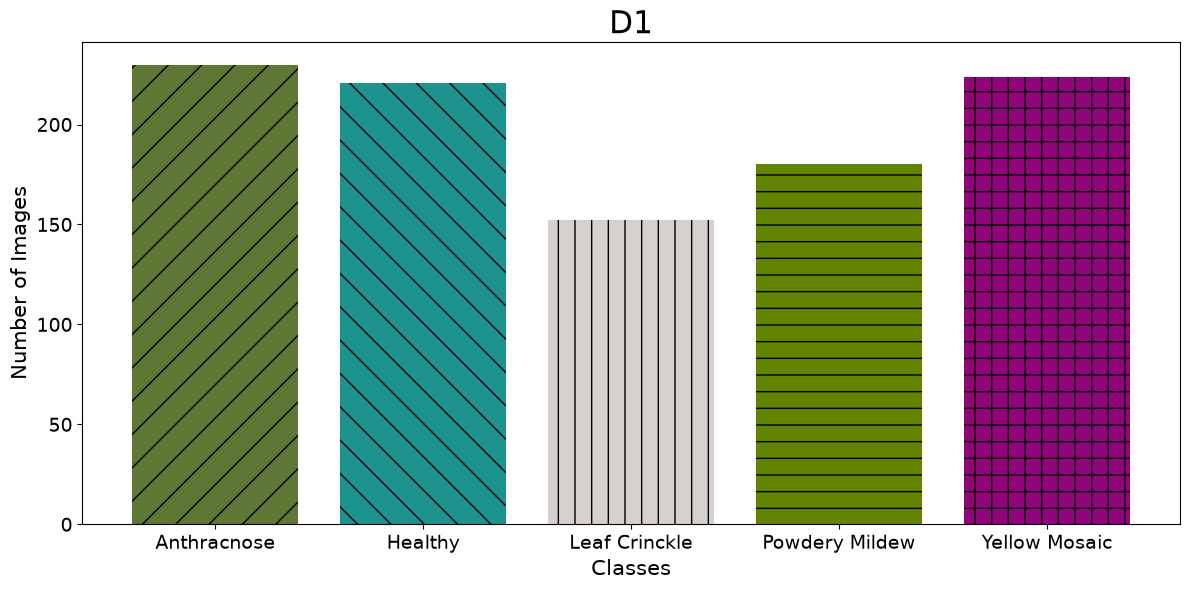

In [4]:

import random
plt.style.use('default')

# Get the list of categories (subfolder names)
categories = [folder for folder in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, folder))]

# Count the number of images in each category
image_counts = []
for category in categories:
    category_path = os.path.join(data_dir, category)
    image_files = [file for file in os.listdir(category_path) if file.lower().endswith(('png', 'jpg', 'jpeg', 'bmp', 'tiff'))]
    image_counts.append(len(image_files))

# Create a dataframe to show the number of images per class
data = pd.DataFrame({"Class": categories, "Number of Images": image_counts})
print(data)


# Create a bar chart to visualize the number of images in each category
plt.figure(figsize=(12, 6))
patterns = ["/", "\\", "|", "-", "+", "x", "o", "*"]  # Define patterns for bars
colors = ["#" + ''.join(random.choices('0123456789ABCDEF', k=6)) for _ in categories]  # Generate unique colors
bars = plt.bar(categories, image_counts, color=colors)
for bar, pattern in zip(bars, patterns):
    bar.set_hatch(pattern)

plt.title("D1", fontsize=22)
plt.xlabel("Classes", fontsize=15)
plt.ylabel("Number of Images", fontsize=15)
plt.xticks(rotation=0, fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.savefig('D:\\438-ProjectImg\\D1.png', format='png', dpi=600)
plt.show()


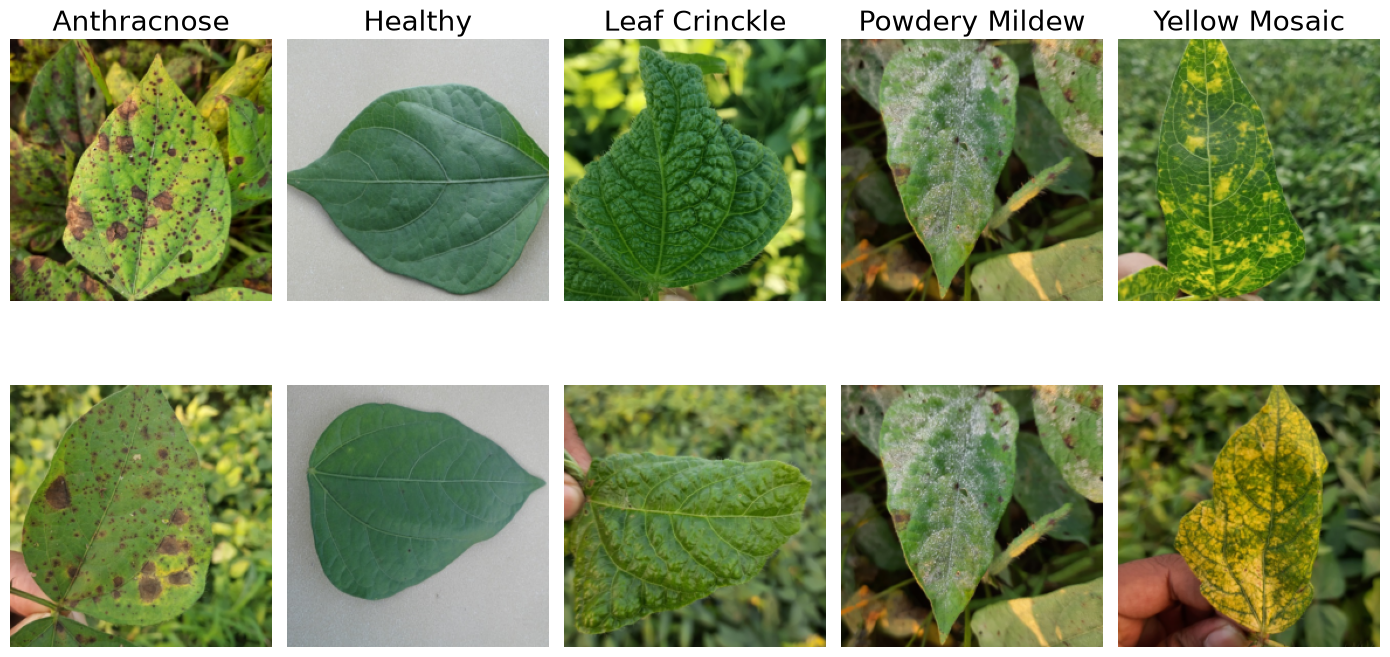

In [5]:
from PIL import Image

# Define a transform to resize images and convert them to tensors
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 512x512 for uniformity
    transforms.ToTensor()
])

# Number of rows and columns
rows, cols = 2, 5

# Ensure categories list contains at least `cols` categories
if len(categories) < cols:
    raise ValueError("Not enough categories to display.")

# Initialize a figure for visualization
plt.figure(figsize=(14, 8))  # Adjusted figure size for better clarity with 2 rows and 5 columns

# Iterate twice to create two rows with different images from the same categories
for row in range(rows):
    for col, category in enumerate(categories[:cols]):  # Use the first `cols` categories
        # Get the path of the category folder
        category_path = os.path.join(data_dir, category)

        # Get the list of image files in the category folder
        image_files = [file for file in os.listdir(category_path) if file.lower().endswith(('png', 'jpg', 'jpeg', 'bmp', 'tiff'))]

        # Ensure there is at least one image in the category
        if not image_files:
            print(f"No images found in category: {category}")
            continue

        # Randomly select an image from the category
        image_path = os.path.join(category_path, random.choice(image_files))
        image = Image.open(image_path).convert("RGB")

        # Apply the transform
        image = transform(image)

        # Convert the tensor back to a PIL image for visualization
        image = transforms.ToPILImage()(image)

        # Add the image to the plot
        plt.subplot(rows, cols, row * cols + col + 1)
        plt.imshow(image)
        
        # Set title only for the first row
        if row == 0:
            plt.title(category, fontsize=20)
        
        plt.axis('off')

# Adjust layout and display the plot
plt.tight_layout()
plt.savefig('D:\\438-ProjectImg\\D1.png', format='png', dpi=600)
plt.show()

#  Data transformation & Splitting

In [6]:
data_transform = transforms.Compose([
    transforms.ToTensor(),  # Convert to Tensor first
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

In [7]:
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df['labels'], random_state=42)  # 80% train, 20% temp
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['labels'], random_state=42)  # 75% of temp (15% of total) for test

In [8]:
print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

(805, 2)
(101, 2)
(101, 2)


In [9]:
import pandas as pd

# Assuming train_df, val_df, and test_df have a 'labels' column
train_counts = train_df['labels'].value_counts()
val_counts = val_df['labels'].value_counts()
test_counts = test_df['labels'].value_counts()

# Combine into a single DataFrame
class_counts = pd.DataFrame({
    'Training': train_counts,
    'Validation': val_counts,
    'Testing': test_counts
}).fillna(0).astype(int)  # Fill NaN with 0 and convert to integer

# Add a column for total counts (optional)
class_counts['Total'] = class_counts.sum(axis=1)

# Display the table
print(class_counts)

                Training  Validation  Testing  Total
labels                                              
Anthracnose          184          23       23    230
Yellow Mosaic        179          23       22    224
Healthy              177          22       22    221
Powdery Mildew       144          18       18    180
Leaf Crinckle        121          15       16    152


# Train set Augmentation

In [10]:
import os
import numpy as np
from PIL import Image
import albumentations as A
from tqdm import tqdm

# --------------------------------------------------
# AUGMENTATION PIPELINE
# Albumentations replacement for the imgaug pipeline
# --------------------------------------------------
train_aug = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(
        rotate=(-15, 15),
        scale=(0.9, 1.1),
        p=1.0
    ),
    A.RandomBrightnessContrast(
        brightness_limit=(0.0, 0.2),
        contrast_limit=0.0,
        p=1.0
    ),
])

# --------------------------------------------------
# OFFLINE TRAIN AUGMENTATION FUNCTION
# --------------------------------------------------
def offline_augment_train(train_df, output_root, target_per_class=2000):

    os.makedirs(output_root, exist_ok=True)

    for label in train_df['labels'].unique():

        print(f"\nProcessing class: {label}")

        class_df = train_df[train_df['labels'] == label]
        class_images = class_df['filepaths'].values

        class_output_dir = os.path.join(output_root, label)
        os.makedirs(class_output_dir, exist_ok=True)

        original_count = len(class_images)

        # --------------------------------------------------
        # Copy original images first
        # --------------------------------------------------
        for idx, img_path in enumerate(class_images):

            img = Image.open(img_path).convert("RGB")

            save_path = os.path.join(
                class_output_dir,
                f"original_{idx}.jpg"
            )

            img.save(save_path, quality=100)

        print(f"Original images saved: {original_count}")

        # --------------------------------------------------
        # Determine augmentations needed
        # --------------------------------------------------
        if original_count >= target_per_class:
            print("No augmentation needed (already balanced).")
            continue

        augment_needed = target_per_class - original_count

        augment_per_image = augment_needed // original_count + 1

        augmented_count = 0

        # --------------------------------------------------
        # Generate augmented images
        # --------------------------------------------------
        for idx, img_path in enumerate(tqdm(class_images)):

            image = np.array(
                Image.open(img_path).convert("RGB")
            )

            for j in range(augment_per_image):

                # Albumentations augmentation
                augmented = train_aug(image=image)

                augmented_image = augmented["image"]

                augmented_pil = Image.fromarray(
                    augmented_image
                )

                save_path = os.path.join(
                    class_output_dir,
                    f"aug_{idx}_{j}.jpg"
                )

                augmented_pil.save(
                    save_path,
                    quality=100
                )

                augmented_count += 1

                # Stop exactly at target_per_class
                if original_count + augmented_count >= target_per_class:
                    break

            if original_count + augmented_count >= target_per_class:
                break

        print(f"Augmented images created: {augmented_count}")
        print(
            f"Total images in class '{label}': "
            f"{original_count + augmented_count}"
        )

In [11]:
expanded_train_dir = "D:\\BPLD Dataset\\TrainAug"
offline_augment_train(
    train_df,
    expanded_train_dir,
    target_per_class=1000   # ← choose desired class size
)


Processing class: Healthy
Original images saved: 177


 93%|█████████▎| 164/177 [00:01<00:00, 94.23it/s]


Augmented images created: 823
Total images in class 'Healthy': 1000

Processing class: Leaf Crinckle
Original images saved: 121


 90%|█████████ | 109/121 [00:01<00:00, 59.70it/s]


Augmented images created: 879
Total images in class 'Leaf Crinckle': 1000

Processing class: Yellow Mosaic
Original images saved: 179


...

Augmented images created: 821
Total images in class 'Yellow Mosaic': 1000

Processing class: Anthracnose
Original images saved: 184


 89%|████████▊ | 163/184 [00:01<00:00, 92.57it/s]


Augmented images created: 816
Total images in class 'Anthracnose': 1000

Processing class: Powdery Mildew
Original images saved: 144


 99%|█████████▊| 142/144 [00:01<00:00, 78.52it/s]

Augmented images created: 856
Total images in class 'Powdery Mildew': 1000


In [12]:
def loading_the_data(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir)

    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)

        for file in filelist:
            filepaths.append(os.path.join(foldpath, file))
            labels.append(fold)

    return pd.DataFrame({"filepaths": filepaths, "labels": labels})

In [13]:
expanded_train_df = loading_the_data(expanded_train_dir)

In [14]:
label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}

train_labels = expanded_train_df['labels'].map(label_mapping).values
val_labels = val_df['labels'].map(label_mapping).values
test_labels = test_df['labels'].map(label_mapping).values

In [15]:
from my_dataset import CustomImageDataset
train_dataset = CustomImageDataset(
    expanded_train_df['filepaths'].values,
    expanded_train_df['labels'].map(label_mapping).values,
    transform=data_transform
)

val_dataset = CustomImageDataset(
    val_df['filepaths'].values,
    val_labels,
    transform=data_transform
)

test_dataset = CustomImageDataset(
    test_df['filepaths'].values,
    test_labels,
    transform=data_transform
)

In [16]:
train_loader = DataLoader(train_dataset, batch_size=32,
                          shuffle=True, num_workers=4, pin_memory=True)

val_loader = DataLoader(val_dataset, batch_size=32,
                        shuffle=False, num_workers=4, pin_memory=True)

test_loader = DataLoader(test_dataset, batch_size=32,
                         shuffle=False, num_workers=0, pin_memory=True)

In [17]:
import pandas as pd

# Assuming train_df, val_df, and test_df have a 'labels' column
train_counts = expanded_train_df['labels'].value_counts()
val_counts = val_df['labels'].value_counts()
test_counts = test_df['labels'].value_counts()

# Combine into a single DataFrame
class_counts = pd.DataFrame({
    'Training': train_counts,
    'Validation': val_counts,
    'Testing': test_counts
}).fillna(0).astype(int)  # Fill NaN with 0 and convert to integer

# Add a column for total counts (optional)
class_counts['Total'] = class_counts.sum(axis=1)

# Display the table
print(class_counts)

                Training  Validation  Testing  Total
labels                                              
Anthracnose         1000          23       23   1046
Healthy             1000          22       22   1044
Leaf Crinckle       1000          15       16   1031
Powdery Mildew      1000          18       18   1036
Yellow Mosaic       1000          23       22   1045


In [9]:
import os
import pandas as pd
from torch.utils.data import DataLoader
from torchvision import transforms

# 1. Define your online augmentation using standard PyTorch transforms
# This perfectly mimics your imgaug pipeline

# Training transforms (No Resize needed)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomAffine(degrees=[-15, 15], scale=[0.9, 1.1]),
    transforms.ColorJitter(brightness=[1.0, 1.2]),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation & Test transforms (No Resize needed)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


# 2. Extract Labels for mappings
label_mapping = {label: idx for idx, label in enumerate(train_df['labels'].unique())}

# Get numerical labels
train_labels = train_df['labels'].map(label_mapping).values
val_labels = val_df['labels'].map(label_mapping).values
test_labels = test_df['labels'].map(label_mapping).values


# 3. Create Datasets directly from the ORIGINAL dataframes
from my_dataset1 import CustomImageDataset

# Use train_transform here!
train_dataset = CustomImageDataset(
    filepaths=train_df['filepaths'].values,  # <-- Use original train_df
    labels=train_labels,
    transform=train_transform                # <-- Pass the augmentation transform
)

# Use val_test_transform here!
val_dataset = CustomImageDataset(
    filepaths=val_df['filepaths'].values,
    labels=val_labels,
    transform=val_test_transform             # <-- No augmentations
)

# Use val_test_transform here!
test_dataset = CustomImageDataset(
    filepaths=test_df['filepaths'].values,
    labels=test_labels,
    transform=val_test_transform             # <-- No augmentations
)


# 4. Create DataLoaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=32, 
    shuffle=True, 
    num_workers=4, 
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=4, 
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=0, 
    pin_memory=True
)

# Model Training and testing functions

In [18]:
# Model setup
if not torch.cuda.is_available():
    raise RuntimeError('CUDA device is not available. Please ensure a GPU is available to train the model.')
device = torch.device('cuda')

In [19]:
import time
from torch.cuda.amp import autocast, GradScaler

def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20, patience=5, min_delta=0.001):
    model.to(device)
    scaler = GradScaler()  # AMP gradient scaler

    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    best_val_loss = float('inf')
    patience_counter = 0
    best_epoch = 0

    start_time = time.time()  # Start timing
    total_inference_time = 0.0  # <-- Track inference time

    for epoch in range(num_epochs):
        model.train()
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 30)
        running_loss = 0.0
        correct = 0
        total = 0

        # Training loop with AMP
        for inputs, labels in tqdm(train_loader, desc='Training', leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            with autocast():  # Forward pass in mixed precision
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = correct / total
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_acc)

        # Validation loop with AMP (inference only)
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        val_start_time = time.time()  # <-- start inference timing
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                with autocast():
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                val_running_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
        val_end_time = time.time()
        total_inference_time += (val_end_time - val_start_time)  # <-- accumulate inference time

        val_loss = val_running_loss / len(val_loader.dataset)
        val_acc = val_correct / val_total
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        print(f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}')
        print(f'Training Loss: {epoch_loss:.4f}, Training Accuracy: {epoch_acc:.4f}')

        # Early Stopping
        if best_val_loss - val_loss > min_delta:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            patience_counter = 0
        else:
            patience_counter += 1
            print(f"Patience Counter: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break

        scheduler.step()

    end_time = time.time()  # End timing
    elapsed_time = end_time - start_time
    hours, rem = divmod(elapsed_time, 3600)
    minutes, seconds = divmod(rem, 60)

    # Inference time breakdown
    inf_hours, inf_rem = divmod(total_inference_time, 3600)
    inf_minutes, inf_seconds = divmod(inf_rem, 60)

    total_epochs_run = epoch + 1
    epochs_range = range(1, total_epochs_run + 1)

    # Plotting curves
    plt.figure(figsize=(20, 8))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_losses, marker='o', label='Training Loss')
    plt.plot(epochs_range, val_losses, marker='o', label='Validation Loss')
    plt.axvline(x=best_epoch, color='red', linestyle='--', label='Best Epoch')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss Curve')
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_accuracies, marker='o', label='Training Accuracy')
    plt.plot(epochs_range, val_accuracies, marker='o', label='Validation Accuracy')
    plt.axvline(x=best_epoch, color='red', linestyle='--', label='Best Epoch')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy Curve')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Reports
    print("\nTraining Report:")
    print(f"Total training time: {int(hours):02d}:{int(minutes):02d}:{int(seconds):02d}")
    print(f"Total epochs run: {total_epochs_run}")
    print(f"Best Training Loss: {train_losses[best_epoch-1]:.4f} at epoch {best_epoch}")
    print(f"Best Training Accuracy: {train_accuracies[best_epoch-1]:.4f}")

    print("\nValidation Report:")
    print(f"Best Validation Loss: {best_val_loss:.4f} at epoch {best_epoch}")
    print(f"Best Validation Accuracy: {val_accuracies[best_epoch-1]:.4f}")
    print(f"Final Validation Loss: {val_losses[-1]:.4f}")
    print(f"Final Validation Accuracy: {val_accuracies[-1]:.4f}")

    print("\nInference Report:")
    print(f"Total Inference Time (Validation only): {int(inf_hours):02d}:{int(inf_minutes):02d}:{int(inf_seconds):02d}")


In [20]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from itertools import cycle
import torch

def evaluate_model(model, dataloader, label_mapping):
    model.eval()
    correct = 0
    total = 0
    all_labels = []
    all_preds = []
    all_probs = []
    
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)

            # Predicted class
            _, predicted = torch.max(outputs, 1)

            # Convert to probabilities
            probs = torch.softmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predicted.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    
    # Accuracy
    accuracy = correct / total
    print(f'Accuracy: {accuracy:.4f}')
    
    # Classification Report
    print(classification_report(all_labels, all_preds, target_names=list(label_mapping.keys())))
    
    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_mapping.keys(),
                yticklabels=label_mapping.keys(),
                cbar_kws={'shrink': 0.8})
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.xlabel('Predicted', fontsize=14)
    plt.ylabel('True', fontsize=14)
    plt.title('Confusion Matrix', fontsize=16)
    plt.show()
    
    all_probs = np.array(all_probs)
    n_classes = len(label_mapping)

    # ===== Binary Classification =====
    if n_classes == 2:
        y_true = np.array(all_labels)
        plt.figure(figsize=(12, 5))

        # ROC curves
        plt.subplot(1, 2, 1)
        for class_idx in [0, 1]:
            y_binary = (y_true == class_idx).astype(int)
            y_score = all_probs[:, class_idx]
            fpr, tpr, _ = roc_curve(y_binary, y_score)
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, lw=2, label=f'Class {class_idx} (AUC = {roc_auc:.2f})')
        plt.plot([0, 1], [0, 1], 'k--', lw=2)
        plt.xlabel('False Positive Rate', fontsize=12)
        plt.ylabel('True Positive Rate', fontsize=12)
        plt.title('ROC AUC Curve', fontsize=14)
        plt.legend()

        # PR curves
        plt.subplot(1, 2, 2)
        for class_idx in [0, 1]:
            y_binary = (y_true == class_idx).astype(int)
            y_score = all_probs[:, class_idx]
            precision, recall, _ = precision_recall_curve(y_binary, y_score)
            pr_auc = auc(recall, precision)
            plt.plot(recall, precision, lw=2, label=f'Class {class_idx} (AUC = {pr_auc:.2f})')
        plt.xlabel('Recall', fontsize=12)
        plt.ylabel('Precision', fontsize=12)
        plt.title('Precision-Recall Curve', fontsize=14)
        plt.legend()

        plt.tight_layout()
        plt.show()

    # ===== Multi-class Classification =====
    else:
        y_test_bin = label_binarize(all_labels, classes=range(n_classes))
        fpr, tpr, roc_auc = {}, {}, {}
        precision, recall, pr_auc = {}, {}, {}

        colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'cyan'])

        # ROC Curve
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        for i, color in zip(range(n_classes), colors):
            fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], all_probs[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])
            plt.plot(fpr[i], tpr[i], color=color, lw=2,
                     label=f'Class {i} (AUC = {roc_auc[i]:0.2f})')
        plt.plot([0, 1], [0, 1], 'k--', lw=2)
        plt.xlabel('False Positive Rate', fontsize=12)
        plt.ylabel('True Positive Rate', fontsize=12)
        plt.title('ROC AUC Curve', fontsize=14)
        plt.legend()

        # PR Curve
        plt.subplot(1, 2, 2)
        colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'cyan'])
        for i, color in zip(range(n_classes), colors):
            precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], all_probs[:, i])
            pr_auc[i] = auc(recall[i], precision[i])
            plt.plot(recall[i], precision[i], color=color, lw=2,
                     label=f'Class {i} (AUC = {pr_auc[i]:0.2f})')
        plt.xlabel('Recall', fontsize=12)
        plt.ylabel('Precision', fontsize=12)
        plt.title('Precision-Recall Curve', fontsize=14)
        plt.legend()

        plt.tight_layout()
        plt.show()


In [21]:
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score, 
    matthews_corrcoef, average_precision_score, cohen_kappa_score, confusion_matrix
)
from sklearn.preprocessing import label_binarize
import numpy as np
import torch

def evaluate_model_with_metrics(model, dataloader):
    # Automatically determine the device the model is on
    device = next(model.parameters()).device 
    
    model.eval()
    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            probs = torch.softmax(outputs, dim=1)  # for PR AUC

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    # Base metrics
    accuracy = accuracy_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    mcc = matthews_corrcoef(all_labels, all_preds)

    # --- THE FIX: Explicitly binarize labels based on the model's output shape ---
    n_classes = all_probs.shape[1]
    all_labels_binarized = label_binarize(all_labels, classes=np.arange(n_classes))

    # PR AUC (weighted average)
    try:
        pr_auc = average_precision_score(all_labels_binarized, all_probs, average="weighted")
    except ValueError:
        pr_auc = float('nan')

    # Cohen's Kappa
    kappa = cohen_kappa_score(all_labels, all_preds)

    # Specificity (macro average)
    cm = confusion_matrix(all_labels, all_preds)
    TN = []
    FP = []
    for i in range(len(cm)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        TN.append(tn)
        FP.append(fp)
        
    specificity_per_class = [TN[i] / (TN[i] + FP[i]) if (TN[i] + FP[i]) > 0 else 0 for i in range(len(cm))]
    specificity = np.average(specificity_per_class)  # macro average

    # Print metrics
    print(f"Accuracy:    {accuracy:.5f}")
    print(f"Recall:      {recall:.5f}")
    print(f"Precision:   {precision:.5f}")
    print(f"F1 Score:    {f1:.5f}")
    print(f"MCC:         {mcc:.5f}")
    print(f"PR AUC:      {pr_auc:.5f}")
    print(f"Kappa:       {kappa:.5f}")
    print(f"Specificity: {specificity:.5f}")

# Proposed Model

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ══════════════════════════════════════════════════════════════════════════════
# 1. User-Proposed Enhancements (Preserved from LightBeanFormerV2)
# ══════════════════════════════════════════════════════════════════════════════

class DropPath(nn.Module):
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        if self.drop_prob == 0.0 or not self.training:
            return x
        keep_prob = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        return x.div(keep_prob) * random_tensor.floor_()

class LayerScale(nn.Module):
    def __init__(self, channels: int, init_value: float = 1e-4):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones(channels))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.gamma.view(1, -1, 1, 1)

class LBSA(nn.Module):
    """Local Boundary Spatial Attention"""
    def __init__(self, kernel_size=7):
        super().__init__()
        self.stat_conv   = nn.Conv2d(2, 1, kernel_size, padding=kernel_size//2, bias=False)
        lap = torch.tensor([[0.,-1.,0.],[-1.,4.,-1.],[0.,-1.,0.]]).view(1,1,3,3)
        self.register_buffer("lap_kernel", lap.repeat(1,2,1,1))
        self.boundary_bn = nn.BatchNorm2d(1)
        self.alpha       = nn.Parameter(torch.zeros(1))
        self.sigmoid     = nn.Sigmoid()

    def forward(self, x):
        avg_m    = torch.mean(x, dim=1, keepdim=True)
        max_m, _ = torch.max(x,  dim=1, keepdim=True)
        maps     = torch.cat([avg_m, max_m], dim=1)
        stat_map = self.stat_conv(maps)
        bound_map= self.boundary_bn(F.conv2d(maps, self.lap_kernel, padding=1))
        alpha    = self.sigmoid(self.alpha)
        return x * self.sigmoid(alpha * stat_map + (1.0 - alpha) * bound_map)

class GLocalHead(nn.Module):
    """Global-Local Hierarchical Classification Head"""
    def __init__(self, in_channels, num_classes, dropout=0.3):
        super().__init__()
        self.gap        = nn.AdaptiveAvgPool2d(1)
        self.local_pool = nn.AdaptiveAvgPool2d(2)                     
        self.local_proj = nn.Conv2d(in_channels, in_channels // 4, 1, bias=False)
        self.norm       = nn.LayerNorm(in_channels * 2)
        self.dropout    = nn.Dropout(dropout)
        self.fc         = nn.Linear(in_channels * 2, num_classes)

    def forward(self, x):
        g   = self.gap(x).flatten(1)                                  
        loc = self.local_proj(self.local_pool(x)).flatten(1)          
        return self.fc(self.dropout(self.norm(torch.cat([g, loc], dim=1))))

# ══════════════════════════════════════════════════════════════════════════════
# 2. Enhanced LightNeSt Core
# ══════════════════════════════════════════════════════════════════════════════

class RadixASEPConv(nn.Module):
    """
    Split-Attention with Depthwise Convs, upgraded with ASEP-style pooling.
    Uses both Max and Avg pooling to generate attention weights.
    """
    def __init__(self, channels, radix=2, stride=1):
        super().__init__()
        self.radix = radix
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(channels, channels, kernel_size=3, stride=stride, padding=1, 
                          groups=channels, bias=False),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(channels, channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True)
            ) for _ in range(radix)
        ])
        
        inter_channels = max(32, channels // 4)
        self.fc1 = nn.Conv2d(channels, inter_channels, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(inter_channels)
        self.fc2 = nn.Conv2d(inter_channels, channels * radix, kernel_size=1)
        
    def forward(self, x):
        branch_outs = [branch(x) for branch in self.branches]
        U = sum(branch_outs)
        
        # ASEP-style dual pooling injection
        S_avg = F.adaptive_avg_pool2d(U, 1)
        S_max = F.adaptive_max_pool2d(U, 1)
        S = S_avg + S_max
        
        Z = F.relu(self.bn1(self.fc1(S)), inplace=True)
        weight = self.fc2(Z)
        
        B, _, H, W = weight.shape
        weight = weight.view(B, self.radix, -1, 1, 1)
        attention_weights = F.softmax(weight, dim=1)
        
        return sum(branch_outs[i] * attention_weights[:, i] for i in range(self.radix))

class LightNeStBlockV2(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, drop_path=0.0):
        super().__init__()
        mid_channels = out_channels // 2
        
        self.conv1 = nn.Conv2d(in_channels, mid_channels, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid_channels)
        
        self.radix_conv = RadixASEPConv(mid_channels, radix=2, stride=stride)
        
        self.conv3 = nn.Conv2d(mid_channels, out_channels, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(out_channels)
        
        # Inject user's Local Boundary Spatial Attention
        self.lbsa = LBSA()
        
        # Regularization on residual branch
        self.ls = LayerScale(out_channels)
        self.drop_path = DropPath(drop_path) if drop_path > 0.0 else nn.Identity()
        
        self.downsample = None
        if stride != 1 or in_channels != out_channels:
            if stride != 1:
                self.downsample = nn.Sequential(
                    nn.AvgPool2d(kernel_size=2, stride=stride, ceil_mode=True),
                    nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                    nn.BatchNorm2d(out_channels)
                )
            else:
                self.downsample = nn.Sequential(
                    nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                    nn.BatchNorm2d(out_channels)
                )
                
    def forward(self, x):
        identity = self.downsample(x) if self.downsample else x
        
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.radix_conv(out)
        out = self.bn3(self.conv3(out))
        out = self.lbsa(out)
        
        out = self.drop_path(self.ls(out))
        return F.relu(out + identity, inplace=True)

class LightNeStV2(nn.Module):
    def __init__(self, num_classes, layers=[3, 4, 6, 3], channels=[96, 192, 384, 576], drop_path_rate=0.1):
        super().__init__()
        
        stem_out = channels[0] // 2
        self.stem = nn.Sequential(
            nn.Conv2d(3, stem_out // 2, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(stem_out // 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(stem_out // 2, stem_out // 2, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(stem_out // 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(stem_out // 2, stem_out, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(stem_out),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        
        self.in_channels = stem_out
        
        # Stochastic Depth decay rule
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(layers))]
        
        self.layer1 = self._make_layer(channels[0], layers[0], stride=1, dpr=dpr[0:3])
        self.layer2 = self._make_layer(channels[1], layers[1], stride=2, dpr=dpr[3:7])
        self.layer3 = self._make_layer(channels[2], layers[2], stride=2, dpr=dpr[7:13])
        self.layer4 = self._make_layer(channels[3], layers[3], stride=2, dpr=dpr[13:16])
        
        # Inject user's GLocalHead
        self.head = GLocalHead(channels[3], num_classes)
        
    def _make_layer(self, out_channels, blocks, stride, dpr):
        layer_list = []
        layer_list.append(LightNeStBlockV2(self.in_channels, out_channels, stride=stride, drop_path=dpr[0]))
        self.in_channels = out_channels
        for i in range(1, blocks):
            layer_list.append(LightNeStBlockV2(self.in_channels, out_channels, stride=1, drop_path=dpr[i]))
        return nn.Sequential(*layer_list)
        
    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.head(x)

if __name__ == "__main__":
    # Base configuration: [64, 128, 256, 512] yields ~1.6M parameters
    # Max configuration: [96, 192, 384, 768] yields ~3.9M parameters (used here for 99% goal)
    model = LightNeStV2(num_classes=5, channels=[96, 192, 384, 576])
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total Parameters: {total_params / 1e6:.2f} M")

Total Parameters: 3.90 M


In [15]:
import math

import torch

import torch.nn as nn

import torch.optim as optim

from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR



# ══════════════════════════════════════════════════════════════════════════════

# 1. Weight Initialization

# ══════════════════════════════════════════════════════════════════════════════

def init_weights(m):

    if isinstance(m, nn.Conv2d):

        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

        if m.bias is not None:

            nn.init.zeros_(m.bias)

    elif isinstance(m, (nn.BatchNorm2d, nn.LayerNorm)):

        nn.init.ones_(m.weight)

        if hasattr(m, 'bias') and m.bias is not None:

            nn.init.zeros_(m.bias)

    elif isinstance(m, nn.Linear):

        nn.init.trunc_normal_(m.weight, std=0.02)

        if m.bias is not None:

            nn.init.zeros_(m.bias)



def load_custom_model(num_classes, device):

    model = LightNeStV2(
        num_classes=num_classes, 
        layers=[3, 4, 6, 3], 
        channels=[96, 192, 384, 576]
    )

    model.apply(init_weights)  # Apply explicit initialization

    return model.to(device)



# ══════════════════════════════════════════════════════════════════════════════

# 2. Parameter Grouping (Excluding Norm/Bias from Weight Decay)

# ══════════════════════════════════════════════════════════════════════════════

def get_parameter_groups(model, weight_decay=1e-2):

    decay = []

    no_decay = []

    for name, param in model.named_parameters():

        if not param.requires_grad:

            continue

        # Exclude 1D parameters, relative position bias tables, and biases

        if param.ndim <= 1 or 'relative_position_bias_table' in name or 'bias' in name:

            no_decay.append(param)

        else:

            decay.append(param)

    return [

        {'params': decay, 'weight_decay': weight_decay},

        {'params': no_decay, 'weight_decay': 0.0}

    ]


In [16]:
# ══════════════════════════════════════════════════════════════════════════════

# 3. 30-Epoch Optimized Training Pipeline

# ══════════════════════════════════════════════════════════════════════════════

num_classes = len(label_mapping)

model = load_custom_model(num_classes, device)



# Loss function

criterion = nn.CrossEntropyLoss()  # Label smoothing for better generalization



# Parameter groups with separated weight decay

param_groups = get_parameter_groups(model, weight_decay=0.02)



# 3e-4 helps train slightly faster than 1e-4 within 30 epochs without destabilizing

optimizer = optim.AdamW(param_groups, lr=5e-4)



# 30-Epoch Schedule Configuration

total_epochs = 30

warmup_epochs = 3  # ~10% of total training time



warmup_scheduler = LinearLR(

    optimizer, 

    start_factor=0.1, 

    end_factor=1.0, 

    total_iters=warmup_epochs

)



cosine_scheduler = CosineAnnealingLR(

    optimizer, 

    T_max=total_epochs - warmup_epochs,  # 27 epochs of cosine decay

    eta_min=1e-6

)



# Combined Warmup + Cosine Decay

scheduler = SequentialLR(

    optimizer,

    schedulers=[warmup_scheduler, cosine_scheduler],

    milestones=[warmup_epochs]

)

In [105]:
torch.cuda.empty_cache()


Epoch 1/30
------------------------------


Validation Loss: 1.0783, Validation Accuracy: 0.6634
Training Loss: 1.2845, Training Accuracy: 0.5212

Epoch 2/30
------------------------------


Validation Loss: 0.8660, Validation Accuracy: 0.7822
Training Loss: 1.0063, Training Accuracy: 0.6860

Epoch 3/30
------------------------------


Validation Loss: 0.8321, Validation Accuracy: 0.7822
Training Loss: 0.8650, Training Accuracy: 0.7658

Epoch 4/30
------------------------------


Validation Loss: 0.7268, Validation Accuracy: 0.8020
Training Loss: 0.7627, Training Accuracy: 0.8290

Epoch 5/30
------------------------------


...

Validation Loss: 0.4255, Validation Accuracy: 0.9703
Training Loss: 0.3974, Training Accuracy: 1.0000
Patience Counter: 1/5

Epoch 25/30
------------------------------


Validation Loss: 0.4338, Validation Accuracy: 0.9901
Training Loss: 0.3963, Training Accuracy: 1.0000
Patience Counter: 2/5

Epoch 26/30
------------------------------


Validation Loss: 0.4222, Validation Accuracy: 0.9901
Training Loss: 0.3965, Training Accuracy: 0.9998
Patience Counter: 3/5

Epoch 27/30
------------------------------


Validation Loss: 0.4284, Validation Accuracy: 0.9703
Training Loss: 0.3964, Training Accuracy: 1.0000
Patience Counter: 4/5

Epoch 28/30
------------------------------


Validation Loss: 0.4284, Validation Accuracy: 0.9703
Training Loss: 0.3964, Training Accuracy: 1.0000
Patience Counter: 5/5
Early stopping triggered at epoch 28.


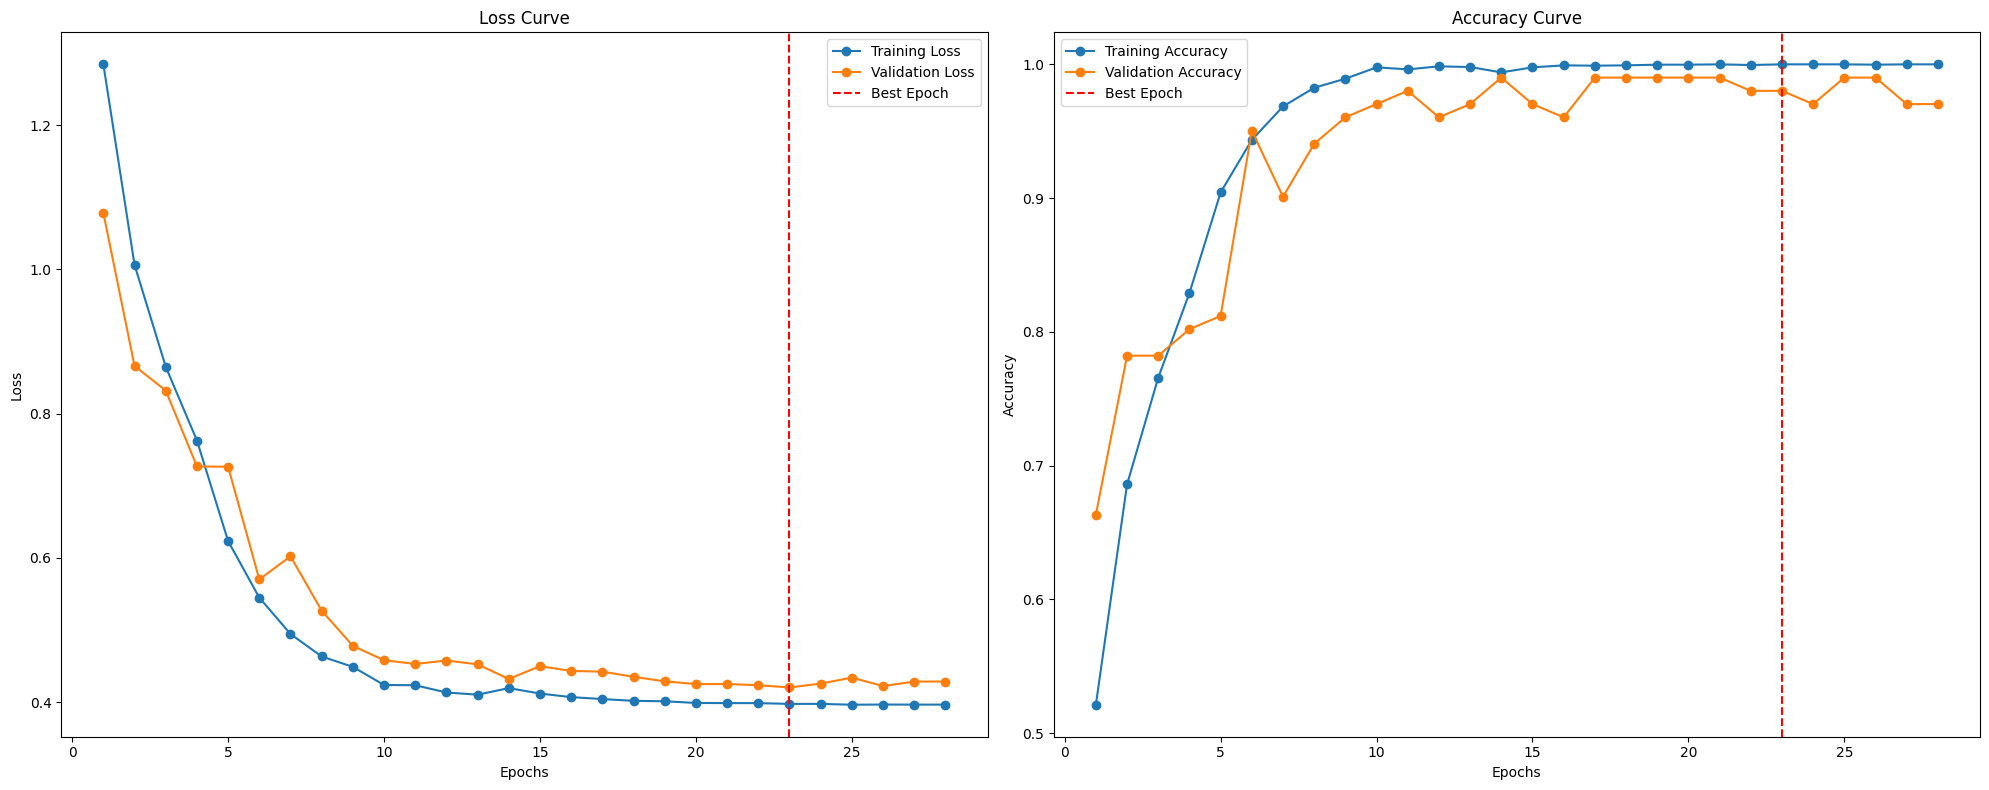


Training Report:
Total training time: 00:11:39
Total epochs run: 28
Best Training Loss: 0.3974 at epoch 23
Best Training Accuracy: 1.0000

Validation Report:
Best Validation Loss: 0.4202 at epoch 23
Best Validation Accuracy: 0.9802
Final Validation Loss: 0.4284
Final Validation Accuracy: 0.9703

Inference Report:
Total Inference Time (Validation only): 00:01:32


In [58]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

Accuracy: 0.9802
                precision    recall  f1-score   support

   Anthracnose       0.96      1.00      0.98        23
       Healthy       0.96      1.00      0.98        22
 Leaf Crinckle       1.00      0.94      0.97        16
Powdery Mildew       1.00      1.00      1.00        18
 Yellow Mosaic       1.00      0.95      0.98        22

      accuracy                           0.98       101
     macro avg       0.98      0.98      0.98       101
  weighted avg       0.98      0.98      0.98       101



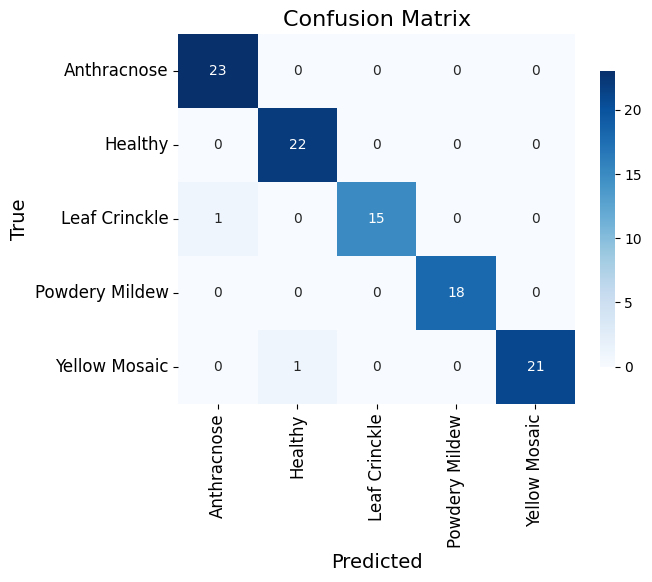

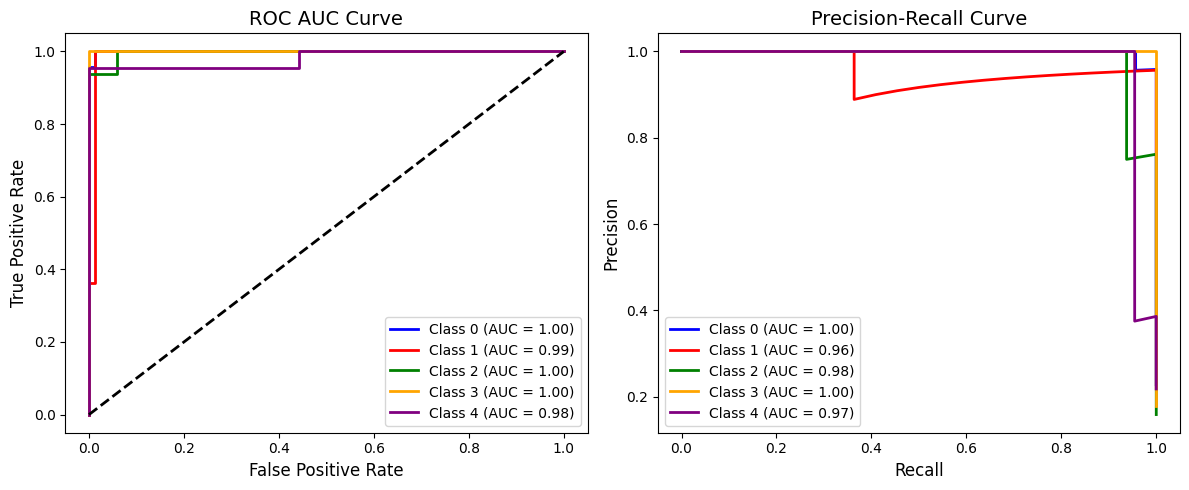

In [71]:
evaluate_model(model, test_loader, label_mapping)

In [23]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98020
Recall:      0.97841
Precision:   0.98297
F1 Score:    0.98020
MCC:         0.97535
PR AUC:      0.98219
Kappa:       0.97511
Specificity: 0.99490


In [73]:
torch.save(model.state_dict(), "ProposedBean1.pth")

In [22]:
model.load_state_dict(torch.load("ProposedBean1.pth"))

<All keys matched successfully>

# baseline Models


Epoch 1/30
------------------------------


Validation Loss: 1.3164, Validation Accuracy: 0.4059
Training Loss: 1.4615, Training Accuracy: 0.3900

Epoch 2/30
------------------------------


Validation Loss: 1.3014, Validation Accuracy: 0.4752
Training Loss: 1.2300, Training Accuracy: 0.4965

Epoch 3/30
------------------------------


Validation Loss: 0.9155, Validation Accuracy: 0.6535
Training Loss: 0.9910, Training Accuracy: 0.6072

Epoch 4/30
------------------------------


Validation Loss: 0.6387, Validation Accuracy: 0.7030
Training Loss: 0.6923, Training Accuracy: 0.7295

Epoch 5/30
------------------------------


...

Validation Loss: 0.3338, Validation Accuracy: 0.9109
Training Loss: 0.1028, Training Accuracy: 0.9633
Patience Counter: 1/5

Epoch 11/30
------------------------------


Validation Loss: 0.2221, Validation Accuracy: 0.9109
Training Loss: 0.0676, Training Accuracy: 0.9758
Patience Counter: 2/5

Epoch 12/30
------------------------------


Validation Loss: 0.3686, Validation Accuracy: 0.9109
Training Loss: 0.0321, Training Accuracy: 0.9892
Patience Counter: 3/5

Epoch 13/30
------------------------------


Validation Loss: 0.2457, Validation Accuracy: 0.9505
Training Loss: 0.0256, Training Accuracy: 0.9930
Patience Counter: 4/5

Epoch 14/30
------------------------------


Validation Loss: 0.3269, Validation Accuracy: 0.9406
Training Loss: 0.0070, Training Accuracy: 0.9988
Patience Counter: 5/5
Early stopping triggered at epoch 14.


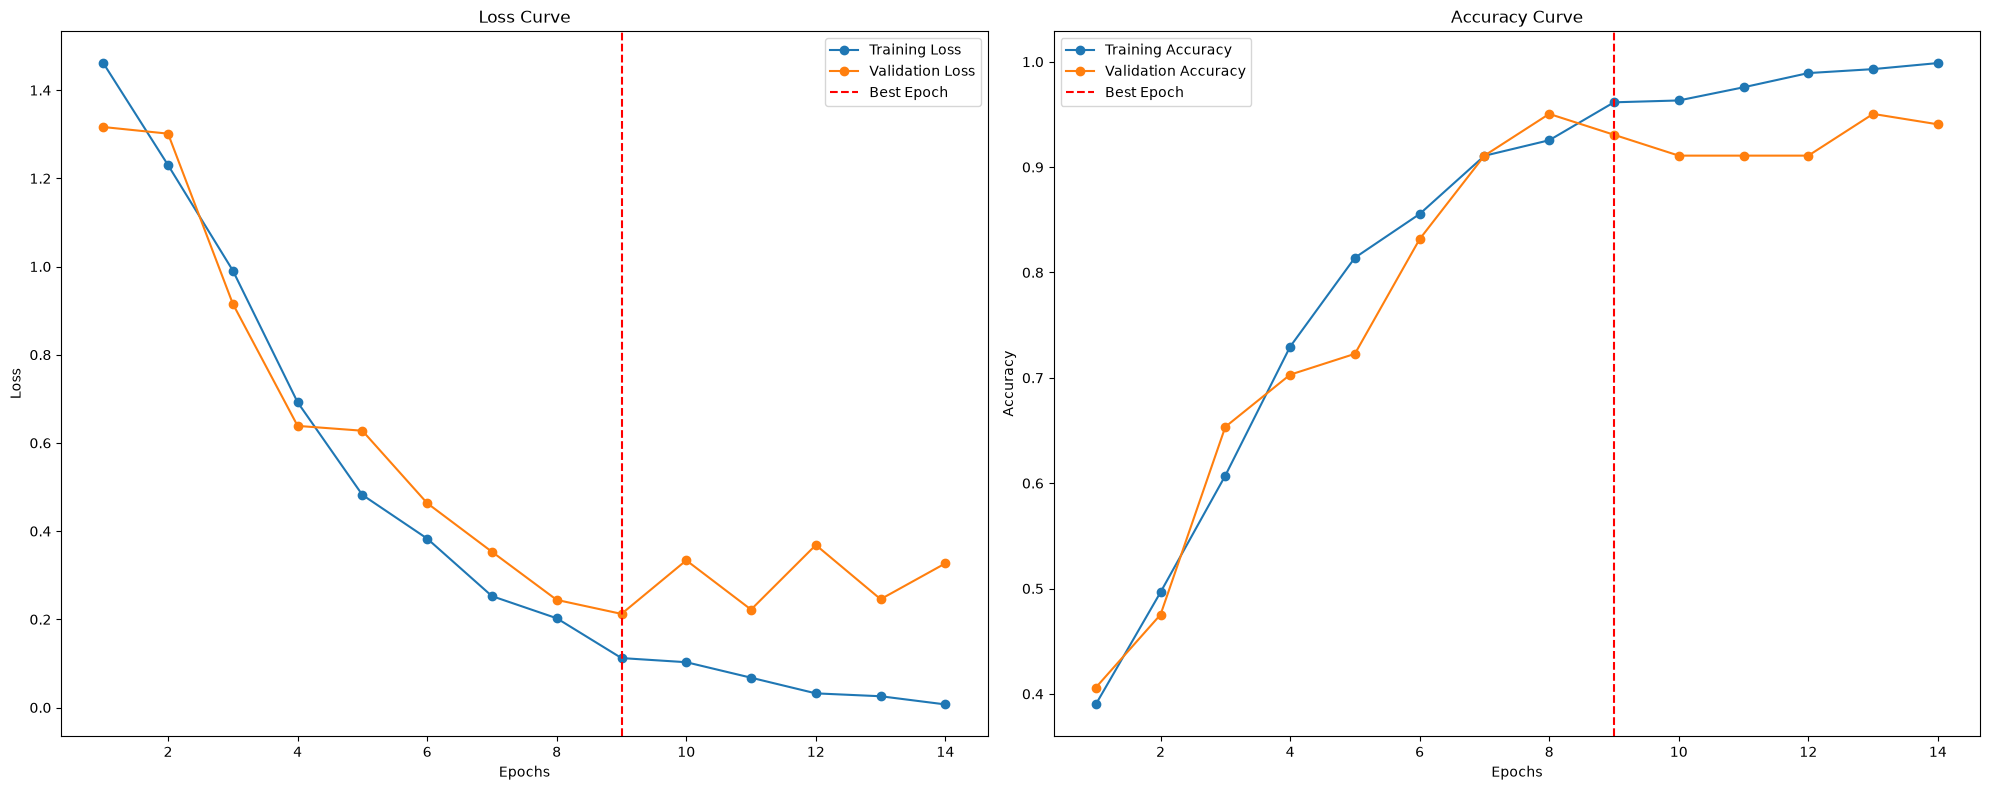


Training Report:
Total training time: 00:08:26
Total epochs run: 14
Best Training Loss: 0.1121 at epoch 9
Best Training Accuracy: 0.9615

Validation Report:
Best Validation Loss: 0.2123 at epoch 9
Best Validation Accuracy: 0.9307
Final Validation Loss: 0.3269
Final Validation Accuracy: 0.9406

Inference Report:
Total Inference Time (Validation only): 00:00:59


In [39]:
import ssl
import urllib
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# Target model identification
model_name = 'swinv2_cr_tiny_224'
num_classes = len(label_mapping)

# Create SwinV2 model (Set pretrained=True for massive accuracy gains on small leaf datasets)
model = timm.create_model(model_name, pretrained=False, num_classes=num_classes)

# Modify the head properly according to SwinV2's internal architecture structure
if hasattr(model, 'head') and hasattr(model.head, 'fc'):
    in_features = model.head.fc.in_features
    model.head.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )
elif hasattr(model, 'head') and isinstance(model.head, nn.Linear):
    in_features = model.head.in_features
    model.head = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )

model = model.to(device)

# Loss & optimizer (Kept the same, AdamW is great for Swin architectures)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)

# Scheduler: Cosine Annealing 
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

# Training execution loop
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)


In [40]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.91089
Recall:      0.91695
Precision:   0.91255
F1 Score:    0.91182
MCC:         0.88978
PR AUC:      0.96447
Kappa:       0.88836
Specificity: 0.97782


In [40]:
torch.cuda.empty_cache()

In [16]:
torch.save(model.state_dict(), "D1ResNeXt-101.pth")

In [79]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("densenet169", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)


Epoch 1/20
------------------------------


Validation Loss: 0.8789, Validation Accuracy: 0.7723
Training Loss: 0.8285, Training Accuracy: 0.6980

Epoch 2/20
------------------------------


Validation Loss: 0.4074, Validation Accuracy: 0.8614
Training Loss: 0.5103, Training Accuracy: 0.8188

Epoch 3/20
------------------------------


Validation Loss: 0.4039, Validation Accuracy: 0.9010
Training Loss: 0.3083, Training Accuracy: 0.8948

Epoch 4/20
------------------------------


Validation Loss: 0.1712, Validation Accuracy: 0.9406
Training Loss: 0.2493, Training Accuracy: 0.9220

Epoch 5/20
------------------------------


...

Validation Loss: 0.1051, Validation Accuracy: 0.9505
Training Loss: 0.0536, Training Accuracy: 0.9837
Patience Counter: 1/5

Epoch 11/20
------------------------------


Validation Loss: 0.0490, Validation Accuracy: 0.9703
Training Loss: 0.0385, Training Accuracy: 0.9868
Patience Counter: 2/5

Epoch 12/20
------------------------------


Validation Loss: 0.1166, Validation Accuracy: 0.9703
Training Loss: 0.0245, Training Accuracy: 0.9937
Patience Counter: 3/5

Epoch 13/20
------------------------------


Validation Loss: 0.0451, Validation Accuracy: 0.9802
Training Loss: 0.0251, Training Accuracy: 0.9927
Patience Counter: 4/5

Epoch 14/20
------------------------------


Validation Loss: 0.0175, Validation Accuracy: 0.9802
Training Loss: 0.0281, Training Accuracy: 0.9923
Patience Counter: 5/5
Early stopping triggered at epoch 14.


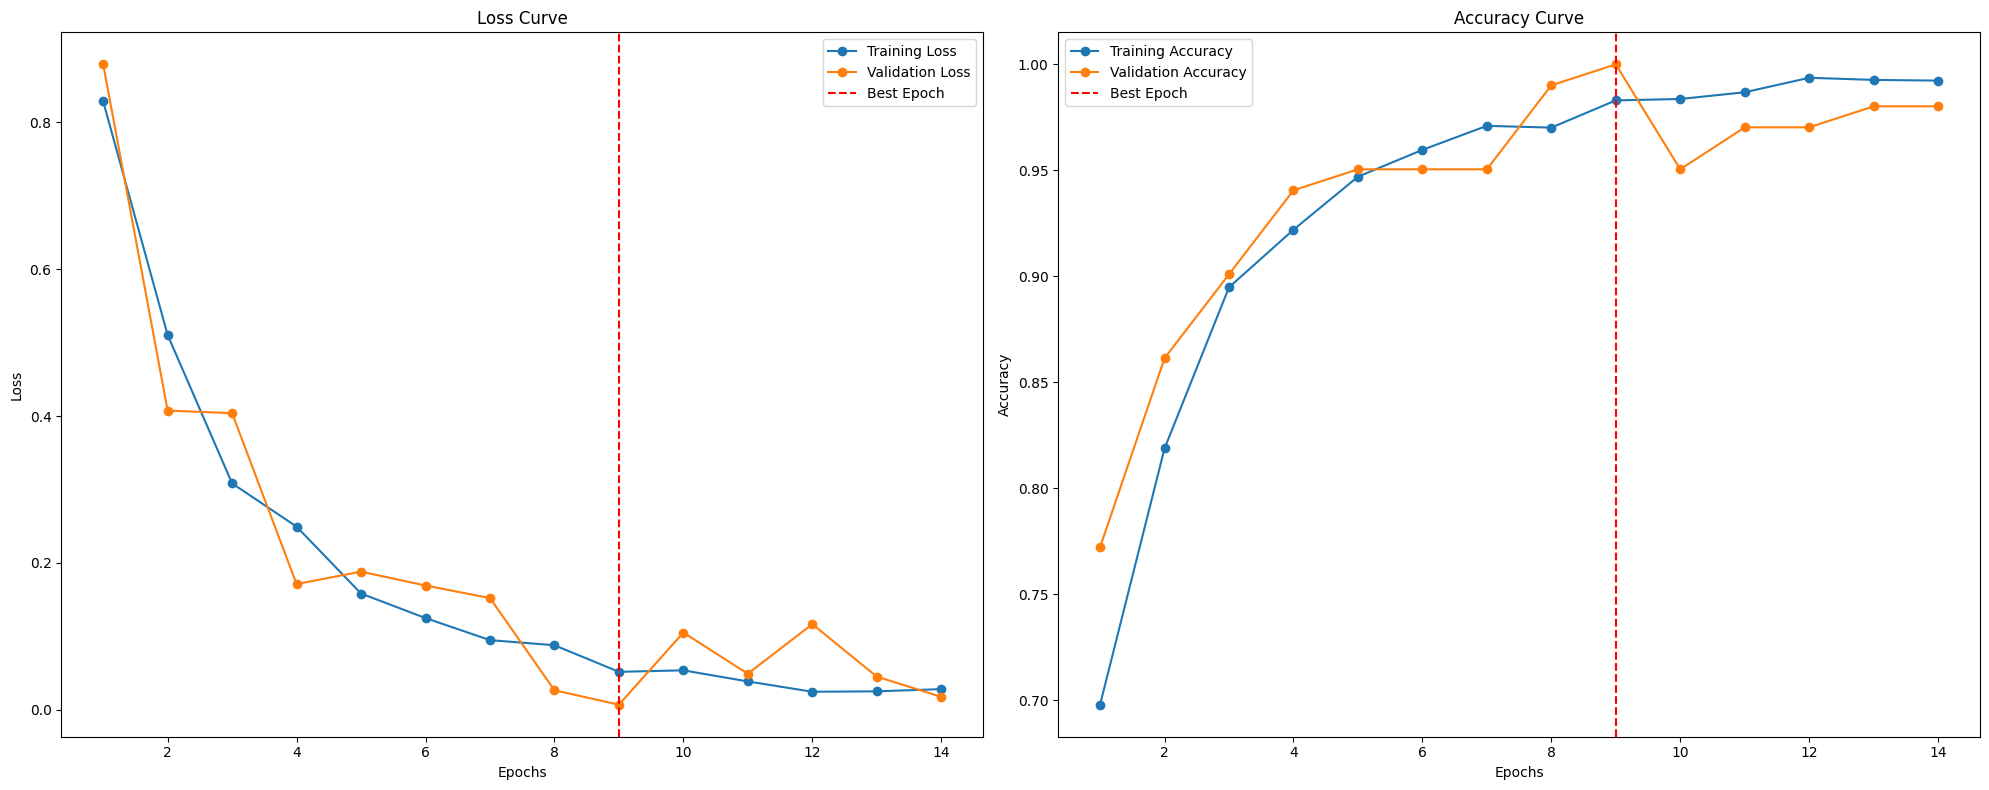


Training Report:
Total training time: 00:08:23
Total epochs run: 14
Best Training Loss: 0.0516 at epoch 9
Best Training Accuracy: 0.9830

Validation Report:
Best Validation Loss: 0.0068 at epoch 9
Best Validation Accuracy: 1.0000
Final Validation Loss: 0.0175
Final Validation Accuracy: 0.9802

Inference Report:
Total Inference Time (Validation only): 00:00:46


In [80]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20, patience=5, min_delta=0.001)

In [81]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.96040
Recall:      0.96040
Precision:   0.96448
F1 Score:    0.96023
MCC:         0.95143
PR AUC:      0.99477
Kappa:       0.95026
Specificity: 0.99000


In [ ]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("resnest50d", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)


Epoch 1/20
------------------------------


Validation Loss: 0.5547, Validation Accuracy: 0.7525
Training Loss: 0.8191, Training Accuracy: 0.6863

Epoch 2/20
------------------------------


Validation Loss: 0.5119, Validation Accuracy: 0.8317
Training Loss: 0.3952, Training Accuracy: 0.8518

Epoch 3/20
------------------------------


Validation Loss: 0.1697, Validation Accuracy: 0.9406
Training Loss: 0.2226, Training Accuracy: 0.9185

Epoch 4/20
------------------------------


Validation Loss: 0.1153, Validation Accuracy: 0.9604
Training Loss: 0.1644, Training Accuracy: 0.9425

Epoch 5/20
------------------------------


...

Validation Loss: 0.0123, Validation Accuracy: 0.9901
Training Loss: 0.0026, Training Accuracy: 0.9992
Patience Counter: 1/5

Epoch 17/20
------------------------------


Validation Loss: 0.0399, Validation Accuracy: 0.9901
Training Loss: 0.0015, Training Accuracy: 0.9998
Patience Counter: 2/5

Epoch 18/20
------------------------------


Validation Loss: 0.0519, Validation Accuracy: 0.9901
Training Loss: 0.0016, Training Accuracy: 0.9998
Patience Counter: 3/5

Epoch 19/20
------------------------------


Validation Loss: 0.0236, Validation Accuracy: 0.9901
Training Loss: 0.0015, Training Accuracy: 0.9993
Patience Counter: 4/5

Epoch 20/20
------------------------------


Validation Loss: 0.0454, Validation Accuracy: 0.9901
Training Loss: 0.0016, Training Accuracy: 0.9997
Patience Counter: 5/5
Early stopping triggered at epoch 20.


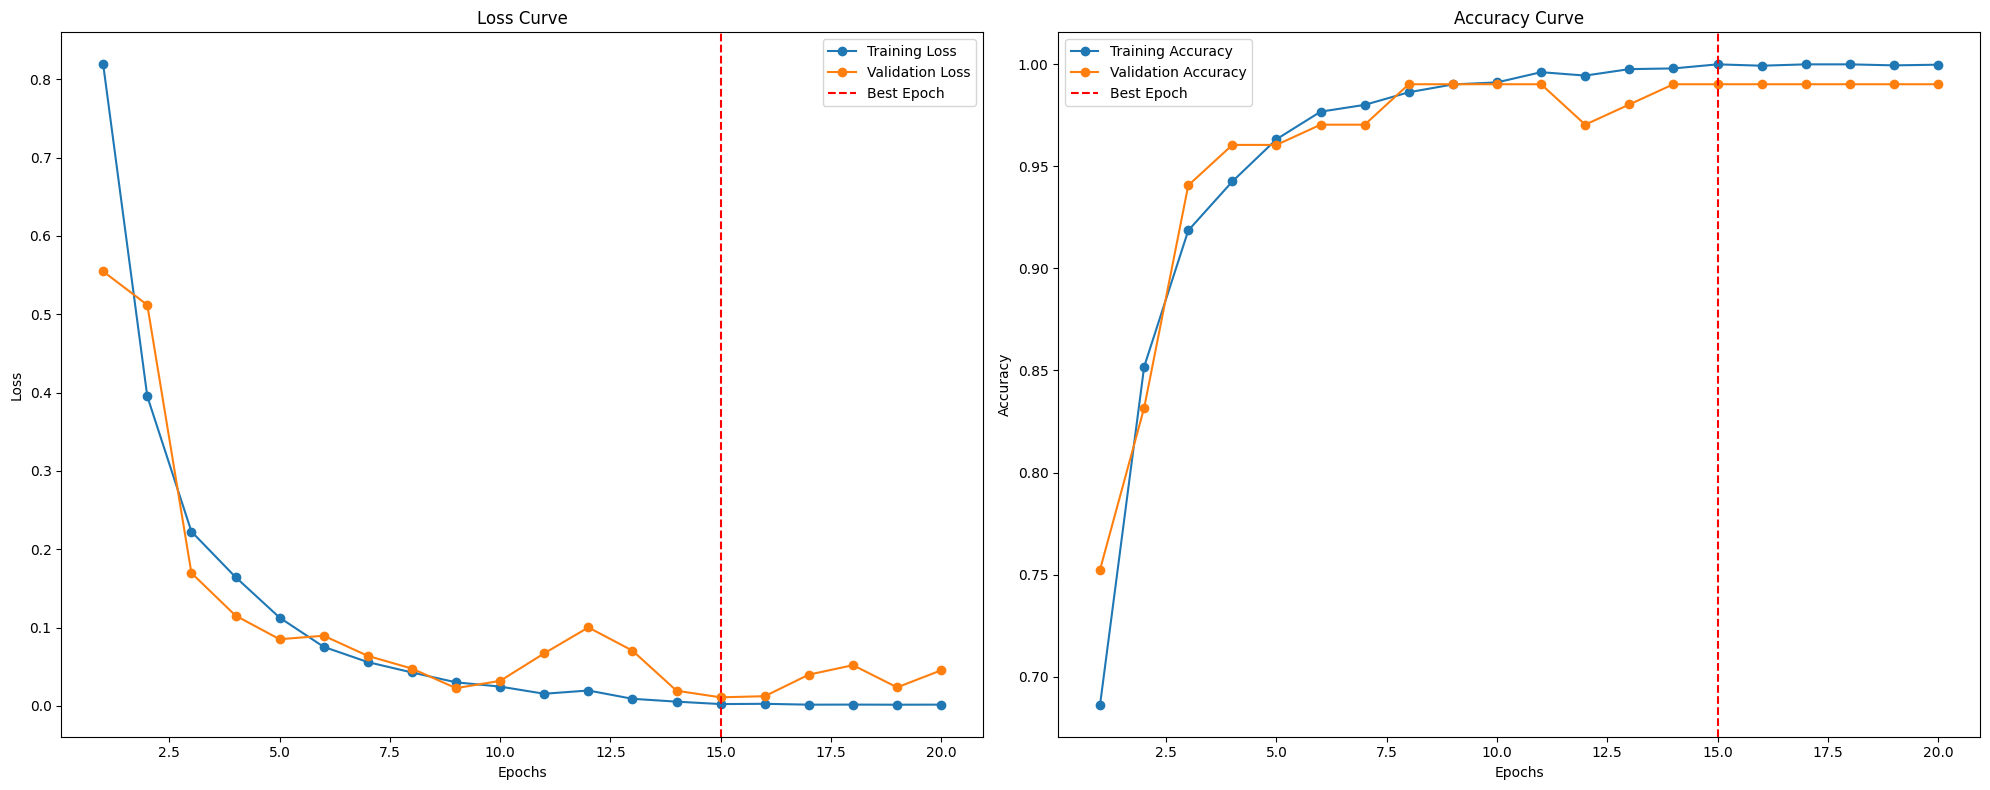


Training Report:
Total training time: 00:13:16
Total epochs run: 20
Best Training Loss: 0.0023 at epoch 15
Best Training Accuracy: 0.9998

Validation Report:
Best Validation Loss: 0.0109 at epoch 15
Best Validation Accuracy: 0.9901
Final Validation Loss: 0.0454
Final Validation Accuracy: 0.9901

Inference Report:
Total Inference Time (Validation only): 00:01:07


In [ ]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20, patience=5, min_delta=0.001)

In [48]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97030
Recall:      0.97071
Precision:   0.97500
F1 Score:    0.97181
MCC:         0.96327
PR AUC:      0.98612
Kappa:       0.96268
Specificity: 0.99237


In [15]:
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    matthews_corrcoef, average_precision_score, cohen_kappa_score, confusion_matrix
)
from sklearn.preprocessing import label_binarize
import numpy as np
import torch

def evaluate_model_with_metrics(model, dataloader):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            probs = torch.softmax(outputs, dim=1)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    accuracy = accuracy_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    mcc = matthews_corrcoef(all_labels, all_preds)

    # PR AUC: needs one-hot labels for multiclass, otherwise this always
    # throws and silently returns NaN
    num_classes = all_probs.shape[1]
    try:
        if num_classes == 2:
            pr_auc = average_precision_score(all_labels, all_probs[:, 1])
        else:
            labels_bin = label_binarize(all_labels, classes=np.arange(num_classes))
            pr_auc = average_precision_score(labels_bin, all_probs, average="weighted")
    except ValueError:
        pr_auc = float('nan')

    kappa = cohen_kappa_score(all_labels, all_preds)

    cm = confusion_matrix(all_labels, all_preds)
    TN, FP = [], []
    for i in range(len(cm)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        TN.append(tn)
        FP.append(fp)
    specificity_per_class = [TN[i] / (TN[i] + FP[i]) if (TN[i] + FP[i]) > 0 else 0 for i in range(len(cm))]
    specificity = np.average(specificity_per_class)

    print(f"Accuracy:    {accuracy:.5f}")
    print(f"Recall:      {recall:.5f}")
    print(f"Precision:   {precision:.5f}")
    print(f"F1 Score:    {f1:.5f}")
    print(f"MCC:         {mcc:.5f}")
    print(f"PR AUC:      {pr_auc:.5f}")
    print(f"Kappa:       {kappa:.5f}")
    print(f"Specificity: {specificity:.5f}")

    return {
        "accuracy": accuracy,
        "recall": recall,
        "precision": precision,
        "f1": f1,
        "mcc": mcc,
        "pr_auc": pr_auc,
        "kappa": kappa,
        "specificity": specificity,
    }

# CV results

Full dataset: 1007 images across 5 classes
Running 5-fold CV on the entire dataset (no held-out test set)

FOLD 1/5  (train=805, val=202)

Processing class: Anthracnose
Original images saved: 184


 92%|█████████████████████████████████████████████████████████████████████████▍      | 169/184 [00:02<00:00, 64.36it/s]


Augmented images created: 1016
Total images in class 'Anthracnose': 1200

Processing class: Healthy
Original images saved: 176


 97%|█████████████████████████████████████████████████████████████████████████████▎  | 170/176 [00:02<00:00, 66.16it/s]


Augmented images created: 1024
Total images in class 'Healthy': 1200

Processing class: Leaf Crinckle
Original images saved: 122


...

Validation Loss: 0.4645, Validation Accuracy: 0.9703
Training Loss: 0.3946, Training Accuracy: 0.9998
Patience Counter: 1/5

Epoch 26/30
------------------------------


Validation Loss: 0.4579, Validation Accuracy: 0.9703
Training Loss: 0.3942, Training Accuracy: 0.9998
Patience Counter: 2/5

Epoch 27/30
------------------------------


Validation Loss: 0.4526, Validation Accuracy: 0.9703
Training Loss: 0.3935, Training Accuracy: 1.0000
Patience Counter: 3/5

Epoch 28/30
------------------------------


Validation Loss: 0.4507, Validation Accuracy: 0.9703
Training Loss: 0.3936, Training Accuracy: 1.0000
Patience Counter: 4/5

Epoch 29/30
------------------------------


Validation Loss: 0.4559, Validation Accuracy: 0.9703
Training Loss: 0.3936, Training Accuracy: 1.0000
Patience Counter: 5/5
Early stopping triggered at epoch 29.


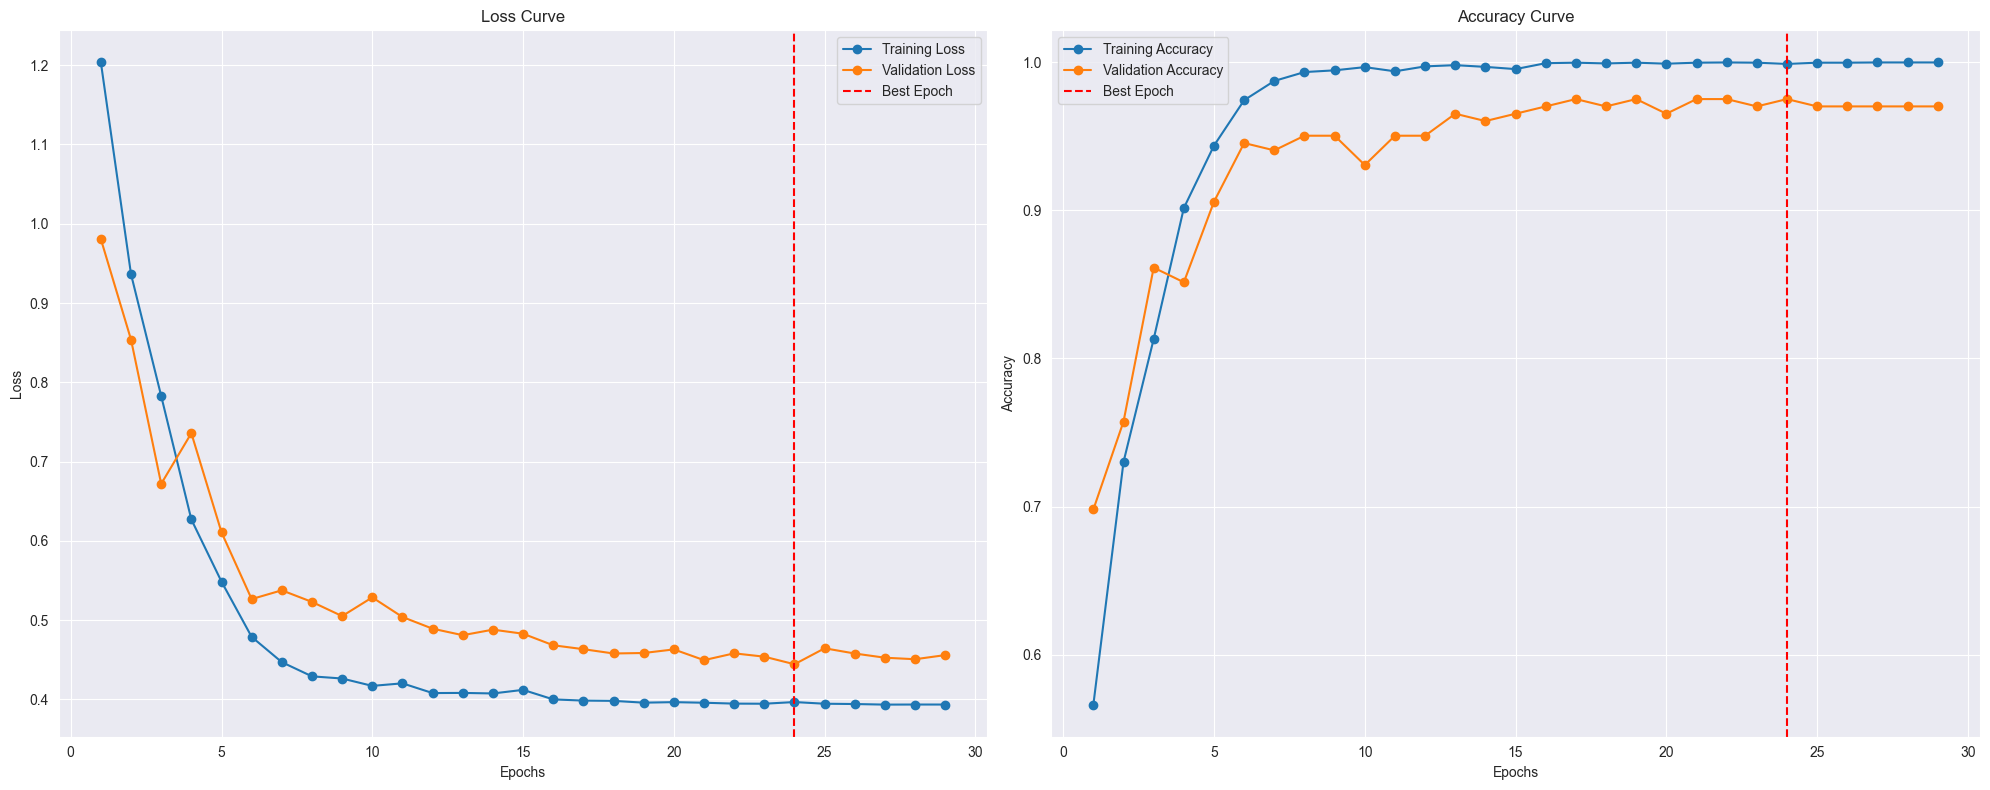


Training Report:
Total training time: 00:15:45
Total epochs run: 29
Best Training Loss: 0.3967 at epoch 24
Best Training Accuracy: 0.9990

Validation Report:
Best Validation Loss: 0.4444 at epoch 24
Best Validation Accuracy: 0.9752
Final Validation Loss: 0.4559
Final Validation Accuracy: 0.9703

Inference Report:
Total Inference Time (Validation only): 00:01:40
Accuracy:    0.97030
Recall:      0.97030
Precision:   0.97060
F1 Score:    0.97032
MCC:         0.96271
PR AUC:      0.99611
Kappa:       0.96265
Specificity: 0.99256
Saved fold 1 checkpoint -> model_fold1.pth

FOLD 2/5  (train=805, val=202)

Processing class: Anthracnose
Original images saved: 184


 92%|█████████████████████████████████████████████████████████████████████████▍      | 169/184 [00:02<00:00, 63.81it/s]


Augmented images created: 1016
Total images in class 'Anthracnose': 1200

Processing class: Healthy
Original images saved: 177


 96%|████████████████████████████████████████████████████████████████████████████▊   | 170/177 [00:02<00:00, 66.50it/s]


Augmented images created: 1023
Total images in class 'Healthy': 1200

Processing class: Leaf Crinckle
Original images saved: 121


...

Validation Loss: 0.4820, Validation Accuracy: 0.9604
Training Loss: 0.4093, Training Accuracy: 0.9970
Patience Counter: 1/5

Epoch 13/30
------------------------------


Validation Loss: 0.5327, Validation Accuracy: 0.9356
Training Loss: 0.4162, Training Accuracy: 0.9945
Patience Counter: 2/5

Epoch 14/30
------------------------------


Validation Loss: 0.5040, Validation Accuracy: 0.9505
Training Loss: 0.4101, Training Accuracy: 0.9967
Patience Counter: 3/5

Epoch 15/30
------------------------------


Validation Loss: 0.4965, Validation Accuracy: 0.9455
Training Loss: 0.4000, Training Accuracy: 1.0000
Patience Counter: 4/5

Epoch 16/30
------------------------------


Validation Loss: 0.4865, Validation Accuracy: 0.9604
Training Loss: 0.4047, Training Accuracy: 0.9975
Patience Counter: 5/5
Early stopping triggered at epoch 16.


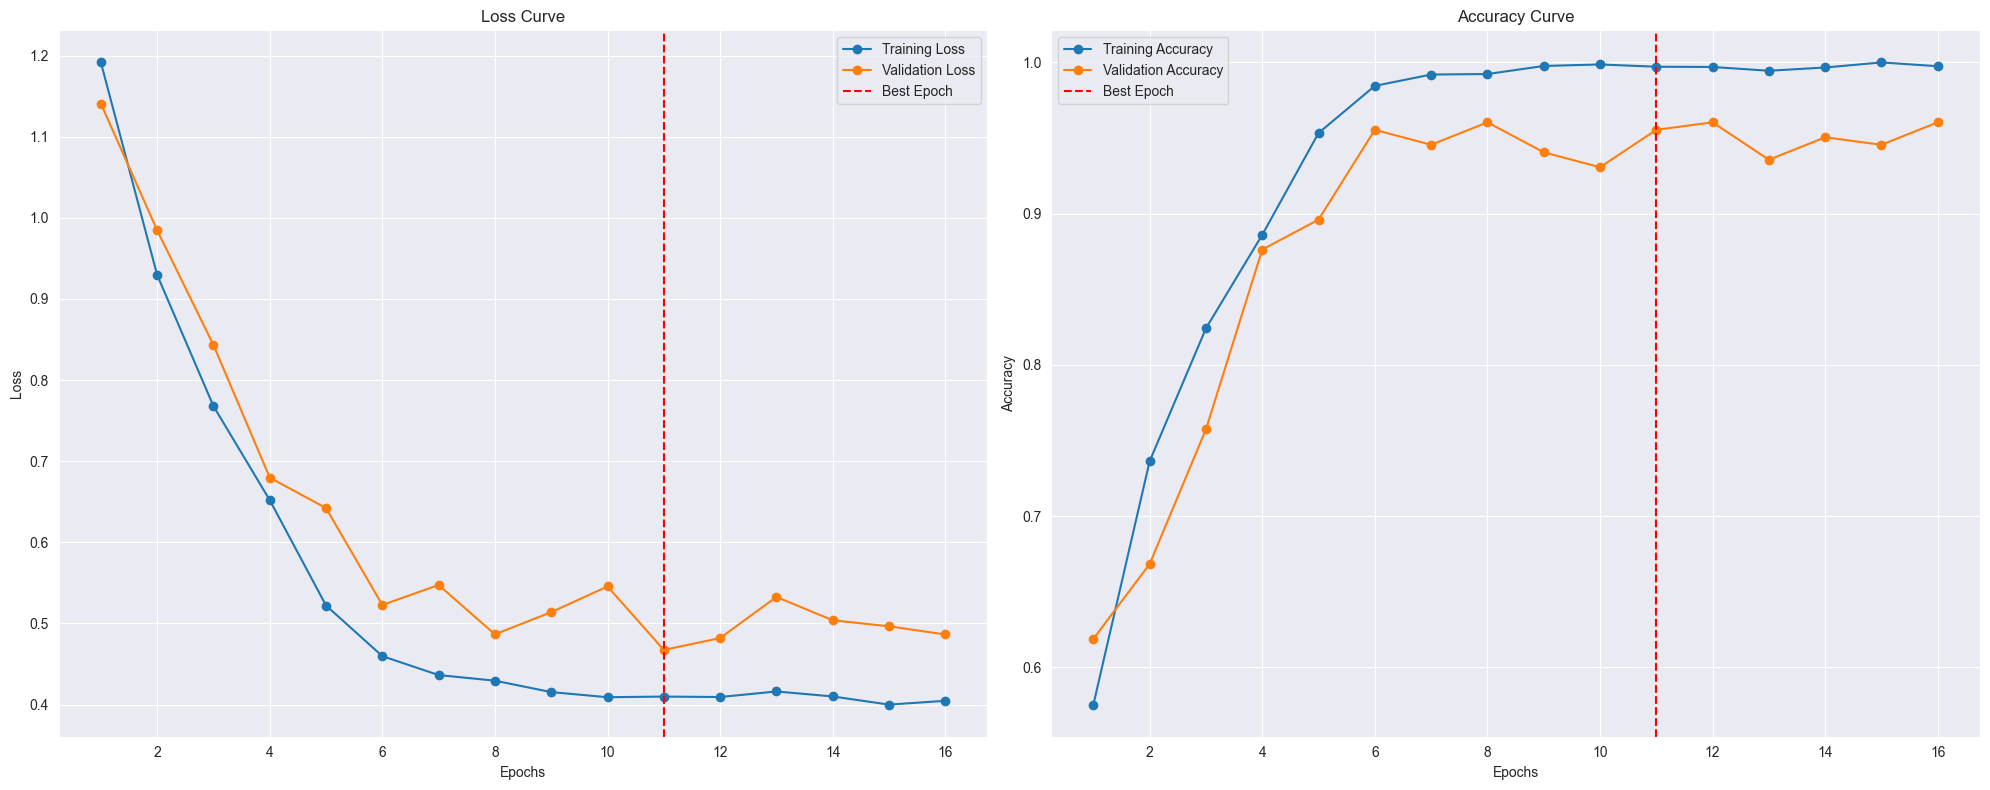


Training Report:
Total training time: 00:08:37
Total epochs run: 16
Best Training Loss: 0.4099 at epoch 11
Best Training Accuracy: 0.9972

Validation Report:
Best Validation Loss: 0.4674 at epoch 11
Best Validation Accuracy: 0.9554
Final Validation Loss: 0.4865
Final Validation Accuracy: 0.9604

Inference Report:
Total Inference Time (Validation only): 00:00:54
Accuracy:    0.96040
Recall:      0.96040
Precision:   0.96133
F1 Score:    0.96055
MCC:         0.95042
PR AUC:      0.99096
Kappa:       0.95028
Specificity: 0.99011
Saved fold 2 checkpoint -> model_fold2.pth

FOLD 3/5  (train=806, val=201)

Processing class: Anthracnose
Original images saved: 184


 92%|█████████████████████████████████████████████████████████████████████████▍      | 169/184 [00:02<00:00, 64.71it/s]


Augmented images created: 1016
Total images in class 'Anthracnose': 1200

Processing class: Healthy
Original images saved: 177


 96%|████████████████████████████████████████████████████████████████████████████▊   | 170/177 [00:02<00:00, 67.43it/s]


Augmented images created: 1023
Total images in class 'Healthy': 1200

Processing class: Leaf Crinckle
Original images saved: 121


...

Validation Loss: 0.4852, Validation Accuracy: 0.9552
Training Loss: 0.3965, Training Accuracy: 0.9998
Patience Counter: 1/5

Epoch 20/30
------------------------------


Validation Loss: 0.4738, Validation Accuracy: 0.9701
Training Loss: 0.3958, Training Accuracy: 0.9998
Patience Counter: 2/5

Epoch 21/30
------------------------------


Validation Loss: 0.4866, Validation Accuracy: 0.9552
Training Loss: 0.3959, Training Accuracy: 0.9992
Patience Counter: 3/5

Epoch 22/30
------------------------------


Validation Loss: 0.4795, Validation Accuracy: 0.9602
Training Loss: 0.3947, Training Accuracy: 1.0000
Patience Counter: 4/5

Epoch 23/30
------------------------------


Validation Loss: 0.4765, Validation Accuracy: 0.9552
Training Loss: 0.3940, Training Accuracy: 1.0000
Patience Counter: 5/5
Early stopping triggered at epoch 23.


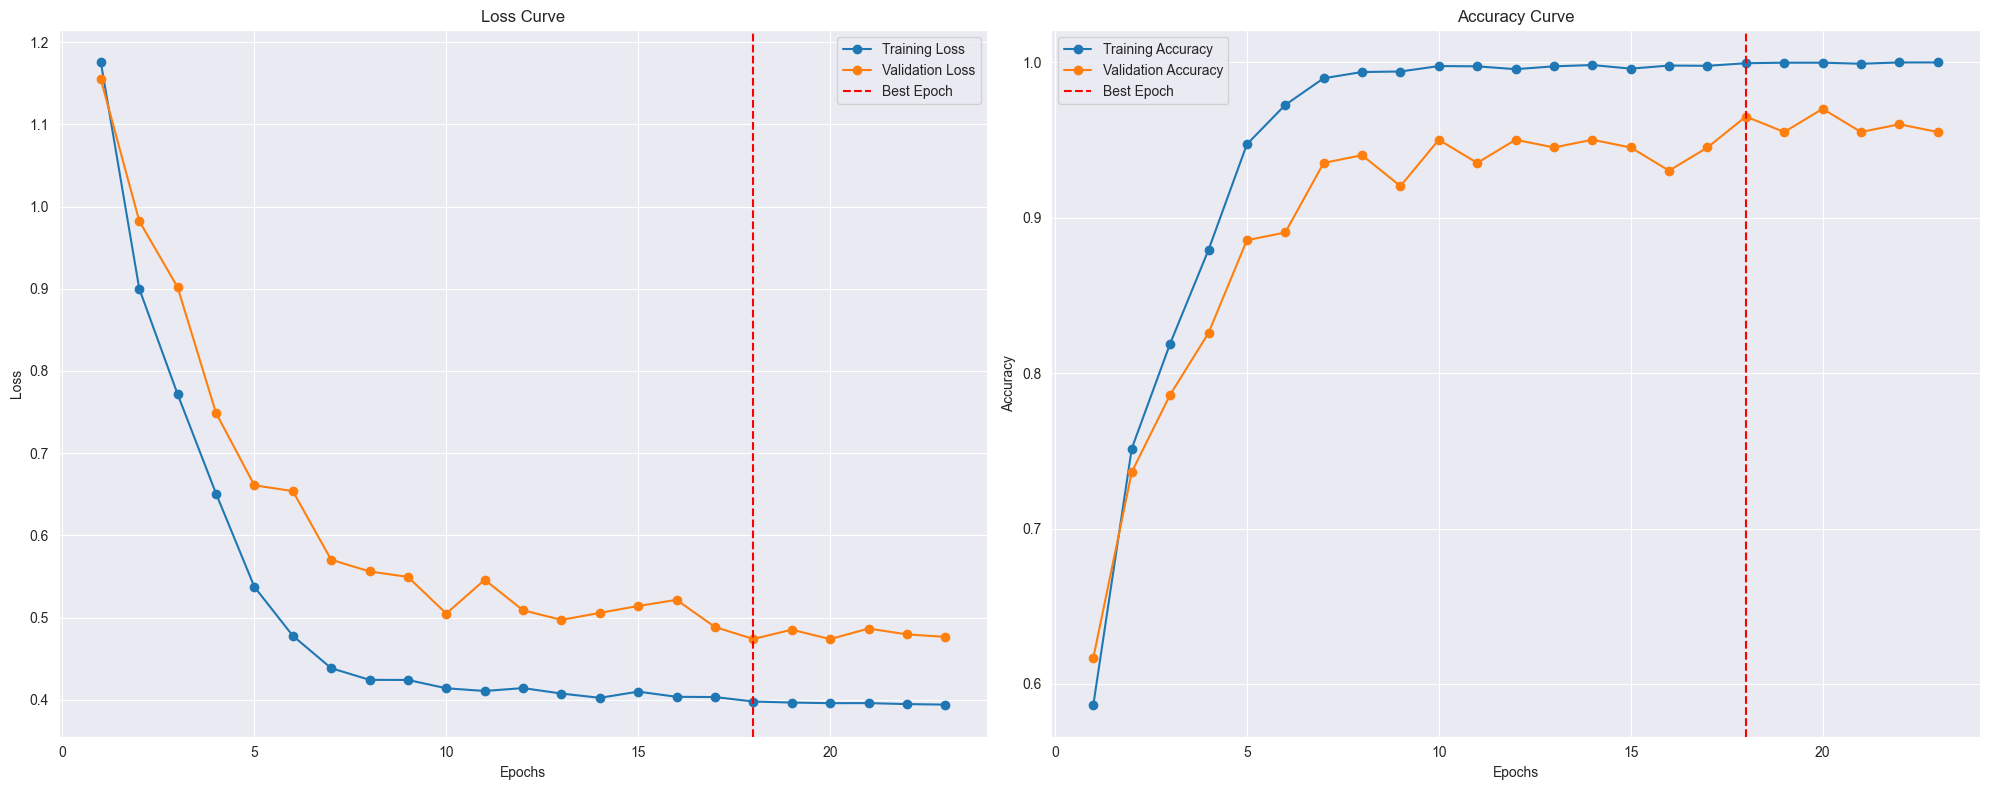


Training Report:
Total training time: 00:12:25
Total epochs run: 23
Best Training Loss: 0.3978 at epoch 18
Best Training Accuracy: 0.9995

Validation Report:
Best Validation Loss: 0.4739 at epoch 18
Best Validation Accuracy: 0.9652
Final Validation Loss: 0.4765
Final Validation Accuracy: 0.9552

Inference Report:
Total Inference Time (Validation only): 00:01:19
Accuracy:    0.95522
Recall:      0.95522
Precision:   0.95782
F1 Score:    0.95535
MCC:         0.94439
PR AUC:      0.99419
Kappa:       0.94381
Specificity: 0.98908
Saved fold 3 checkpoint -> model_fold3.pth

FOLD 4/5  (train=806, val=201)

Processing class: Anthracnose
Original images saved: 184


 92%|█████████████████████████████████████████████████████████████████████████▍      | 169/184 [00:02<00:00, 65.38it/s]


Augmented images created: 1016
Total images in class 'Anthracnose': 1200

Processing class: Healthy
Original images saved: 177


 96%|████████████████████████████████████████████████████████████████████████████▊   | 170/177 [00:02<00:00, 64.83it/s]


Augmented images created: 1023
Total images in class 'Healthy': 1200

Processing class: Leaf Crinckle
Original images saved: 122


...

Validation Loss: 0.4481, Validation Accuracy: 0.9851
Training Loss: 0.3955, Training Accuracy: 0.9997
Patience Counter: 1/5

Epoch 22/30
------------------------------


Validation Loss: 0.4402, Validation Accuracy: 0.9851
Training Loss: 0.3941, Training Accuracy: 0.9998
Patience Counter: 2/5

Epoch 23/30
------------------------------


Validation Loss: 0.4402, Validation Accuracy: 0.9851
Training Loss: 0.3939, Training Accuracy: 1.0000
Patience Counter: 3/5

Epoch 24/30
------------------------------


Validation Loss: 0.4378, Validation Accuracy: 0.9851
Training Loss: 0.3938, Training Accuracy: 1.0000
Patience Counter: 4/5

Epoch 25/30
------------------------------


Validation Loss: 0.4383, Validation Accuracy: 0.9851
Training Loss: 0.3936, Training Accuracy: 1.0000
Patience Counter: 5/5
Early stopping triggered at epoch 25.


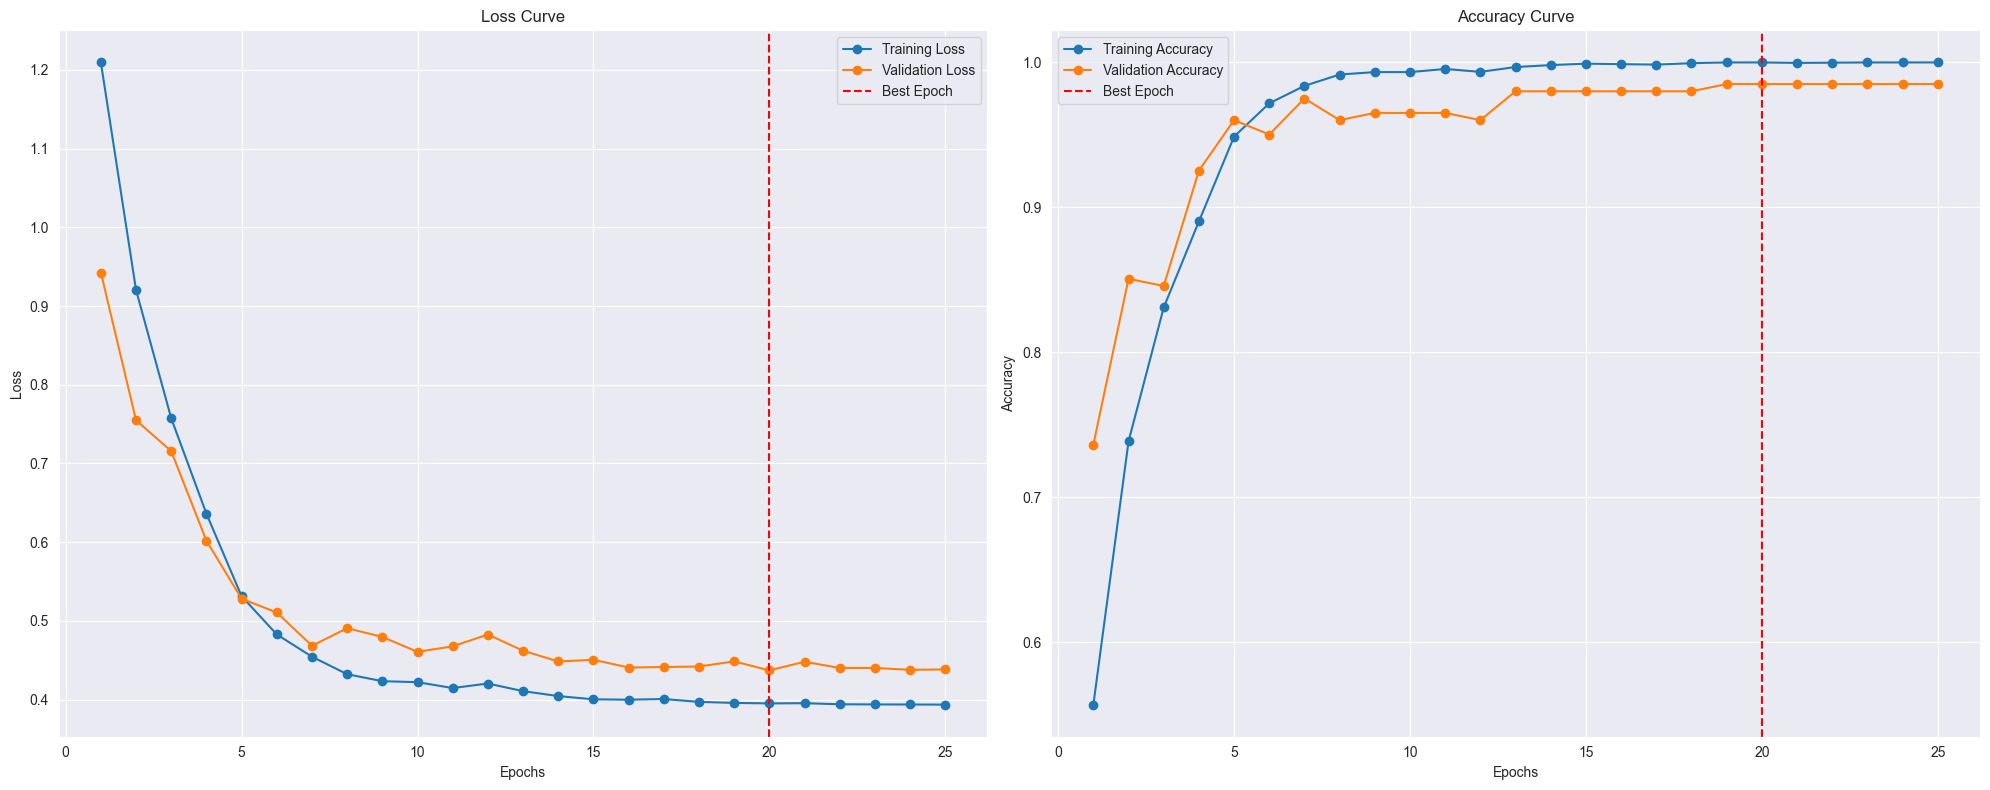


Training Report:
Total training time: 00:13:31
Total epochs run: 25
Best Training Loss: 0.3952 at epoch 20
Best Training Accuracy: 1.0000

Validation Report:
Best Validation Loss: 0.4371 at epoch 20
Best Validation Accuracy: 0.9851
Final Validation Loss: 0.4383
Final Validation Accuracy: 0.9851

Inference Report:
Total Inference Time (Validation only): 00:01:25
Accuracy:    0.98507
Recall:      0.98507
Precision:   0.98560
F1 Score:    0.98514
MCC:         0.98132
PR AUC:      0.99548
Kappa:       0.98123
Specificity: 0.99629
Saved fold 4 checkpoint -> model_fold4.pth

FOLD 5/5  (train=806, val=201)

Processing class: Anthracnose
Original images saved: 184


 92%|█████████████████████████████████████████████████████████████████████████▍      | 169/184 [00:02<00:00, 65.06it/s]


Augmented images created: 1016
Total images in class 'Anthracnose': 1200

Processing class: Healthy
Original images saved: 177


 96%|████████████████████████████████████████████████████████████████████████████▊   | 170/177 [00:02<00:00, 68.08it/s]


Augmented images created: 1023
Total images in class 'Healthy': 1200

Processing class: Leaf Crinckle
Original images saved: 122


...

Validation Loss: 0.4855, Validation Accuracy: 0.9602
Training Loss: 0.4048, Training Accuracy: 0.9982
Patience Counter: 1/5

Epoch 15/30
------------------------------


Validation Loss: 0.5125, Validation Accuracy: 0.9552
Training Loss: 0.4072, Training Accuracy: 0.9965
Patience Counter: 2/5

Epoch 16/30
------------------------------


Validation Loss: 0.4644, Validation Accuracy: 0.9701
Training Loss: 0.4033, Training Accuracy: 0.9977
Patience Counter: 3/5

Epoch 17/30
------------------------------


Validation Loss: 0.4690, Validation Accuracy: 0.9652
Training Loss: 0.4052, Training Accuracy: 0.9970
Patience Counter: 4/5

Epoch 18/30
------------------------------


Validation Loss: 0.4605, Validation Accuracy: 0.9701
Training Loss: 0.3999, Training Accuracy: 0.9990
Patience Counter: 5/5
Early stopping triggered at epoch 18.


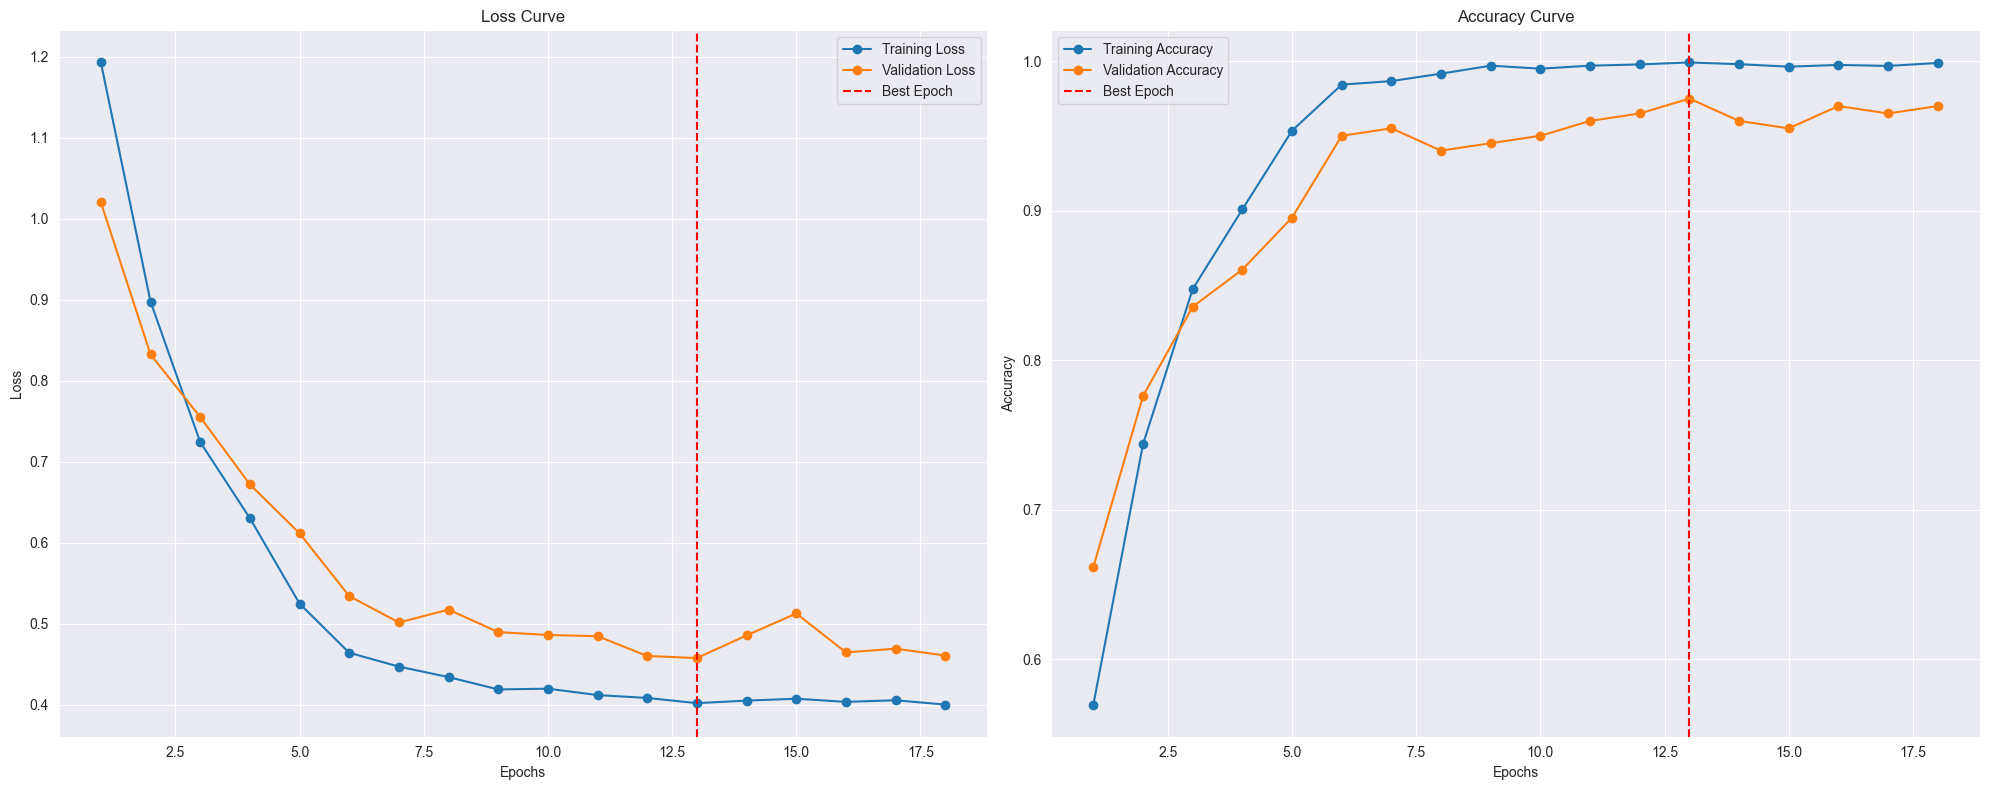


Training Report:
Total training time: 00:09:44
Total epochs run: 18
Best Training Loss: 0.4017 at epoch 13
Best Training Accuracy: 0.9993

Validation Report:
Best Validation Loss: 0.4574 at epoch 13
Best Validation Accuracy: 0.9751
Final Validation Loss: 0.4605
Final Validation Accuracy: 0.9701

Inference Report:
Total Inference Time (Validation only): 00:01:01
Accuracy:    0.97015
Recall:      0.97015
Precision:   0.97108
F1 Score:    0.97019
MCC:         0.96264
PR AUC:      0.99022
Kappa:       0.96243
Specificity: 0.99233
Saved fold 5 checkpoint -> model_fold5.pth

Per-fold results:
      accuracy  recall  precision      f1     mcc  pr_auc   kappa  specificity
fold                                                                          
1       0.9703  0.9703     0.9706  0.9703  0.9627  0.9961  0.9626       0.9926
2       0.9604  0.9604     0.9613  0.9606  0.9504  0.9910  0.9503       0.9901
3       0.9552  0.9552     0.9578  0.9553  0.9444  0.9942  0.9438       0.9891
4       0.

In [12]:
"""
5-FOLD CROSS-VALIDATION PIPELINE (whole dataset, no held-out test set)
=======================================================================
Slots in AFTER your existing code that defines:
    - df                         (full filepaths/labels DataFrame)
    - CustomImageDataset         (from my_dataset)
    - loading_the_data(dir)      (rebuilds a df from a folder of class subfolders)
    - offline_augment_train(...) (your imgaug-based offline augmentation)
    - train_aug_seq               (imgaug Sequential)
    - data_transform              (torchvision transform)
    - load_custom_model(num_classes, device)
    - get_parameter_groups(model, weight_decay)
    - train_model(model, train_loader, val_loader, criterion, optimizer,
                  scheduler, num_epochs, patience, min_delta)
    - evaluate_model_with_metrics(model, loader)
    - device

It REPLACES the single train_test_split -> train/val/test block and the
single training run at the bottom of your script.

Every image in `df` is used across the 5 folds - there is no held-out test
set. Each fold uses 4/5 of df as train (offline-augmented) and 1/5 as
validation (untouched), so every sample gets evaluated exactly once across
the 5 folds. The mean ± std of the per-fold validation metrics IS your
CV evaluation result.

IMPORTANT ASSUMPTION: evaluate_model_with_metrics(model, loader) should
RETURN a flat dict of scalar metrics, e.g.
    {"accuracy": 0.97, "precision": 0.96, "recall": 0.97, "f1": 0.965}
If it currently only prints, add a `return {...}` at the end of it -
the aggregation step below depends on a dict coming back.
"""

import os
import gc
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold

from my_dataset import CustomImageDataset

# ──────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────
N_FOLDS            = 5
TARGET_PER_CLASS   = 1200
RANDOM_STATE       = 42
BASE_AUG_DIR       = "D:\\BPLD Dataset\\CV_TrainAug"
CLEANUP_BETWEEN_FOLDS = True       # delete each fold's augmented images after training
                                    # (set False if you want to keep them / ensemble later)
NUM_EPOCHS         = 30
PATIENCE           = 5
MIN_DELTA          = 0.001
WARMUP_EPOCHS      = 3
BASE_LR            = 5e-4
WEIGHT_DECAY       = 0.02
BATCH_SIZE         = 32
NUM_WORKERS        = 4

# ──────────────────────────────────────────────────────────────────────────
# LABEL MAPPING (built once, shared across every fold)
# ──────────────────────────────────────────────────────────────────────────
label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")
print(f"Running {N_FOLDS}-fold CV on the entire dataset (no held-out test set)")


# ──────────────────────────────────────────────────────────────────────────
# OPTIMIZER / SCHEDULER BUILDER (fresh instance needed every fold)
# ──────────────────────────────────────────────────────────────────────────
def build_optimizer_scheduler(model):
    param_groups = get_parameter_groups(model, weight_decay=WEIGHT_DECAY)
    optimizer = optim.AdamW(param_groups, lr=BASE_LR)

    warmup_scheduler = LinearLR(
        optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS
    )
    cosine_scheduler = CosineAnnealingLR(
        optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS, eta_min=1e-6
    )
    scheduler = SequentialLR(
        optimizer, schedulers=[warmup_scheduler, cosine_scheduler],
        milestones=[WARMUP_EPOCHS]
    )
    return optimizer, scheduler


# ──────────────────────────────────────────────────────────────────────────
# SINGLE-FOLD ROUTINE: augment -> build loaders -> train -> evaluate
# ──────────────────────────────────────────────────────────────────────────
def run_single_fold(fold_idx, fold_train_df, fold_val_df):
    print(f"\n{'='*70}\nFOLD {fold_idx}/{N_FOLDS}"
          f"  (train={len(fold_train_df)}, val={len(fold_val_df)})\n{'='*70}")

    # ---- offline augmentation, isolated per fold ----
    fold_aug_dir = os.path.join(BASE_AUG_DIR, f"fold_{fold_idx}")
    if os.path.exists(fold_aug_dir):
        shutil.rmtree(fold_aug_dir)  # avoid stale images from a previous run

    offline_augment_train(fold_train_df, fold_aug_dir, target_per_class=TARGET_PER_CLASS)
    fold_train_expanded_df = loading_the_data(fold_aug_dir)

    # ---- datasets / loaders ----
    fold_train_labels = fold_train_expanded_df['labels'].map(label_mapping).values
    fold_val_labels = fold_val_df['labels'].map(label_mapping).values

    fold_train_dataset = CustomImageDataset(
        fold_train_expanded_df['filepaths'].values, fold_train_labels, transform=data_transform
    )
    fold_val_dataset = CustomImageDataset(
        fold_val_df['filepaths'].values, fold_val_labels, transform=data_transform
    )

    fold_train_loader = DataLoader(fold_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                                    num_workers=NUM_WORKERS, pin_memory=True)
    fold_val_loader = DataLoader(fold_val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

    # ---- fresh model, optimizer, scheduler ----
    model = load_custom_model(num_classes, device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer, scheduler = build_optimizer_scheduler(model)

    train_model(model, fold_train_loader, fold_val_loader, criterion, optimizer,
                scheduler, num_epochs=NUM_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)

    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            "evaluate_model_with_metrics returned None - make it `return {...}` "
            "a dict of scalar metrics so fold results can be aggregated."
        )

    checkpoint_path = f"model_fold{fold_idx}.pth"
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved fold {fold_idx} checkpoint -> {checkpoint_path}")

    # ---- cleanup ----
    if CLEANUP_BETWEEN_FOLDS:
        shutil.rmtree(fold_aug_dir)

    del model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()

    return fold_metrics


# ──────────────────────────────────────────────────────────────────────────
# MAIN CV LOOP - every image in df is used, each exactly once as validation
# ──────────────────────────────────────────────────────────────────────────
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

fold_results = []
for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df['filepaths'], df['labels']), start=1
):
    fold_train_df = df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)

    metrics = run_single_fold(fold_idx, fold_train_df, fold_val_df)
    metrics["fold"] = fold_idx
    fold_results.append(metrics)


# ──────────────────────────────────────────────────────────────────────────
# AGGREGATE RESULTS - this mean ± std IS your CV evaluation result
# ──────────────────────────────────────────────────────────────────────────
def summarize_cv_results(fold_results):
    results_df = pd.DataFrame(fold_results).set_index("fold")
    summary = results_df.agg(['mean', 'std'])

    print("\nPer-fold results:")
    print(results_df.round(4))
    print(f"\nMean ± Std across {len(results_df)} folds:")
    for col in results_df.columns:
        print(f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}")

    return results_df, summary

cv_results_df, cv_summary = summarize_cv_results(fold_results)
cv_results_df.to_csv("cv_fold_results.csv")

Full dataset: 1007 images across 5 classes
Running 5-fold CV with offline Albumentations augmentation
Number of classes: 5
Label mapping: {'Anthracnose': 0, 'Healthy': 1, 'Leaf Crinckle': 2, 'Powdery Mildew': 3, 'Yellow Mosaic': 4}

FOLD 1/5 (train=805, val=202)

Processing class: Anthracnose
Original images saved: 184


 85%|████████▌ | 157/184 [00:00<00:00, 177.53it/s]


Augmented images created: 316
Total images in class 'Anthracnose': 500

Processing class: Healthy
Original images saved: 176


 91%|█████████▏| 161/176 [00:00<00:00, 184.51it/s]


Augmented images created: 324
Total images in class 'Healthy': 500

Processing class: Leaf Crinckle
Original images saved: 122


...

Validation Loss: 0.2091, Validation Accuracy: 0.9554
Training Loss: 0.0351, Training Accuracy: 0.9884
Patience Counter: 1/5

Epoch 13/20
------------------------------


Validation Loss: 0.1674, Validation Accuracy: 0.9505
Training Loss: 0.0467, Training Accuracy: 0.9840
Patience Counter: 2/5

Epoch 14/20
------------------------------


Validation Loss: 0.1864, Validation Accuracy: 0.9554
Training Loss: 0.0315, Training Accuracy: 0.9888
Patience Counter: 3/5

Epoch 15/20
------------------------------


Validation Loss: 0.1513, Validation Accuracy: 0.9653
Training Loss: 0.0182, Training Accuracy: 0.9952
Patience Counter: 4/5

Epoch 16/20
------------------------------


Validation Loss: 0.1342, Validation Accuracy: 0.9802
Training Loss: 0.0140, Training Accuracy: 0.9960
Patience Counter: 5/5
Early stopping triggered at epoch 16.


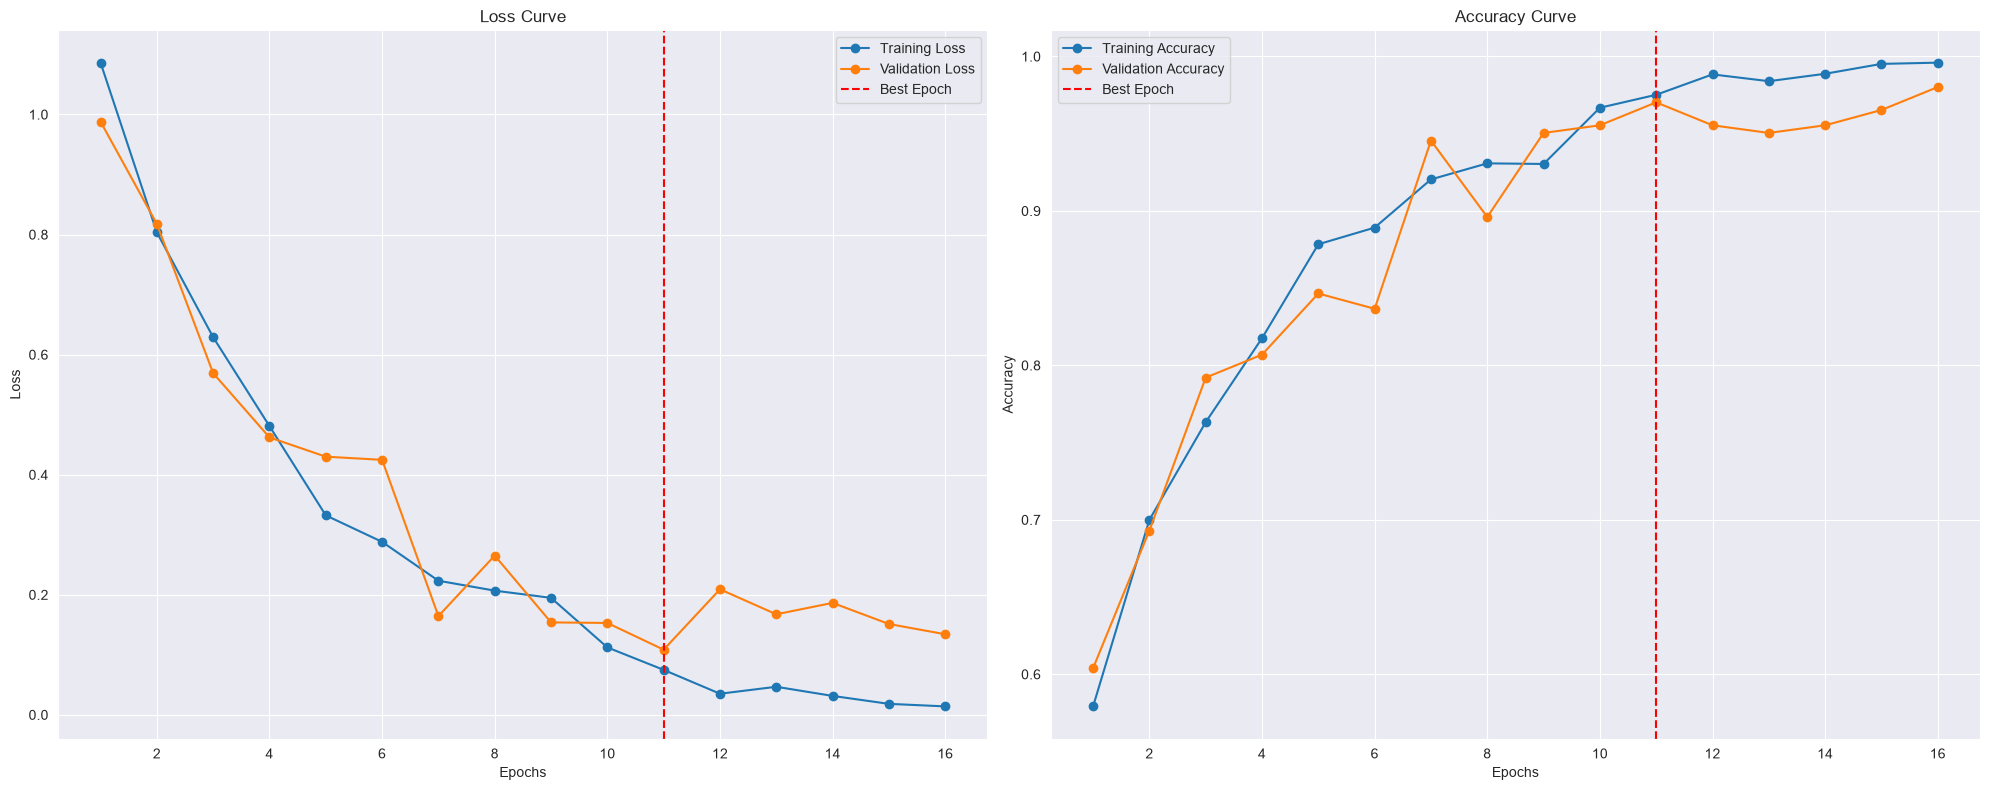


Training Report:
Total training time: 00:06:55
Total epochs run: 16
Best Training Loss: 0.0749 at epoch 11
Best Training Accuracy: 0.9752

Validation Report:
Best Validation Loss: 0.1085 at epoch 11
Best Validation Accuracy: 0.9703
Final Validation Loss: 0.1342
Final Validation Accuracy: 0.9802

Inference Report:
Total Inference Time (Validation only): 00:01:08
Accuracy:    0.98020
Recall:      0.98020
Precision:   0.98035
F1 Score:    0.98015
MCC:         0.97514
PR AUC:      0.98779
Kappa:       0.97507
Specificity: 0.99501

Fold 1 metrics:
  accuracy: 0.9802
  recall: 0.9802
  precision: 0.9803
  f1: 0.9801
  mcc: 0.9751
  pr_auc: 0.9878
  kappa: 0.9751
  specificity: 0.9950
Saved fold 1 checkpoint -> resnest50d_fold1.pth
Deleted augmentation directory: D:\BPLD Dataset\CV_TrainAug\fold_1

FOLD 2/5 (train=805, val=202)

Processing class: Anthracnose
Original images saved: 184


 85%|████████▌ | 157/184 [00:00<00:00, 182.35it/s]


Augmented images created: 316
Total images in class 'Anthracnose': 500

Processing class: Healthy
Original images saved: 177


 91%|█████████ | 161/177 [00:00<00:00, 190.64it/s]


Augmented images created: 323
Total images in class 'Healthy': 500

Processing class: Leaf Crinckle
Original images saved: 121


...

Validation Loss: 0.1800, Validation Accuracy: 0.9455
Training Loss: 0.0502, Training Accuracy: 0.9844
Patience Counter: 1/5

Epoch 13/20
------------------------------


Validation Loss: 0.2111, Validation Accuracy: 0.9307
Training Loss: 0.0454, Training Accuracy: 0.9880
Patience Counter: 2/5

Epoch 14/20
------------------------------


Validation Loss: 0.1875, Validation Accuracy: 0.9406
Training Loss: 0.0297, Training Accuracy: 0.9908
Patience Counter: 3/5

Epoch 15/20
------------------------------


Validation Loss: 0.1816, Validation Accuracy: 0.9455
Training Loss: 0.0191, Training Accuracy: 0.9948
Patience Counter: 4/5

Epoch 16/20
------------------------------


Validation Loss: 0.1601, Validation Accuracy: 0.9455
Training Loss: 0.0186, Training Accuracy: 0.9948
Patience Counter: 5/5
Early stopping triggered at epoch 16.


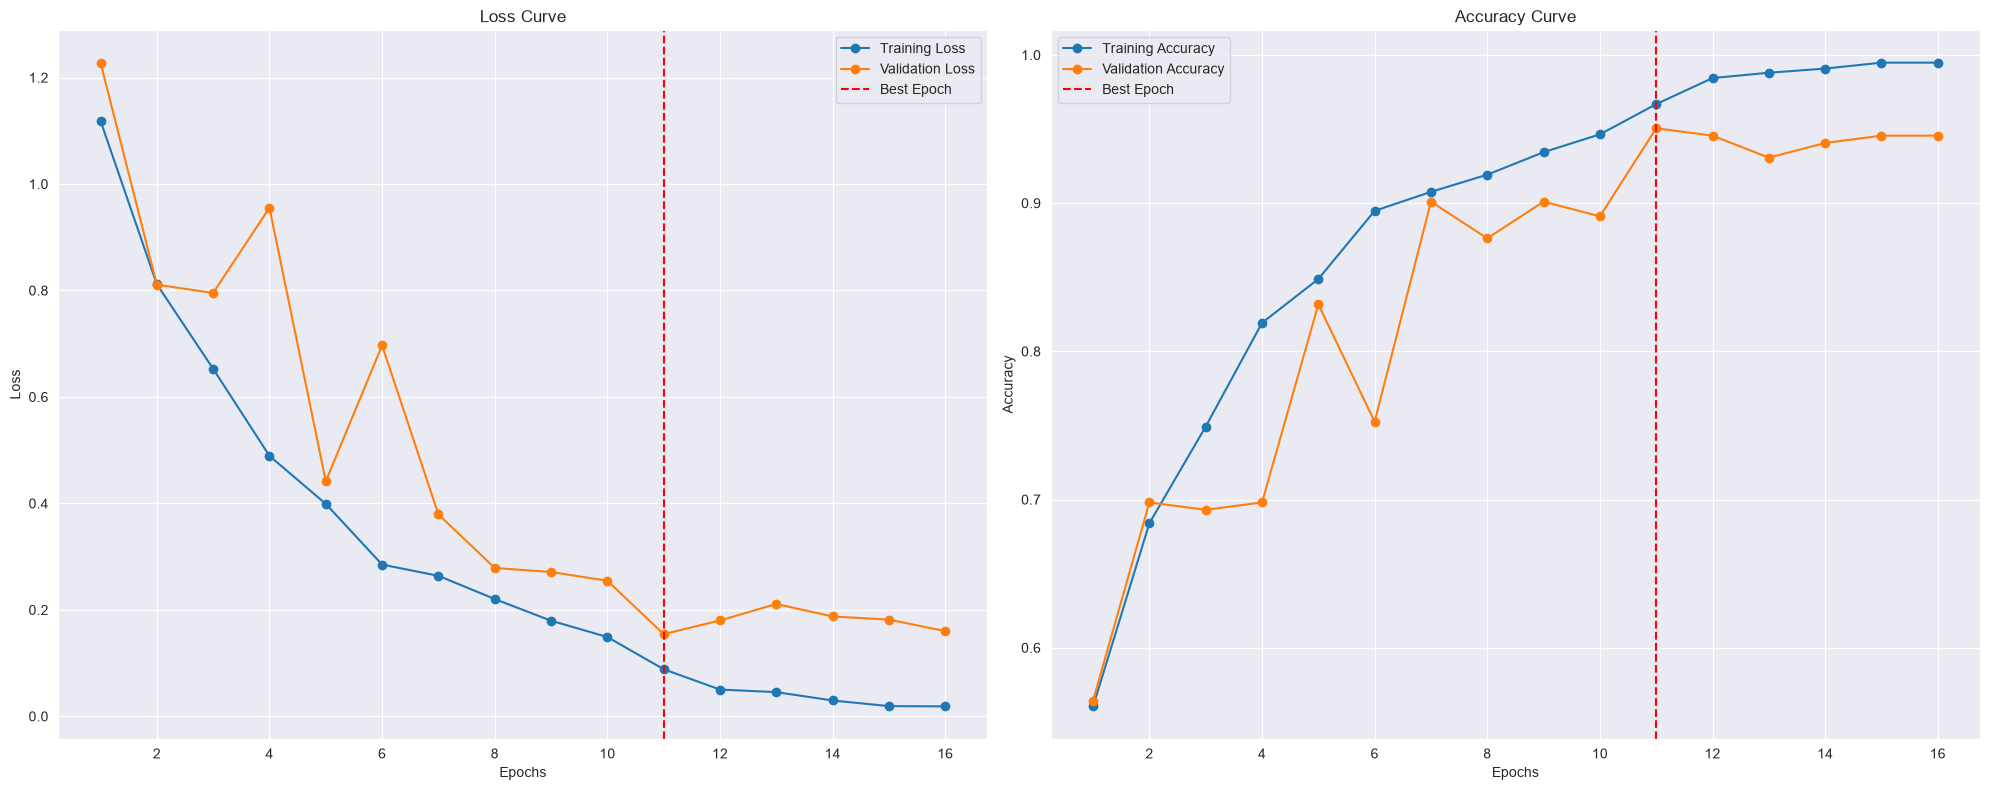


Training Report:
Total training time: 00:06:53
Total epochs run: 16
Best Training Loss: 0.0884 at epoch 11
Best Training Accuracy: 0.9668

Validation Report:
Best Validation Loss: 0.1544 at epoch 11
Best Validation Accuracy: 0.9505
Final Validation Loss: 0.1601
Final Validation Accuracy: 0.9455

Inference Report:
Total Inference Time (Validation only): 00:01:08
Accuracy:    0.94554
Recall:      0.94554
Precision:   0.94789
F1 Score:    0.94605
MCC:         0.93196
PR AUC:      0.99056
Kappa:       0.93162
Specificity: 0.98624

Fold 2 metrics:
  accuracy: 0.9455
  recall: 0.9455
  precision: 0.9479
  f1: 0.9461
  mcc: 0.9320
  pr_auc: 0.9906
  kappa: 0.9316
  specificity: 0.9862
Saved fold 2 checkpoint -> resnest50d_fold2.pth
Deleted augmentation directory: D:\BPLD Dataset\CV_TrainAug\fold_2

FOLD 3/5 (train=806, val=201)

Processing class: Anthracnose
Original images saved: 184


 85%|████████▌ | 157/184 [00:00<00:00, 179.98it/s]


Augmented images created: 316
Total images in class 'Anthracnose': 500

Processing class: Healthy
Original images saved: 177


 91%|█████████ | 161/177 [00:00<00:00, 182.24it/s]


Augmented images created: 323
Total images in class 'Healthy': 500

Processing class: Leaf Crinckle
Original images saved: 121


...

Validation Loss: 0.1853, Validation Accuracy: 0.9502
Training Loss: 0.0162, Training Accuracy: 0.9960

Epoch 17/20
------------------------------


Validation Loss: 0.1657, Validation Accuracy: 0.9602
Training Loss: 0.0122, Training Accuracy: 0.9980

Epoch 18/20
------------------------------


Validation Loss: 0.1424, Validation Accuracy: 0.9701
Training Loss: 0.0144, Training Accuracy: 0.9948

Epoch 19/20
------------------------------


Validation Loss: 0.1515, Validation Accuracy: 0.9652
Training Loss: 0.0090, Training Accuracy: 0.9980
Patience Counter: 1/5

Epoch 20/20
------------------------------


Validation Loss: 0.1864, Validation Accuracy: 0.9502
Training Loss: 0.0096, Training Accuracy: 0.9976
Patience Counter: 2/5


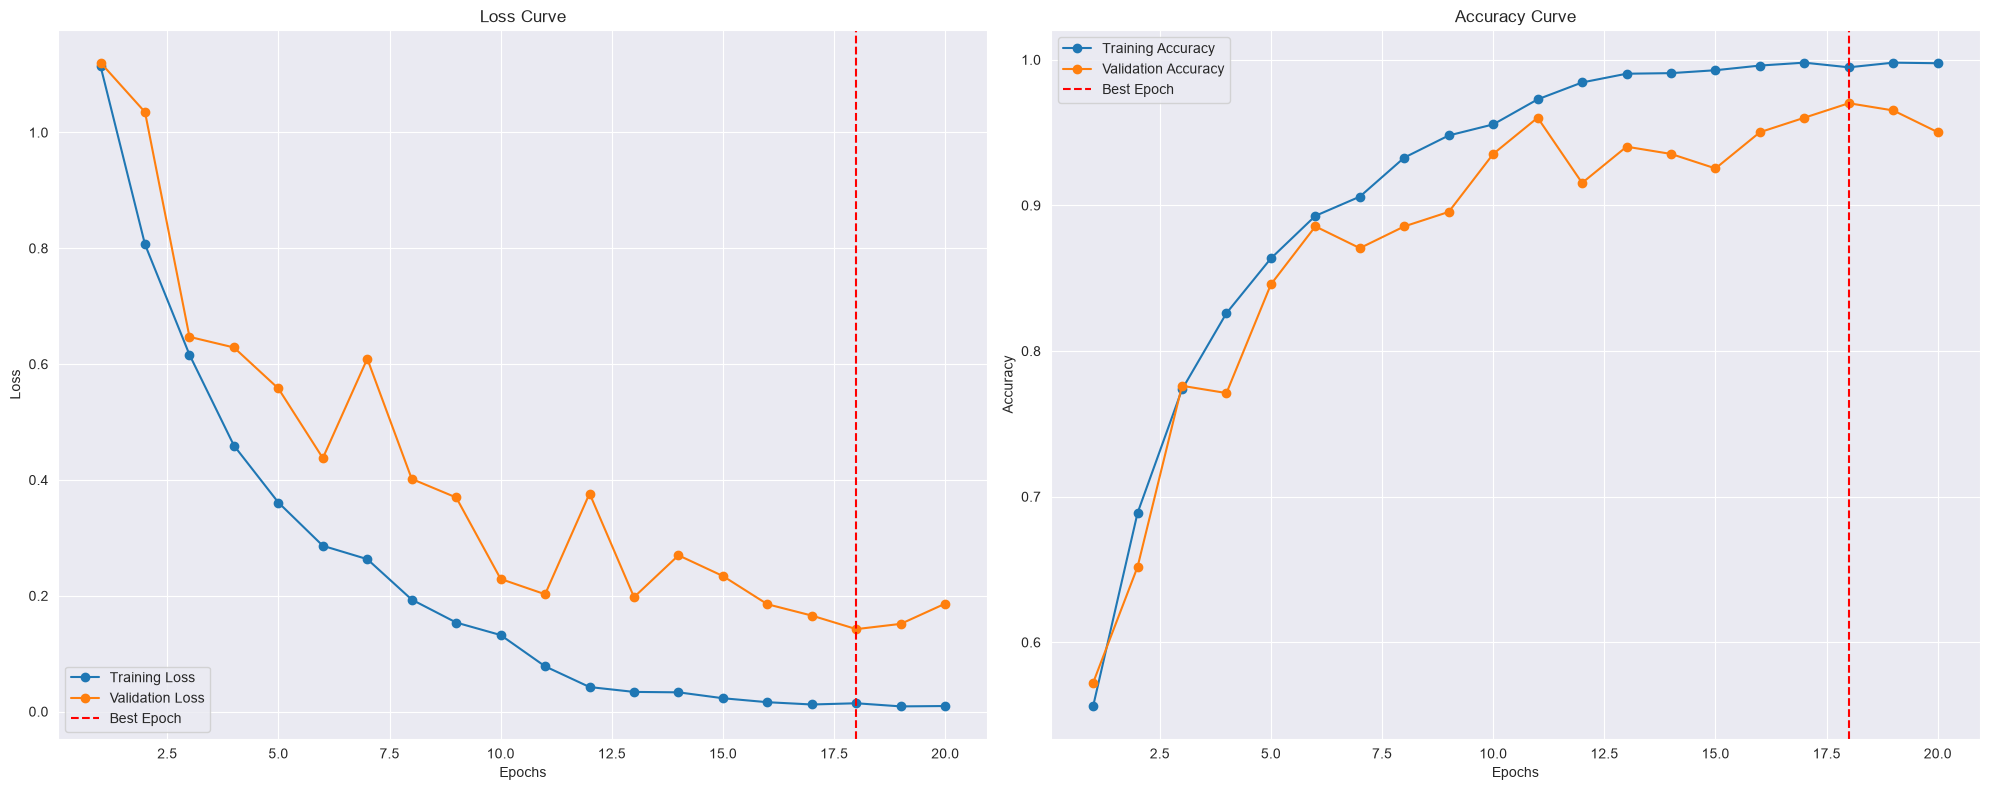


Training Report:
Total training time: 00:08:46
Total epochs run: 20
Best Training Loss: 0.0144 at epoch 18
Best Training Accuracy: 0.9948

Validation Report:
Best Validation Loss: 0.1424 at epoch 18
Best Validation Accuracy: 0.9701
Final Validation Loss: 0.1864
Final Validation Accuracy: 0.9502

Inference Report:
Total Inference Time (Validation only): 00:01:26
Accuracy:    0.95025
Recall:      0.95025
Precision:   0.95429
F1 Score:    0.95041
MCC:         0.93849
PR AUC:      0.98960
Kappa:       0.93753
Specificity: 0.98775

Fold 3 metrics:
  accuracy: 0.9502
  recall: 0.9502
  precision: 0.9543
  f1: 0.9504
  mcc: 0.9385
  pr_auc: 0.9896
  kappa: 0.9375
  specificity: 0.9877
Saved fold 3 checkpoint -> resnest50d_fold3.pth
Deleted augmentation directory: D:\BPLD Dataset\CV_TrainAug\fold_3

FOLD 4/5 (train=806, val=201)

Processing class: Anthracnose
Original images saved: 184


 85%|████████▌ | 157/184 [00:00<00:00, 177.73it/s]


Augmented images created: 316
Total images in class 'Anthracnose': 500

Processing class: Healthy
Original images saved: 177


 91%|█████████ | 161/177 [00:00<00:00, 181.03it/s]


Augmented images created: 323
Total images in class 'Healthy': 500

Processing class: Leaf Crinckle
Original images saved: 122


...

Validation Loss: 0.2071, Validation Accuracy: 0.9403
Training Loss: 0.0836, Training Accuracy: 0.9716
Patience Counter: 1/5

Epoch 13/20
------------------------------


Validation Loss: 0.1538, Validation Accuracy: 0.9701
Training Loss: 0.0293, Training Accuracy: 0.9888
Patience Counter: 2/5

Epoch 14/20
------------------------------


Validation Loss: 0.1850, Validation Accuracy: 0.9552
Training Loss: 0.0224, Training Accuracy: 0.9912
Patience Counter: 3/5

Epoch 15/20
------------------------------


Validation Loss: 0.1267, Validation Accuracy: 0.9652
Training Loss: 0.0213, Training Accuracy: 0.9928
Patience Counter: 4/5

Epoch 16/20
------------------------------


Validation Loss: 0.1682, Validation Accuracy: 0.9701
Training Loss: 0.0152, Training Accuracy: 0.9944
Patience Counter: 5/5
Early stopping triggered at epoch 16.


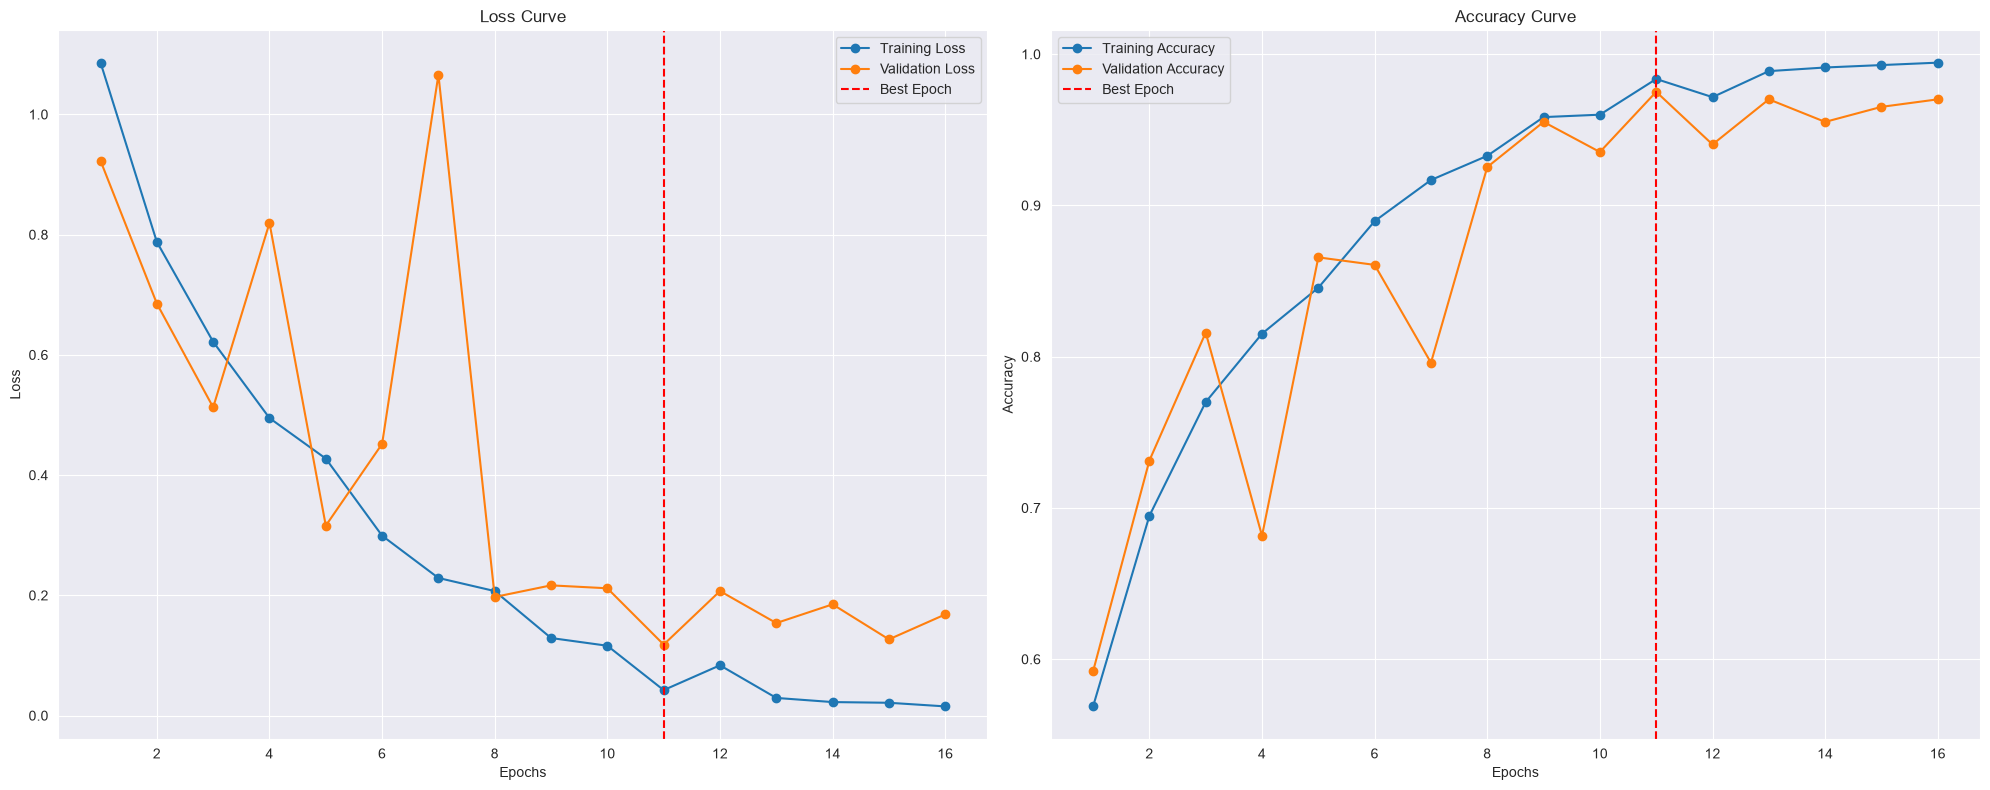


Training Report:
Total training time: 00:06:50
Total epochs run: 16
Best Training Loss: 0.0423 at epoch 11
Best Training Accuracy: 0.9836

Validation Report:
Best Validation Loss: 0.1180 at epoch 11
Best Validation Accuracy: 0.9751
Final Validation Loss: 0.1682
Final Validation Accuracy: 0.9701

Inference Report:
Total Inference Time (Validation only): 00:01:07
Accuracy:    0.97015
Recall:      0.97015
Precision:   0.97155
F1 Score:    0.97037
MCC:         0.96275
PR AUC:      0.99174
Kappa:       0.96248
Specificity: 0.99252

Fold 4 metrics:
  accuracy: 0.9701
  recall: 0.9701
  precision: 0.9716
  f1: 0.9704
  mcc: 0.9627
  pr_auc: 0.9917
  kappa: 0.9625
  specificity: 0.9925
Saved fold 4 checkpoint -> resnest50d_fold4.pth
Deleted augmentation directory: D:\BPLD Dataset\CV_TrainAug\fold_4

FOLD 5/5 (train=806, val=201)

Processing class: Anthracnose
Original images saved: 184


 85%|████████▌ | 157/184 [00:00<00:00, 177.34it/s]


Augmented images created: 316
Total images in class 'Anthracnose': 500

Processing class: Healthy
Original images saved: 177


 91%|█████████ | 161/177 [00:00<00:00, 188.42it/s]


Augmented images created: 323
Total images in class 'Healthy': 500

Processing class: Leaf Crinckle
Original images saved: 122


...

Validation Loss: 0.1496, Validation Accuracy: 0.9701
Training Loss: 0.0641, Training Accuracy: 0.9816
Patience Counter: 1/5

Epoch 14/20
------------------------------


Validation Loss: 0.1535, Validation Accuracy: 0.9701
Training Loss: 0.0208, Training Accuracy: 0.9936
Patience Counter: 2/5

Epoch 15/20
------------------------------


Validation Loss: 0.1776, Validation Accuracy: 0.9701
Training Loss: 0.0149, Training Accuracy: 0.9972
Patience Counter: 3/5

Epoch 16/20
------------------------------


Validation Loss: 0.1493, Validation Accuracy: 0.9701
Training Loss: 0.0131, Training Accuracy: 0.9968
Patience Counter: 4/5

Epoch 17/20
------------------------------


Validation Loss: 0.1761, Validation Accuracy: 0.9602
Training Loss: 0.0098, Training Accuracy: 0.9984
Patience Counter: 5/5
Early stopping triggered at epoch 17.


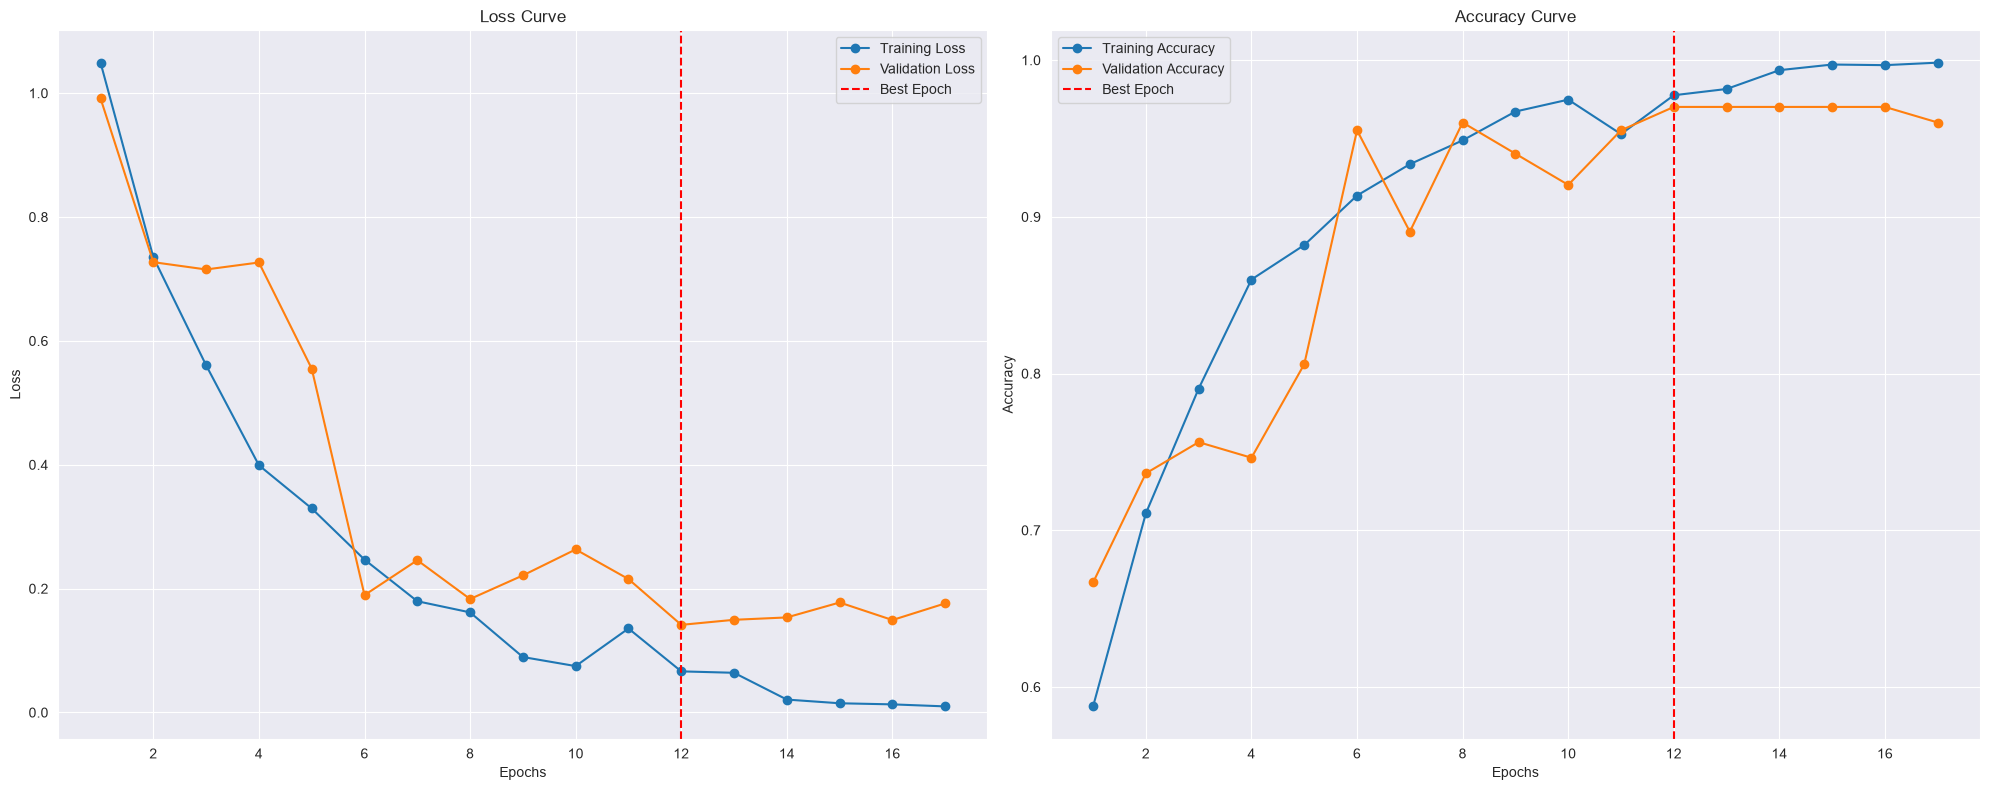


Training Report:
Total training time: 00:07:02
Total epochs run: 17
Best Training Loss: 0.0664 at epoch 12
Best Training Accuracy: 0.9776

Validation Report:
Best Validation Loss: 0.1415 at epoch 12
Best Validation Accuracy: 0.9701
Final Validation Loss: 0.1761
Final Validation Accuracy: 0.9602

Inference Report:
Total Inference Time (Validation only): 00:01:10
Accuracy:    0.96020
Recall:      0.96020
Precision:   0.96221
F1 Score:    0.96011
MCC:         0.95044
PR AUC:      0.99113
Kappa:       0.94988
Specificity: 0.98983

Fold 5 metrics:
  accuracy: 0.9602
  recall: 0.9602
  precision: 0.9622
  f1: 0.9601
  mcc: 0.9504
  pr_auc: 0.9911
  kappa: 0.9499
  specificity: 0.9898
Saved fold 5 checkpoint -> resnest50d_fold5.pth
Deleted augmentation directory: D:\BPLD Dataset\CV_TrainAug\fold_5

Per-fold results:
      accuracy  recall  precision      f1     mcc  pr_auc   kappa  specificity
fold                                                                          
1       0.9802  0.98

In [16]:
import os
import gc
import shutil
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import timm

from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold

from my_dataset import CustomImageDataset


# ============================================================
# CONFIG
# ============================================================
N_FOLDS = 5

# Number of total images per class after offline augmentation
TARGET_PER_CLASS = 500

RANDOM_STATE = 42

BASE_AUG_DIR = r"D:\BPLD Dataset\CV_TrainAug"

# Delete fold augmentation directory after training
CLEANUP_BETWEEN_FOLDS = True

NUM_EPOCHS = 20
PATIENCE = 5
MIN_DELTA = 0.001

BATCH_SIZE = 32
NUM_WORKERS = 4

MODEL_NAME = "resnest50d"
PRETRAINED = False

BASE_LR = 5e-4
WEIGHT_DECAY = 1e-4


# ============================================================
# DATAFRAME PREPARATION
# ============================================================
df = df.reset_index(drop=True)

print(
    f"Full dataset: {len(df)} images "
    f"across {df['labels'].nunique()} classes"
)

print(
    f"Running {N_FOLDS}-fold CV with "
    f"offline Albumentations augmentation"
)


# ============================================================
# LABEL MAPPING
# ============================================================
label_mapping = {
    label: idx
    for idx, label in enumerate(df["labels"].unique())
}

num_classes = len(label_mapping)

print(f"Number of classes: {num_classes}")
print(f"Label mapping: {label_mapping}")


# ============================================================
# TRANSFORMS
#
# Offline augmentation has already been performed using
# Albumentations.
#
# Therefore, do NOT apply the same random augmentations again.
# We only convert to tensor and normalize here.
# ============================================================

train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


val_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# RESNEST MODEL BUILDER
# ============================================================
def load_model(model_name, num_classes, pretrained=False):

    model = timm.create_model(
        model_name,
        pretrained=pretrained
    )

    # --------------------------------------------------------
    # Models using "classifier"
    # --------------------------------------------------------
    if hasattr(model, "classifier"):

        in_features = model.classifier.in_features

        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    # --------------------------------------------------------
    # Models using "fc"
    # ResNeSt uses this branch
    # --------------------------------------------------------
    elif hasattr(model, "fc"):

        in_features = model.fc.in_features

        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    else:
        raise ValueError(
            f"Unexpected classifier layer name "
            f"for model: {model_name}"
        )

    return model


# ============================================================
# SINGLE-FOLD TRAINING
#
# 1. Split train/validation
# 2. Offline Albumentations augmentation ONLY on fold training set
# 3. Load augmented images
# 4. Build datasets/loaders
# 5. Create fresh ResNeSt-50d
# 6. Train
# 7. Evaluate
# 8. Save checkpoint
# 9. Remove augmented images
# ============================================================
def run_single_fold(
    fold_idx,
    fold_train_df,
    fold_val_df
):

    print(
        f"\n{'=' * 70}\n"
        f"FOLD {fold_idx}/{N_FOLDS} "
        f"(train={len(fold_train_df)}, "
        f"val={len(fold_val_df)})\n"
        f"{'=' * 70}"
    )

    # ========================================================
    # 1. CREATE ISOLATED AUGMENTATION DIRECTORY FOR THIS FOLD
    # ========================================================

    fold_aug_dir = os.path.join(
        BASE_AUG_DIR,
        f"fold_{fold_idx}"
    )

    if os.path.exists(fold_aug_dir):
        shutil.rmtree(fold_aug_dir)

    os.makedirs(
        fold_aug_dir,
        exist_ok=True
    )

    # ========================================================
    # 2. OFFLINE AUGMENTATION
    #
    # Uses the NEW Albumentations implementation:
    #
    # offline_augment_train(
    #     train_df,
    #     output_root,
    #     target_per_class
    # )
    #
    # IMPORTANT:
    # Only fold_train_df is augmented.
    # Validation images are NEVER augmented.
    # ========================================================

    offline_augment_train(
        fold_train_df,
        fold_aug_dir,
        target_per_class=TARGET_PER_CLASS
    )

    # ========================================================
    # 3. LOAD AUGMENTED TRAINING DATA
    # ========================================================

    fold_train_expanded_df = loading_the_data(
        fold_aug_dir
    )

    print(
        f"Expanded training set for fold {fold_idx}: "
        f"{len(fold_train_expanded_df)} images"
    )

    # ========================================================
    # 4. LABELS
    # ========================================================

    fold_train_labels = (
        fold_train_expanded_df["labels"]
        .map(label_mapping)
        .values
    )

    fold_val_labels = (
        fold_val_df["labels"]
        .map(label_mapping)
        .values
    )

    # ========================================================
    # 5. DATASETS
    # ========================================================

    fold_train_dataset = CustomImageDataset(
        fold_train_expanded_df["filepaths"].values,
        fold_train_labels,
        transform=train_transform
    )

    fold_val_dataset = CustomImageDataset(
        fold_val_df["filepaths"].values,
        fold_val_labels,
        transform=val_test_transform
    )

    # ========================================================
    # 6. DATA LOADERS
    # ========================================================

    fold_train_loader = DataLoader(
        fold_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    # ========================================================
    # 7. FRESH RESNEST-50D MODEL
    # ========================================================

    model = load_model(
        MODEL_NAME,
        num_classes,
        pretrained=PRETRAINED
    ).to(device)

    print(
        f"Model: {MODEL_NAME}"
    )

    # ========================================================
    # 8. LOSS
    # ========================================================

    criterion = nn.CrossEntropyLoss()

    # ========================================================
    # 9. OPTIMIZER
    # ========================================================

    optimizer = optim.AdamW(
        model.parameters(),
        lr=BASE_LR,
        weight_decay=WEIGHT_DECAY
    )

    # ========================================================
    # 10. COSINE LR SCHEDULER
    # ========================================================

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=NUM_EPOCHS,
        eta_min=1e-6
    )

    # ========================================================
    # 11. TRAIN
    # ========================================================

    train_model(
        model,
        fold_train_loader,
        fold_val_loader,
        criterion,
        optimizer,
        scheduler,
        num_epochs=NUM_EPOCHS,
        patience=PATIENCE,
        min_delta=MIN_DELTA
    )

    # ========================================================
    # 12. EVALUATE
    # ========================================================

    fold_metrics = evaluate_model_with_metrics(
        model,
        fold_val_loader
    )

    if fold_metrics is None:
        raise ValueError(
            "evaluate_model_with_metrics returned None. "
            "Make sure it returns a dictionary of scalar "
            "metrics such as {'accuracy': 0.95, ...}."
        )

    print(
        f"\nFold {fold_idx} metrics:"
    )

    for key, value in fold_metrics.items():
        print(f"  {key}: {value:.4f}")

    # ========================================================
    # 13. SAVE MODEL
    # ========================================================

    checkpoint_path = (
        f"{MODEL_NAME}_fold{fold_idx}.pth"
    )

    torch.save(
        model.state_dict(),
        checkpoint_path
    )

    print(
        f"Saved fold {fold_idx} checkpoint -> "
        f"{checkpoint_path}"
    )

    # ========================================================
    # 14. CLEANUP AUGMENTED DATA
    # ========================================================

    if CLEANUP_BETWEEN_FOLDS:

        if os.path.exists(fold_aug_dir):

            shutil.rmtree(
                fold_aug_dir
            )

            print(
                f"Deleted augmentation directory: "
                f"{fold_aug_dir}"
            )

    # ========================================================
    # 15. CLEAN MEMORY
    # ========================================================

    del model
    del optimizer
    del scheduler
    del fold_train_dataset
    del fold_val_dataset
    del fold_train_loader
    del fold_val_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return fold_metrics


# ============================================================
# STRATIFIED K-FOLD
# ============================================================
skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)


fold_results = []


# ============================================================
# RUN ALL FOLDS
# ============================================================
for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(
        df["filepaths"],
        df["labels"]
    ),
    start=1
):

    fold_train_df = (
        df.iloc[train_idx]
        .reset_index(drop=True)
    )

    fold_val_df = (
        df.iloc[val_idx]
        .reset_index(drop=True)
    )

    metrics = run_single_fold(
        fold_idx,
        fold_train_df,
        fold_val_df
    )

    metrics["fold"] = fold_idx

    fold_results.append(
        metrics
    )


# ============================================================
# SUMMARIZE CROSS-VALIDATION RESULTS
# ============================================================
def summarize_cv_results(fold_results):

    results_df = (
        pd.DataFrame(fold_results)
        .set_index("fold")
    )

    summary = results_df.agg(
        ["mean", "std"]
    )

    print("\nPer-fold results:")
    print(
        results_df.round(4)
    )

    print(
        f"\nMean ± Std across "
        f"{len(results_df)} folds:"
    )

    for col in results_df.columns:

        mean_value = summary.loc[
            "mean",
            col
        ]

        std_value = summary.loc[
            "std",
            col
        ]

        print(
            f"  {col}: "
            f"{mean_value:.4f} ± {std_value:.4f}"
        )

    return results_df, summary


# ============================================================
# FINAL CV RESULTS
# ============================================================
cv_results_df, cv_summary = summarize_cv_results(
    fold_results
)


# ============================================================
# SAVE RESULTS
# ============================================================
cv_results_df.to_csv(
    "resnest50d_cv_fold_results.csv"
)

cv_summary.to_csv(
    "resnest50d_cv_summary1.csv"
)

print(
    "\nCross-validation completed."
)

In [24]:
import pandas as pd
import io
from scipy.stats import ttest_rel

# 1. Load the data 
resnest_data = """fold,accuracy,recall,precision,f1,mcc,pr_auc,kappa,specificity
1,0.9455,  0.9455,     0.9479,  0.9461,  0.9320,  0.9906,  0.9316, 0.9862
2,0.9502, 0.9502,     0.9543,  0.9504,  0.9385,  0.9896,  0.9375,  0.9877
3,0.9701, 0.9701,     0.9716,  0.9704,  0.9627,  0.9917,  0.9625,  0.9925
4,0.9802, 0.9802,     0.9803,  0.9801,  0.9751,  0.9878,  0.9751,  0.9950
5,0.9602, 0.9602,     0.9622,  0.9601,  0.9504,  0.9911,  0.9499,  0.9898"""

proposed_data = """fold,accuracy,recall,precision,f1,mcc,pr_auc,kappa,specificity
1, 0.9703,  0.9703,     0.9706,  0.9703,  0.9627,  0.9961,  0.9626,   0.9926
2,  0.9604,  0.9604,     0.9613,  0.9606,  0.9504,  0.9910,  0.9503,    0.9901
3,   0.9802,  0.9802,     0.9803,  0.9802,  0.9754,  0.9942,  0.9822,    0.9949
4,   0.9851,  0.9851,     0.9856,  0.9851,  0.9813,  0.9955,  0.9812,   0.9963
5,  0.9701,  0.9701,     0.9711,  0.9702,  0.9626,  0.9902,  0.9624,  0.9923"""

df_resnest = pd.read_csv(io.StringIO(resnest_data))
df_proposed = pd.read_csv(io.StringIO(proposed_data))

# 2. Extract metrics (ignoring the 'fold' column)
metrics = df_resnest.columns.drop('fold')
results = []

# 3. Calculate Paired t-test for each metric
for metric in metrics:
    # ttest_rel compares two related samples
    stat, p_value = ttest_rel(df_proposed[metric], df_resnest[metric],)
    
    mean_resnest = df_resnest[metric].mean()
    mean_proposed = df_proposed[metric].mean()
    
    results.append({
        "Metric": metric,
        "ResNeSt Mean": mean_resnest,
        "Proposed Mean": mean_proposed,
        "t-Statistic": stat,
        "p-value": p_value
    })

# 4. Display Results (using .to_string() to avoid tabulate errors)
results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

     Metric  ResNeSt Mean  Proposed Mean  t-Statistic  p-value
   accuracy        0.9612         0.9732       3.5677   0.0234
     recall        0.9612         0.9732       3.5677   0.0234
  precision        0.9633         0.9738       3.3784   0.0278
         f1        0.9614         0.9733       3.6650   0.0215
        mcc        0.9517         0.9665       3.5421   0.0240
     pr_auc        0.9902         0.9934       2.1347   0.0997
      kappa        0.9513         0.9677       3.8794   0.0179
specificity        0.9902         0.9932       3.4166   0.0269


In [1]:
import pandas as pd
import io

# Load data (using your updated proposed data)
resnest_data = """fold,accuracy,recall,precision,f1,mcc,pr_auc,kappa,specificity
1,0.9455,  0.9455,     0.9479,  0.9461,  0.9320,  0.9906,  0.9316, 0.9862
2,0.9502, 0.9502,     0.9543,  0.9504,  0.9385,  0.9896,  0.9375,  0.9877
3,0.9701, 0.9701,     0.9716,  0.9704,  0.9627,  0.9917,  0.9625,  0.9925
4,0.9802, 0.9802,     0.9803,  0.9801,  0.9751,  0.9878,  0.9751,  0.9950
5,0.9602, 0.9602,     0.9622,  0.9601,  0.9504,  0.9911,  0.9499,  0.9898"""

proposed_data = """fold,accuracy,recall,precision,f1,mcc,pr_auc,kappa,specificity
1, 0.9703,  0.9703,     0.9706,  0.9703,  0.9627,  0.9961,  0.9626,   0.9926
2,  0.9604,  0.9604,     0.9613,  0.9606,  0.9504,  0.9910,  0.9503,    0.9901
3,   0.9802,  0.9802,     0.9803,  0.9802,  0.9754,  0.9942,  0.9822,    0.9949
4,   0.9851,  0.9851,     0.9856,  0.9851,  0.9813,  0.9955,  0.9812,   0.9963
5,  0.9701,  0.9701,     0.9711,  0.9702,  0.9626,  0.9902,  0.9624,  0.9923"""



df_resnest = pd.read_csv(io.StringIO(resnest_data))
df_proposed = pd.read_csv(io.StringIO(proposed_data))

def get_mean_std_summary(df, model_name):
    # Drop fold column and compute mean and std
    summary = df.drop(columns='fold').agg(['mean', 'std']).T
    summary[model_name] = summary.apply(lambda x: f"{x['mean']:.4f} ± {x['std']:.4f}", axis=1)
    return summary[[model_name]]

# Combine both models into a single comparative summary table
resnest_summary = get_mean_std_summary(df_resnest, "ResNeSt50d")
proposed_summary = get_mean_std_summary(df_proposed, "Proposed Model")

final_table = pd.concat([resnest_summary, proposed_summary], axis=1)
print(final_table.to_string())

                  ResNeSt50d   Proposed Model
accuracy     0.9612 ± 0.0142  0.9732 ± 0.0096
recall       0.9612 ± 0.0142  0.9732 ± 0.0096
precision    0.9633 ± 0.0130  0.9738 ± 0.0094
f1           0.9614 ± 0.0140  0.9733 ± 0.0096
mcc          0.9517 ± 0.0176  0.9665 ± 0.0121
pr_auc       0.9902 ± 0.0015  0.9934 ± 0.0027
kappa        0.9513 ± 0.0178  0.9677 ± 0.0137
specificity  0.9902 ± 0.0036  0.9932 ± 0.0024


# Model reliability Testing

In [50]:
"""
Model calibration evaluation for journal-quality reporting.

Fixes vs. the original version:
  1. Reports BOTH standard equal-width ECE/MCE (the number almost every
     paper reports, needed for direct comparison with prior work) AND
     adaptive equal-mass ECE/MCE (more robust to sparse high-confidence bins).
  2. Adds bootstrap confidence intervals for ECE, MCE, Brier, and NLL.
  3. Reliability diagram uses the standard stacked-bar style (accuracy bar +
     hatched confidence gap up to the diagonal), which reviewers recognize
     from Guo et al. (2017), shown side-by-side for both binning schemes.
  4. Explicitly documents that this is TOP-LABEL calibration (calibration of
     the arg-max prediction), not full per-class calibration -- state this
     scope in your methods text.
"""

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss


# --------------------------------------------------------------------------
# Core, reusable metric computation (used both for the point estimate and
# for every bootstrap resample, so there is exactly one implementation to
# trust).
# --------------------------------------------------------------------------
def _compute_ece_mce(confidences, accuracies_correct, n_bins=10, mode="standard"):
    """
    confidences: array of top-1 confidence per sample
    accuracies_correct: boolean array, True if the top-1 prediction was correct
    mode: 'standard' (equal-width bins) or 'adaptive' (equal-mass / quantile bins)

    Returns: ece, mce, bin_boundaries, bin_accuracies, bin_confidences, bin_counts
    """
    if mode == "standard":
        bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    elif mode == "adaptive":
        quantiles = np.linspace(0.0, 1.0, n_bins + 1)
        bin_boundaries = np.quantile(confidences, quantiles)
        bin_boundaries = np.unique(bin_boundaries)  # collapse duplicate edges
    else:
        raise ValueError(f"Unknown mode: {mode}")

    n_actual_bins = len(bin_boundaries) - 1
    ece, mce = 0.0, 0.0
    bin_accs, bin_confs, bin_counts = [], [], []

    n = len(confidences)
    for i in range(n_actual_bins):
        lo, hi = bin_boundaries[i], bin_boundaries[i + 1]
        if i == 0:
            in_bin = (confidences >= lo) & (confidences <= hi)
        else:
            in_bin = (confidences > lo) & (confidences <= hi)

        count = in_bin.sum()
        if count == 0:
            continue

        prop_in_bin = count / n
        bin_acc = accuracies_correct[in_bin].mean()
        bin_conf = confidences[in_bin].mean()
        gap = abs(bin_acc - bin_conf)

        ece += gap * prop_in_bin
        mce = max(mce, gap)

        bin_accs.append(bin_acc)
        bin_confs.append(bin_conf)
        bin_counts.append(count)

    return ece, mce, bin_boundaries, np.array(bin_accs), np.array(bin_confs), np.array(bin_counts)


def _bootstrap_ci(values, alpha=0.05):
    lo = np.percentile(values, 100 * alpha / 2)
    hi = np.percentile(values, 100 * (1 - alpha / 2))
    return lo, hi


def bootstrap_calibration_metrics(y_true, y_prob, confidences, y_pred, num_classes,
                                   n_bins=10, n_boot=1000, alpha=0.05, seed=0):
    """
    Bootstrap CIs (percentile method) for ECE (both modes), MCE (both modes),
    Brier score, and NLL. Resamples the test set with replacement n_boot times.
    """
    rng = np.random.default_rng(seed)
    n = len(y_true)
    correct = (y_pred == y_true)

    boot_std_ece, boot_std_mce = [], []
    boot_adp_ece, boot_adp_mce = [], []
    boot_brier, boot_nll = [], []

    y_true_one_hot = np.eye(num_classes)[y_true]

    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)

        ece_s, mce_s, *_ = _compute_ece_mce(confidences[idx], correct[idx], n_bins, "standard")
        ece_a, mce_a, *_ = _compute_ece_mce(confidences[idx], correct[idx], n_bins, "adaptive")
        boot_std_ece.append(ece_s); boot_std_mce.append(mce_s)
        boot_adp_ece.append(ece_a); boot_adp_mce.append(mce_a)

        boot_brier.append(np.mean(np.sum((y_prob[idx] - y_true_one_hot[idx]) ** 2, axis=1)))
        boot_nll.append(log_loss(y_true[idx], y_prob[idx], labels=np.arange(num_classes)))

    def summarize(vals):
        vals = np.array(vals)
        lo, hi = _bootstrap_ci(vals, alpha)
        return {"mean": vals.mean(), "std": vals.std(), "ci_low": lo, "ci_high": hi}

    return {
        "Standard_ECE": summarize(boot_std_ece),
        "Standard_MCE": summarize(boot_std_mce),
        "Adaptive_ECE": summarize(boot_adp_ece),
        "Adaptive_MCE": summarize(boot_adp_mce),
        "Brier_Score": summarize(boot_brier),
        "NLL": summarize(boot_nll),
    }


# --------------------------------------------------------------------------
# Main entry point
# --------------------------------------------------------------------------
def calculate_calibration_and_plot(model, test_loader, num_classes, n_bins=10,
                                    device="cuda", save_path="reliability_diagram.png",
                                    n_boot=1000, seed=0):
    """
    Evaluates TOP-LABEL calibration (calibration of the arg-max prediction).
    Reports standard + adaptive ECE/MCE, Brier score, NLL, each with a
    bootstrap 95% CI, and saves a dual reliability diagram.
    """
    model.eval()

    y_true, y_prob, y_pred, confidences = [], [], [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            probs = F.softmax(logits, dim=1)
            confs, preds = torch.max(probs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_prob.extend(probs.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            confidences.extend(confs.cpu().numpy())

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = np.array(y_pred)
    confidences = np.array(confidences)
    correct = (y_pred == y_true)

    # Point estimates
    ece_std, mce_std, bounds_std, accs_std, confs_std, counts_std = _compute_ece_mce(
        confidences, correct, n_bins, "standard")
    ece_adp, mce_adp, bounds_adp, accs_adp, confs_adp, counts_adp = _compute_ece_mce(
        confidences, correct, n_bins, "adaptive")

    y_true_one_hot = np.eye(num_classes)[y_true]
    brier_score = np.mean(np.sum((y_prob - y_true_one_hot) ** 2, axis=1))
    nll = log_loss(y_true, y_prob, labels=np.arange(num_classes))

    # Bootstrap CIs
    ci = bootstrap_calibration_metrics(y_true, y_prob, confidences, y_pred, num_classes,
                                        n_bins=n_bins, n_boot=n_boot, seed=seed)

    metrics = {
        "Standard_ECE": ece_std, "Standard_MCE": mce_std,
        "Adaptive_ECE": ece_adp, "Adaptive_MCE": mce_adp,
        "Brier_Score": brier_score, "NLL": nll,
    }

    _plot_dual_reliability_diagram(
        bounds_std, accs_std, confs_std, ece_std, mce_std,
        bounds_adp, accs_adp, confs_adp, ece_adp, mce_adp,
        save_path,
    )

    print("\n--- Calibration Metrics (point estimate | 95% bootstrap CI) ---")
    for k, v in metrics.items():
        c = ci[k]
        print(f"{k}: {v:.4f}  |  95% CI [{c['ci_low']:.4f}, {c['ci_high']:.4f}]  (boot mean {c['mean']:.4f}, std {c['std']:.4f})")

    return {"point_estimates": metrics, "bootstrap": ci}


def _plot_dual_reliability_diagram(bounds_std, accs_std, confs_std, ece_std, mce_std,
                                    bounds_adp, accs_adp, confs_adp, ece_adp, mce_adp,
                                    save_path):
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))

    for ax, bounds, accs, confs, ece, mce, title in [
        (axes[0], bounds_std, accs_std, confs_std, ece_std, mce_std, "Standard (Equal-Width) Bins"),
        (axes[1], bounds_adp, accs_adp, confs_adp, ece_adp, mce_adp, "Adaptive (Equal-Mass) Bins"),
    ]:
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect Calibration")
        n = len(accs)
        for i in range(n):
            left = bounds[i]
            width = bounds[i + 1] - bounds[i]
            ax.bar(left, accs[i], width=width, align="edge", color="steelblue",
                    alpha=0.85, edgecolor="black", label="Accuracy" if i == 0 else "")
            gap_height = confs[i] - accs[i]
            if gap_height > 0:
                ax.bar(left, gap_height, width=width, align="edge", bottom=accs[i],
                        color="firebrick", alpha=0.4, hatch="//", edgecolor="firebrick",
                        label="Confidence Gap" if i == 0 else "")

        ax.set_xlabel("Confidence")
        ax.set_ylabel("Accuracy")
        ax.set_title(f"{title}\nECE: {ece:.4f} | MCE: {mce:.4f}")
        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.0])
        ax.legend(loc="upper left", fontsize=9)
        ax.grid(True, linestyle=":", alpha=0.5)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.close()
    print(f"Saved dual reliability diagram to {save_path}")




In [51]:
model.eval()

# 3. Run Calibration Diagnostics
print("\n[ Running Calibration Analysis on Test Set ]")
calibration_metrics = calculate_calibration_and_plot(
    model=model,
    test_loader=test_loader,
    num_classes=num_classes,
    device=device,
    save_path="test_reliability_diagram2.png",
    n_boot=1000,   # set lower (e.g. 200) for a quick check, 1000 for the final paper run
)


[ Running Calibration Analysis on Test Set ]
Saved dual reliability diagram to test_reliability_diagram2.png

--- Calibration Metrics (point estimate | 95% bootstrap CI) ---
Standard_ECE: 0.0881  |  95% CI [0.0575, 0.1136]  (boot mean 0.0895, std 0.0141)
Standard_MCE: 0.5364  |  95% CI [0.3551, 0.5364]  (boot mean 0.4956, std 0.0623)
Adaptive_ECE: 0.0918  |  95% CI [0.0749, 0.1251]  (boot mean 0.0988, std 0.0126)
Adaptive_MCE: 0.2077  |  95% CI [0.1108, 0.3960]  (boot mean 0.2400, std 0.0874)
Brier_Score: 0.0587  |  95% CI [0.0190, 0.1110]  (boot mean 0.0578, std 0.0237)
NLL: 0.1868  |  95% CI [0.1087, 0.2950]  (boot mean 0.1848, std 0.0482)


# XAI

In [52]:
"""
xai_pipeline.py
Top-level orchestrator: runs Grad-CAM + Score-CAM qualitative visualization
and quantitative evaluation (Deletion/Insertion faithfulness, optionally
IoU + Pointing Game if you supply ground-truth masks), and writes
paper-ready figures, a CSV, and a formatted results table.

Requires: xai_cam.py, xai_metrics.py, xai_visualize.py in the same directory
(or on your PYTHONPATH).
"""

import os
import csv
import random

import numpy as np
import torch
import torch.nn.functional as F

from xai_cam import GradCAM, ScoreCAM, overlay_cam_on_image
from xai_metrics import deletion_insertion, compute_iou, pointing_game_hit, generate_pseudo_lesion_mask
from xai_visualize import plot_qualitative_grid, plot_deletion_insertion_curves


def _denormalize_to_01(img_chw, mean, std):
    if mean is None:
        return img_chw.clamp(0, 1)
    # FIX: Explicitly assign mean and std to the same device as the incoming image
    mean_t = torch.tensor(mean, device=img_chw.device).view(-1, 1, 1)
    std_t = torch.tensor(std, device=img_chw.device).view(-1, 1, 1)
    return (img_chw * std_t + mean_t).clamp(0, 1)


def _to_hwc_numpy(img_chw01):
    return img_chw01.permute(1, 2, 0).cpu().numpy()


def _index_by_class(dataset, num_classes):
    """Returns {class_idx: [dataset_indices]}. Assumes dataset[i] -> (image, label)."""
    buckets = {c: [] for c in range(num_classes)}
    for i in range(len(dataset)):
        _, label = dataset[i]
        label = int(label)
        buckets[label].append(i)
    return buckets


def run_xai_evaluation(model, test_dataset, class_names, target_layer, device="cuda",
                        mean=None, std=None,
                        n_qual_samples_per_class=1,
                        n_quant_samples_per_class=8,
                        deletion_insertion_step_frac=0.02,
                        scorecam_max_channels=64,
                        gt_masks=None,
                        use_pseudo_masks_if_missing=False,
                        save_dir="xai_outputs",
                        reshape_transform=None,
                        use_predicted_class=True,
                        seed=0, num_workers=0):
    """
    model: your trained classifier, already moved to `device`.
    test_dataset: a torch Dataset yielding (image_tensor, label) where image_tensor is
        whatever your model expects (normalized if you trained with normalization).
    class_names: list[str], index-aligned with your label integers.
    target_layer: an nn.Module inside `model` whose output CAMs are computed from --
        typically the last convolutional block before global pooling.
    mean/std: normalization stats used by test_dataset's transform.
    gt_masks: optional dict {dataset_index: (H,W) binary numpy array} of REAL annotations.
    use_predicted_class: if True, CAMs/metrics explain the MODEL'S OWN prediction.

    Returns a dict with 'qualitative_path', 'deletion_insertion_path', 'per_class_results',
    'overall_results', and 'csv_path'.
    """
    os.makedirs(save_dir, exist_ok=True)
    random.seed(seed)
    np.random.seed(seed)

    model.to(device)
    model.eval()
    num_classes = len(class_names)
    buckets = _index_by_class(test_dataset, num_classes)

    # ----------------------------------------------------------------
    # 1. QUALITATIVE: pick a few samples per class, compute Grad-CAM + Score-CAM
    # ----------------------------------------------------------------
    qual_samples = []
    for c in range(num_classes):
        idxs = buckets[c]
        if len(idxs) == 0:
            continue
        chosen = random.sample(idxs, min(n_qual_samples_per_class, len(idxs)))
        for idx in chosen:
            img, label = test_dataset[idx]
            img = img.to(device)
            img_01 = _denormalize_to_01(img, mean, std)
            orig_hwc = _to_hwc_numpy(img_01)

            target_cls = None if use_predicted_class else int(label)

            gradcam = GradCAM(model, target_layer, reshape_transform=reshape_transform)
            gc_cam, gc_class, _ = gradcam(img.unsqueeze(0), target_class=target_cls)
            gradcam.remove_hooks()

            scorecam = ScoreCAM(model, target_layer, reshape_transform=reshape_transform,
                                 max_channels=scorecam_max_channels)
            sc_cam, sc_class, _ = scorecam(img.unsqueeze(0), target_class=target_cls)
            scorecam.remove_hooks()

            gc_overlay = overlay_cam_on_image(orig_hwc, gc_cam[0])
            sc_overlay = overlay_cam_on_image(orig_hwc, sc_cam)

            qual_samples.append({
                "class_name": class_names[c],
                "orig": orig_hwc,
                "gradcam_overlay": gc_overlay,
                "scorecam_overlay": sc_overlay,
            })

    qual_path = os.path.join(save_dir, "qualitative_cam_grid1.png")
    plot_qualitative_grid(qual_samples, qual_path)

    # ----------------------------------------------------------------
    # 2. QUANTITATIVE: Deletion/Insertion (+ optional IoU / Pointing Game)
    # ----------------------------------------------------------------
    per_class_results = {c: {
        "gradcam_deletion_auc": [], "gradcam_insertion_auc": [],
        "scorecam_deletion_auc": [], "scorecam_insertion_auc": [],
        "gradcam_iou": [], "scorecam_iou": [],
        "gradcam_pointing_hit": [], "scorecam_pointing_hit": [],
    } for c in range(num_classes)}

    per_class_mean_curves = {}  # for plotting: one representative averaged curve per class

    pseudo_mask_warned = False
    localization_evaluated = False

    for c in range(num_classes):
        idxs = buckets[c]
        if len(idxs) == 0:
            continue
        chosen = random.sample(idxs, min(n_quant_samples_per_class, len(idxs)))

        del_curves, ins_curves = [], []

        for idx in chosen:
            img, label = test_dataset[idx]
            img = img.to(device)
            img_01 = _denormalize_to_01(img, mean, std)
            target_cls = None if use_predicted_class else int(label)

            gradcam = GradCAM(model, target_layer, reshape_transform=reshape_transform)
            gc_cam, gc_class, _ = gradcam(img.unsqueeze(0), target_class=target_cls)
            gradcam.remove_hooks()
            gc_class = int(gc_class[0])

            scorecam = ScoreCAM(model, target_layer, reshape_transform=reshape_transform,
                                 max_channels=scorecam_max_channels)
            sc_cam, sc_class, _ = scorecam(img.unsqueeze(0), target_class=target_cls)
            scorecam.remove_hooks()

            # --- Faithfulness (no GT needed) ---
            gc_res = deletion_insertion(model, img_01, gc_cam[0], gc_class, device,
                                         step_frac=deletion_insertion_step_frac,
                                         mean=mean, std=std)
            sc_res = deletion_insertion(model, img_01, sc_cam, sc_class, device,
                                         step_frac=deletion_insertion_step_frac,
                                         mean=mean, std=std)

            per_class_results[c]["gradcam_deletion_auc"].append(gc_res["deletion_auc"])
            per_class_results[c]["gradcam_insertion_auc"].append(gc_res["insertion_auc"])
            per_class_results[c]["scorecam_deletion_auc"].append(sc_res["deletion_auc"])
            per_class_results[c]["scorecam_insertion_auc"].append(sc_res["insertion_auc"])
            del_curves.append(gc_res["deletion_curve"])
            ins_curves.append(gc_res["insertion_curve"])

            # --- Localization (needs GT) ---
            gt_mask = None
            if gt_masks is not None and idx in gt_masks:
                gt_mask = gt_masks[idx]
            elif use_pseudo_masks_if_missing:
                if not pseudo_mask_warned:
                    print("WARNING: no gt_masks supplied for this index -- using heuristic "
                          "pseudo-masks (generate_pseudo_lesion_mask). These are NOT verified "
                          "ground truth; disclose this clearly if you report IoU/Pointing Game "
                          "numbers derived from them.")
                    pseudo_mask_warned = True
                gt_mask = generate_pseudo_lesion_mask(orig_hwc := _to_hwc_numpy(img_01))

            if gt_mask is not None:
                localization_evaluated = True
                per_class_results[c]["gradcam_iou"].append(compute_iou(gc_cam[0], gt_mask))
                per_class_results[c]["scorecam_iou"].append(compute_iou(sc_cam, gt_mask))
                per_class_results[c]["gradcam_pointing_hit"].append(pointing_game_hit(gc_cam[0], gt_mask))
                per_class_results[c]["scorecam_pointing_hit"].append(pointing_game_hit(sc_cam, gt_mask))

        if del_curves:
            min_len = min(len(x) for x in del_curves)
            del_stack = np.stack([x[:min_len] for x in del_curves])
            ins_stack = np.stack([x[:min_len] for x in ins_curves])
            per_class_mean_curves[class_names[c]] = {
                "deletion_curve": del_stack.mean(axis=0),
                "deletion_auc": float(np.mean(per_class_results[c]["gradcam_deletion_auc"])),
                "insertion_curve": ins_stack.mean(axis=0),
                "insertion_auc": float(np.mean(per_class_results[c]["gradcam_insertion_auc"])),
            }

    di_path = os.path.join(save_dir, "deletion_insertion_curves.png")
    plot_deletion_insertion_curves(per_class_mean_curves, di_path)

    # ----------------------------------------------------------------
    # 3. Aggregate + write CSV + print paper-ready table
    # ----------------------------------------------------------------
    def summarize(values):
        arr = np.array(values, dtype=float)
        if len(arr) == 0:
            return None, None
        return float(arr.mean()), float(arr.std())

    csv_path = os.path.join(save_dir, "xai_quantitative_results.csv")
    fieldnames = ["class", "gradcam_deletion_auc", "gradcam_insertion_auc",
                  "scorecam_deletion_auc", "scorecam_insertion_auc",
                  "gradcam_iou", "scorecam_iou",
                  "gradcam_pointing_game", "scorecam_pointing_game"]

    rows = []
    overall = {k: [] for k in fieldnames if k != "class"}

    for c in range(num_classes):
        r = per_class_results[c]
        row = {"class": class_names[c]}
        for key, values in [
            ("gradcam_deletion_auc", r["gradcam_deletion_auc"]),
            ("gradcam_insertion_auc", r["gradcam_insertion_auc"]),
            ("scorecam_deletion_auc", r["scorecam_deletion_auc"]),
            ("scorecam_insertion_auc", r["scorecam_insertion_auc"]),
            ("gradcam_iou", r["gradcam_iou"]),
            ("scorecam_iou", r["scorecam_iou"]),
        ]:
            m, s = summarize(values)
            row[key] = f"{m:.4f} ± {s:.4f}" if m is not None else "N/A"
            if m is not None:
                overall[key].extend(values)

        for key, values in [
            ("gradcam_pointing_game", r["gradcam_pointing_hit"]),
            ("scorecam_pointing_game", r["scorecam_pointing_hit"]),
        ]:
            if values:
                hit_rate = float(np.mean(values))
                row[key] = f"{hit_rate:.4f}"
                overall[key].extend(values)
            else:
                row[key] = "N/A"

        rows.append(row)

    overall_row = {"class": "OVERALL"}
    for key in fieldnames:
        if key == "class":
            continue
        if not overall[key]:
            overall_row[key] = "N/A"
        elif "pointing_game" in key:
            overall_row[key] = f"{float(np.mean(overall[key])):.4f}"
        else:
            m, s = summarize(overall[key])
            overall_row[key] = f"{m:.4f} ± {s:.4f}"
    rows.append(overall_row)

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

    # --- Print a paper-ready Markdown table ---
    print("\n=== XAI Quantitative Evaluation (paper-ready table) ===\n")
    header = "| Class | Del. AUC (GC) | Ins. AUC (GC) | Del. AUC (SC) | Ins. AUC (SC) |"
    sep = "|---|---|---|---|---|"
    if localization_evaluated:
        header += " IoU (GC) | IoU (SC) | PG (GC) | PG (SC) |"
        sep += "---|---|---|---|"
    print(header)
    print(sep)
    for row in rows:
        line = f"| {row['class']} | {row['gradcam_deletion_auc']} | {row['gradcam_insertion_auc']} | " \
               f"{row['scorecam_deletion_auc']} | {row['scorecam_insertion_auc']} |"
        if localization_evaluated:
            line += f" {row['gradcam_iou']} | {row['scorecam_iou']} | " \
                    f"{row['gradcam_pointing_game']} | {row['scorecam_pointing_game']} |"
        print(line)

    if not localization_evaluated:
        print("\nNOTE: IoU / Pointing Game were NOT computed -- no ground-truth lesion masks "
              "were supplied (gt_masks=None, use_pseudo_masks_if_missing=False). To report "
              "localization metrics in your paper, annotate a subset of the test set with "
              "lesion bounding boxes/masks and pass them via gt_masks.")

    print(f"\nSaved: {qual_path}")
    print(f"Saved: {di_path}")
    print(f"Saved: {csv_path}")

    return {
        "qualitative_path": qual_path,
        "deletion_insertion_path": di_path,
        "csv_path": csv_path,
        "per_class_results": per_class_results,
        "rows": rows,
    }

In [53]:
print(label_mapping)

{'Anthracnose': 0, 'Healthy': 1, 'Leaf Crinckle': 2, 'Powdery Mildew': 3, 'Yellow Mosaic': 4}


In [55]:
model.load_state_dict(torch.load("ProposedBean1.pth", map_location=device))
model.to(device)
model.eval()
# 1. Reordered class names to perfectly match your dataset mapping:
# 0: Healthy, 1: Yellow Mosaic, 2: Insect, 3: Cercospora leaf spot, 4: Leaf Crinkle
class_names = [
    "Anthracnose", 
    "Healthy", 
    "Leaf Crinckle", 
    "Powdery Mildew", 
    "Yellow Mosaic"
]
norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]
# 2. Point to the last spatial block in LightNeStV2
target_layer = model.layer4[-1]

# 3. Run the evaluation
results = run_xai_evaluation(
    model, 
    test_dataset, 
    class_names, 
    target_layer,
    device=device,
    mean=norm_mean, 
    std=norm_std,
    n_qual_samples_per_class=2,   
    n_quant_samples_per_class=15, 
    deletion_insertion_step_frac=0.02,
    scorecam_max_channels=64,     
    gt_masks=None,
    use_pseudo_masks_if_missing=False,
    num_workers=0,  # Keeps pseudo-masks active for IoU/Pointing game
    save_dir="xai_outputs"
)

Saved qualitative CAM grid to xai_outputs\qualitative_cam_grid1.png
Saved deletion/insertion curves to xai_outputs\deletion_insertion_curves.png

=== XAI Quantitative Evaluation (paper-ready table) ===

| Class | Del. AUC (GC) | Ins. AUC (GC) | Del. AUC (SC) | Ins. AUC (SC) |
|---|---|---|---|---|
| Anthracnose | 0.4856 ± 0.1799 | 0.8430 ± 0.0480 | 0.3246 ± 0.1402 | 0.8727 ± 0.0354 |
| Healthy | 0.8661 ± 0.0909 | 0.8953 ± 0.0252 | 0.8971 ± 0.0205 | 0.8597 ± 0.0756 |
| Leaf Crinckle | 0.3869 ± 0.1897 | 0.6561 ± 0.1090 | 0.2201 ± 0.1577 | 0.7794 ± 0.0727 |
| Powdery Mildew | 0.4027 ± 0.1888 | 0.7903 ± 0.0494 | 0.2208 ± 0.0848 | 0.8354 ± 0.0541 |
| Yellow Mosaic | 0.5113 ± 0.2377 | 0.8032 ± 0.1303 | 0.4106 ± 0.2180 | 0.8414 ± 0.0953 |
| OVERALL | 0.5305 ± 0.2533 | 0.7976 ± 0.1149 | 0.4146 ± 0.2884 | 0.8377 ± 0.0766 |

NOTE: IoU / Pointing Game were NOT computed -- no ground-truth lesion masks were supplied (gt_masks=None, use_pseudo_masks_if_missing=False). To report localization metrics 

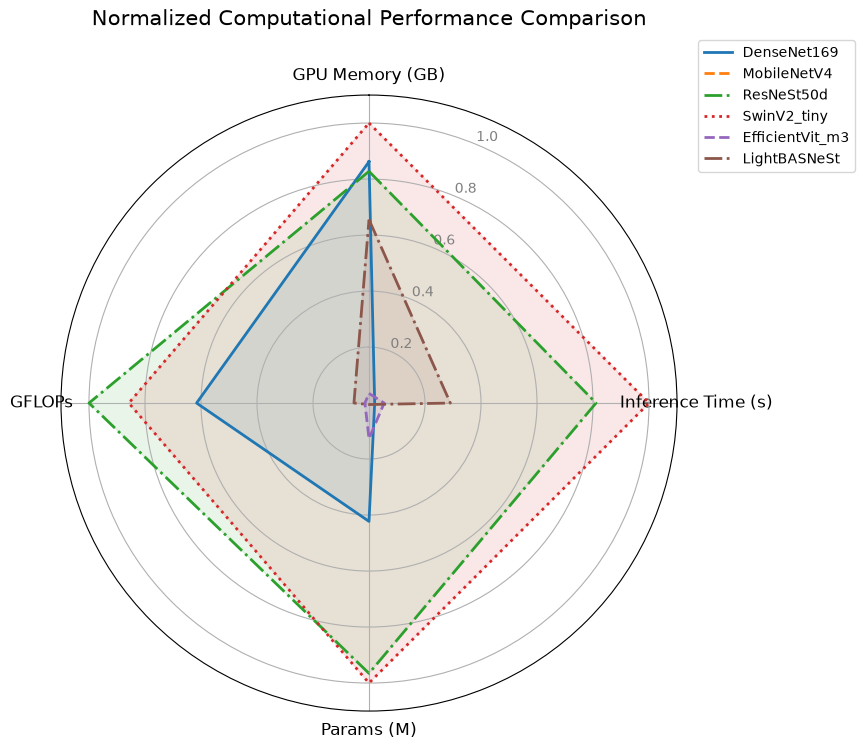

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 1. Define the data
models = ['DenseNet169', 'MobileNetV4', 'ResNeSt50d', 'SwinV2_tiny', 'EfficientVit_m3', 'LightBASNeSt']
labels = ['GPU Memory (GB)', 'Inference Time (s)', 'Params (M)', 'GFLOPs']

# Raw data from the table
data = np.array([
    [2.9, 3.66, 14.15, 3.398],
    [0.4, 3.63, 3.77, 0.190],
    [2.8, 4.83, 27.48, 5.400],
    [3.3, 5.11, 28.33, 4.659],
    [0.5, 3.71, 6.90, 0.266],
    [2.3, 4.06, 3.90, 0.470]
])

# 2. Normalize the data (Min-Max scaling for radar chart visualization)
scaler = MinMaxScaler()
data_normalized = scaler.fit_transform(data)

# 3. Calculate angles for the radar chart
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the loop

# 4. Plot setup
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# 5. Draw one axe per variable and add labels
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
plt.xticks(angles[:-1], labels, color='black', size=12)

# 6. Plot each model's data
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
linestyles = ['-', '--', '-.', ':', '--', '-.']

for i, model_name in enumerate(models):
    values = data_normalized[i].tolist()
    values += values[:1]  # Complete the loop
    ax.plot(angles, values, linewidth=2, linestyle=linestyles[i], label=model_name, color=colors[i])
    ax.fill(angles, values, color=colors[i], alpha=0.1)

# 7. Formatting
plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["0.2", "0.4", "0.6", "0.8", "1.0"], color="grey", size=10)
plt.ylim(0, 1.1)
plt.title('Normalized Computational Performance Comparison', size=15, y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.savefig('D:\\438-ProjectImg\\CPC.png', format='png', dpi=600, bbox_inches='tight', pad_inches=0.2)
plt.show()

# Model performance on External Datasets


Epoch 1/30
------------------------------


Validation Loss: 0.8008, Validation Accuracy: 0.7650
Training Loss: 1.3025, Training Accuracy: 0.5616

Epoch 2/30
------------------------------


Validation Loss: 0.3447, Validation Accuracy: 0.8775
Training Loss: 0.4361, Training Accuracy: 0.8594

Epoch 3/30
------------------------------


Validation Loss: 0.2456, Validation Accuracy: 0.9150
Training Loss: 0.2583, Training Accuracy: 0.9147

Epoch 4/30
------------------------------


Validation Loss: 0.4582, Validation Accuracy: 0.8500
Training Loss: 0.2197, Training Accuracy: 0.9225
Patience Counter: 1/5

Epoch 5/30
------------------------------


...

Validation Loss: 0.0081, Validation Accuracy: 0.9975
Training Loss: 0.0145, Training Accuracy: 0.9950
Patience Counter: 1/5

Epoch 17/30
------------------------------


Validation Loss: 0.0165, Validation Accuracy: 0.9850
Training Loss: 0.0134, Training Accuracy: 0.9959
Patience Counter: 2/5

Epoch 18/30
------------------------------


Validation Loss: 0.0029, Validation Accuracy: 1.0000
Training Loss: 0.0143, Training Accuracy: 0.9944
Patience Counter: 3/5

Epoch 19/30
------------------------------


Validation Loss: 0.0026, Validation Accuracy: 1.0000
Training Loss: 0.0097, Training Accuracy: 0.9975
Patience Counter: 4/5

Epoch 20/30
------------------------------


Validation Loss: 0.0014, Validation Accuracy: 1.0000
Training Loss: 0.0084, Training Accuracy: 0.9981
Patience Counter: 5/5
Early stopping triggered at epoch 20.


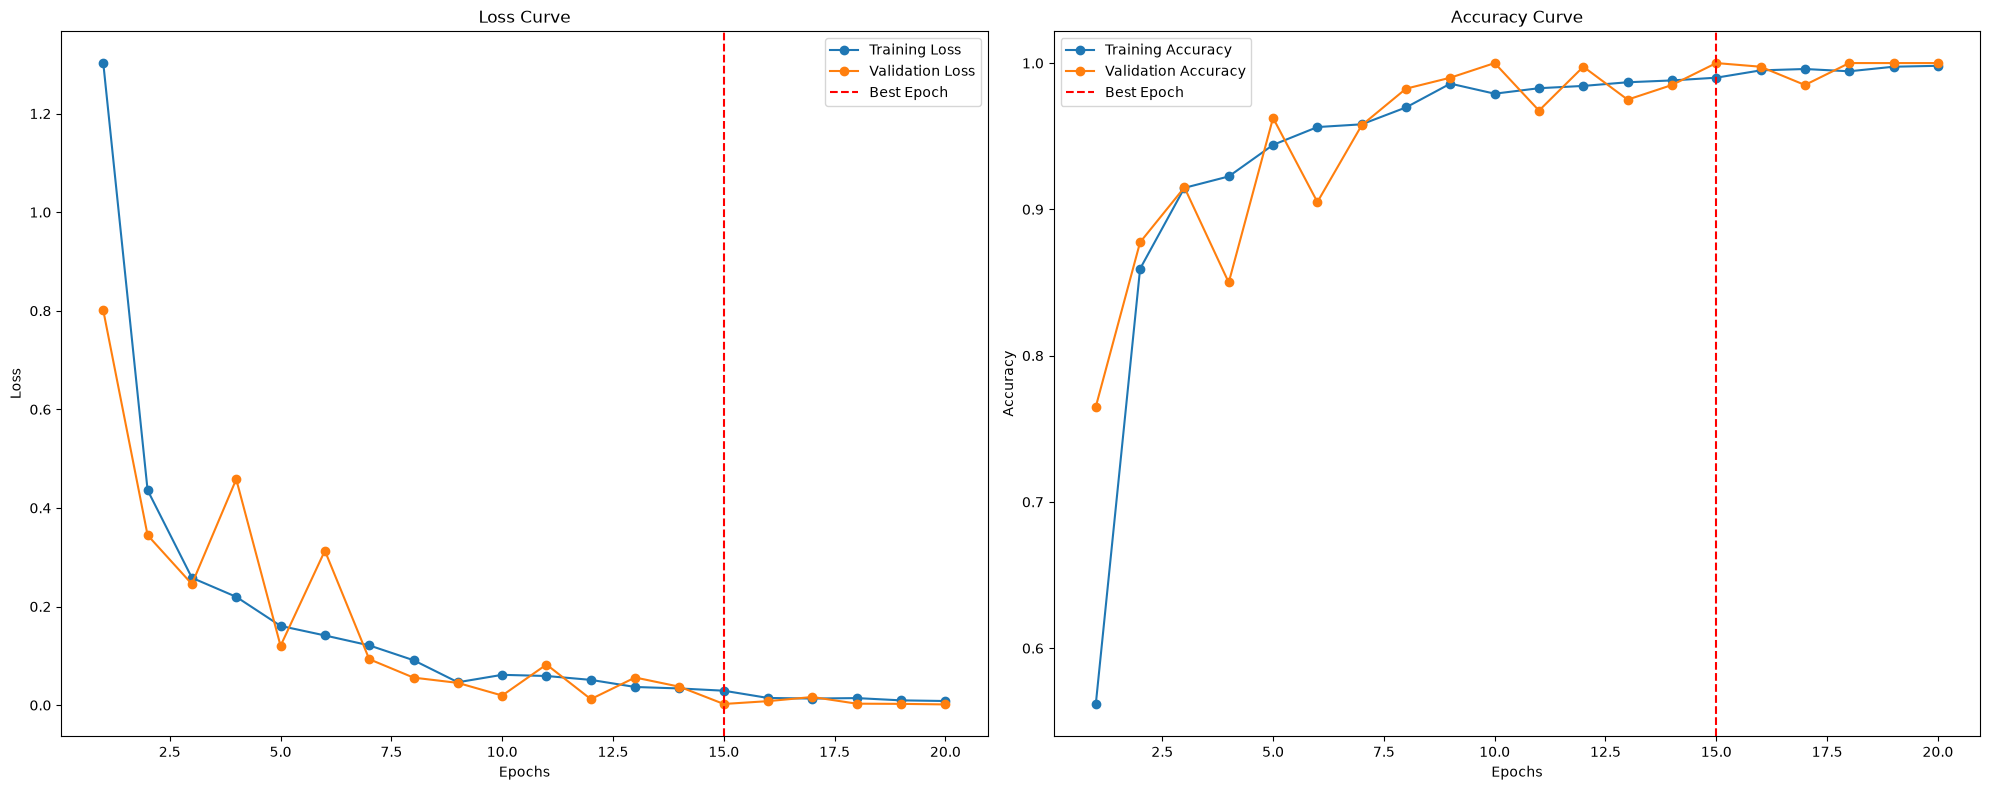


Training Report:
Total training time: 00:08:18
Total epochs run: 20
Best Training Loss: 0.0293 at epoch 15
Best Training Accuracy: 0.9900

Validation Report:
Best Validation Loss: 0.0023 at epoch 15
Best Validation Accuracy: 1.0000
Final Validation Loss: 0.0014
Final Validation Accuracy: 1.0000

Inference Report:
Total Inference Time (Validation only): 00:01:30


In [18]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [19]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.99750
Recall:      0.99750
Precision:   0.99755
F1 Score:    0.99750
MCC:         0.99715
PR AUC:      1.00000
Kappa:       0.99714
Specificity: 0.99964


Accuracy: 0.9975
                  precision    recall  f1-score   support

        Die Back       1.00      1.00      1.00        50
Bacterial Canker       1.00      1.00      1.00        50
     Sooty Mould       0.98      1.00      0.99        50
     Anthracnose       1.00      1.00      1.00        50
  Cutting Weevil       1.00      1.00      1.00        50
         Healthy       1.00      1.00      1.00        50
      Gall Midge       1.00      1.00      1.00        50
  Powdery Mildew       1.00      0.98      0.99        50

        accuracy                           1.00       400
       macro avg       1.00      1.00      1.00       400
    weighted avg       1.00      1.00      1.00       400



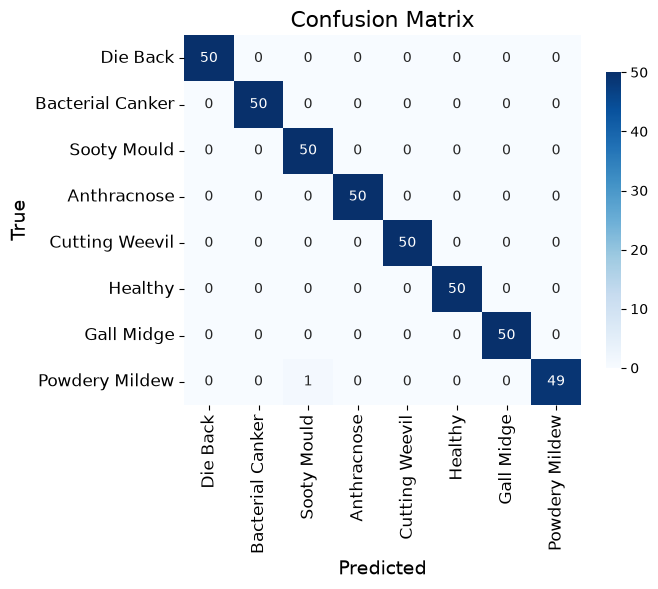

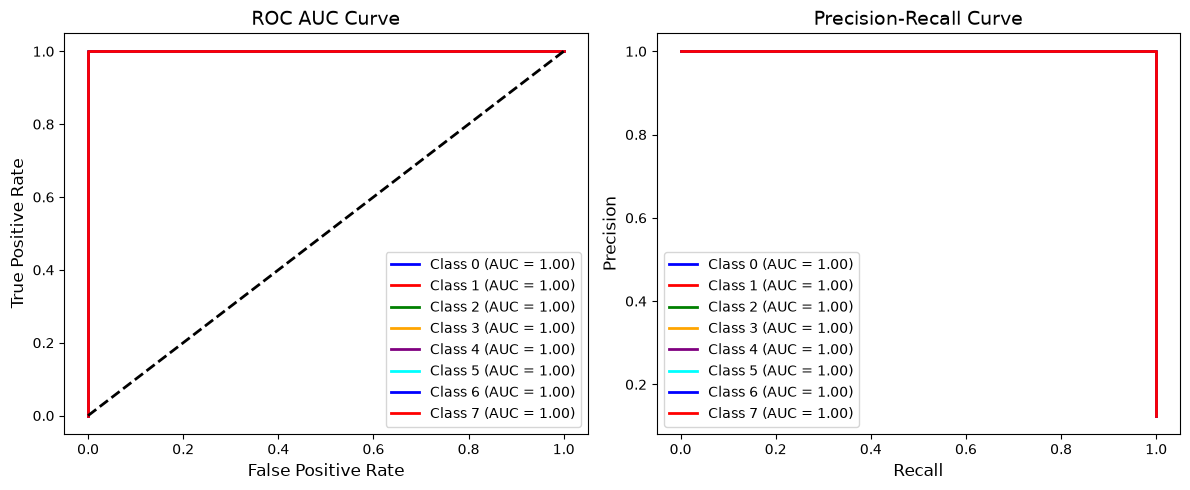

In [20]:
evaluate_model(model, test_loader, label_mapping)


Epoch 1/30
------------------------------


Validation Loss: 0.7428, Validation Accuracy: 0.7436
Training Loss: 0.7774, Training Accuracy: 0.7362

Epoch 2/30
------------------------------


Validation Loss: 0.3639, Validation Accuracy: 0.8755
Training Loss: 0.2960, Training Accuracy: 0.8904

Epoch 3/30
------------------------------


Validation Loss: 0.3306, Validation Accuracy: 0.9048
Training Loss: 0.2102, Training Accuracy: 0.9307

Epoch 4/30
------------------------------


Validation Loss: 0.5269, Validation Accuracy: 0.8095
Training Loss: 0.1333, Training Accuracy: 0.9555
Patience Counter: 1/5

Epoch 5/30
------------------------------


...

Validation Loss: 0.0112, Validation Accuracy: 0.9963
Training Loss: 0.0239, Training Accuracy: 0.9913
Patience Counter: 1/5

Epoch 22/30
------------------------------


Validation Loss: 0.0127, Validation Accuracy: 0.9927
Training Loss: 0.0223, Training Accuracy: 0.9913
Patience Counter: 2/5

Epoch 23/30
------------------------------


Validation Loss: 0.0095, Validation Accuracy: 0.9963
Training Loss: 0.0144, Training Accuracy: 0.9968
Patience Counter: 3/5

Epoch 24/30
------------------------------


Validation Loss: 0.0116, Validation Accuracy: 0.9963
Training Loss: 0.0260, Training Accuracy: 0.9917
Patience Counter: 4/5

Epoch 25/30
------------------------------


Validation Loss: 0.0125, Validation Accuracy: 0.9927
Training Loss: 0.0208, Training Accuracy: 0.9940
Patience Counter: 5/5
Early stopping triggered at epoch 25.


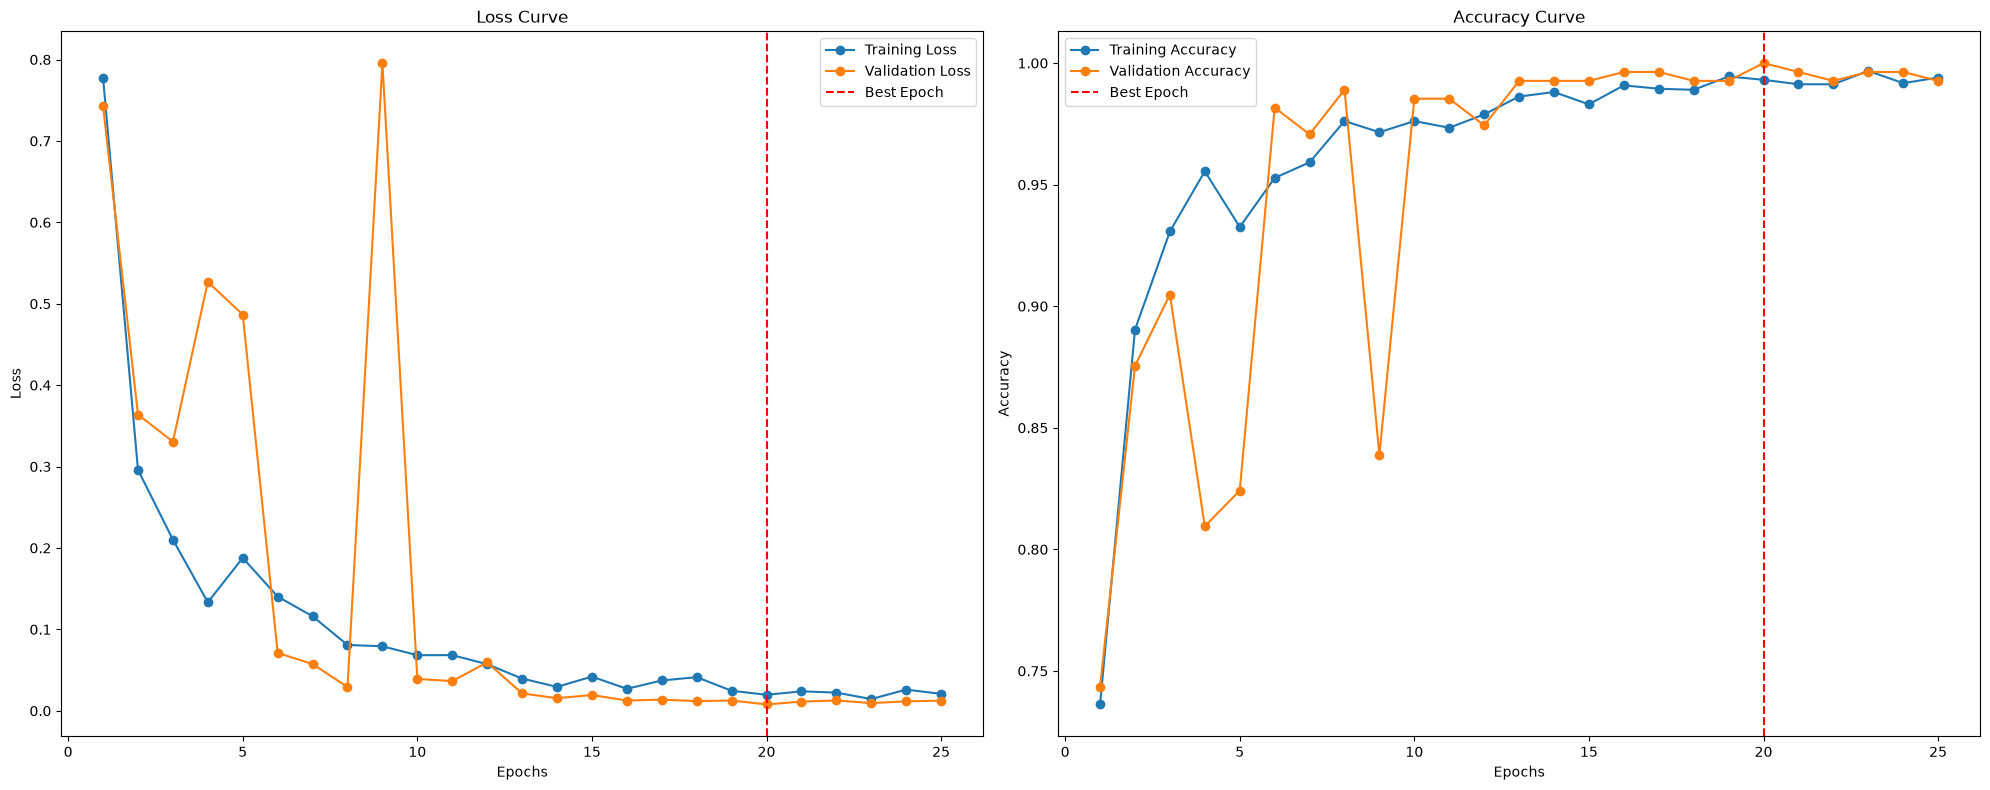


Training Report:
Total training time: 00:08:58
Total epochs run: 25
Best Training Loss: 0.0196 at epoch 20
Best Training Accuracy: 0.9931

Validation Report:
Best Validation Loss: 0.0078 at epoch 20
Best Validation Accuracy: 1.0000
Final Validation Loss: 0.0125
Final Validation Accuracy: 0.9927

Inference Report:
Total Inference Time (Validation only): 00:01:52


In [27]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [28]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98901
Recall:      0.98492
Precision:   0.98849
F1 Score:    0.98666
MCC:         0.98277
PR AUC:      0.99868
Kappa:       0.98275
Specificity: 0.99609


Accuracy: 0.9890
                     precision    recall  f1-score   support

       Downy Mildew       0.98      0.99      0.98        97
     Healthy Leaves       1.00      1.00      1.00       126
Bacterial Leaf Spot       1.00      1.00      1.00        10
     Powdery Mildew       0.97      0.95      0.96        40

           accuracy                           0.99       273
          macro avg       0.99      0.98      0.99       273
       weighted avg       0.99      0.99      0.99       273



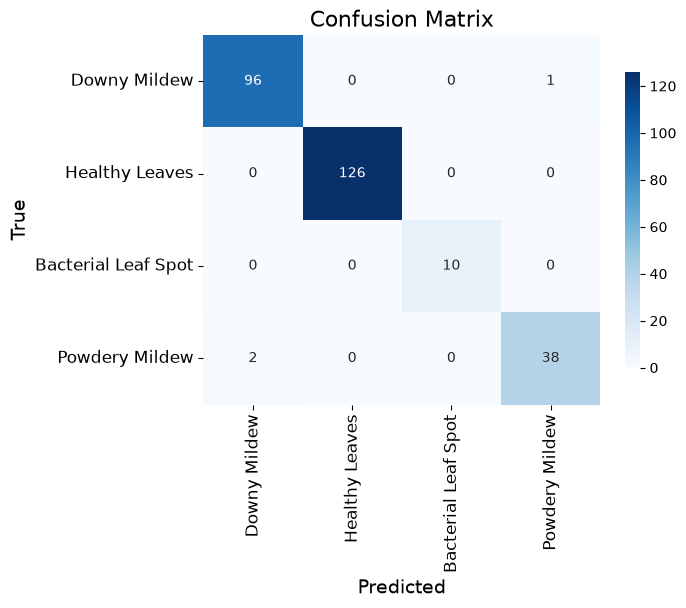

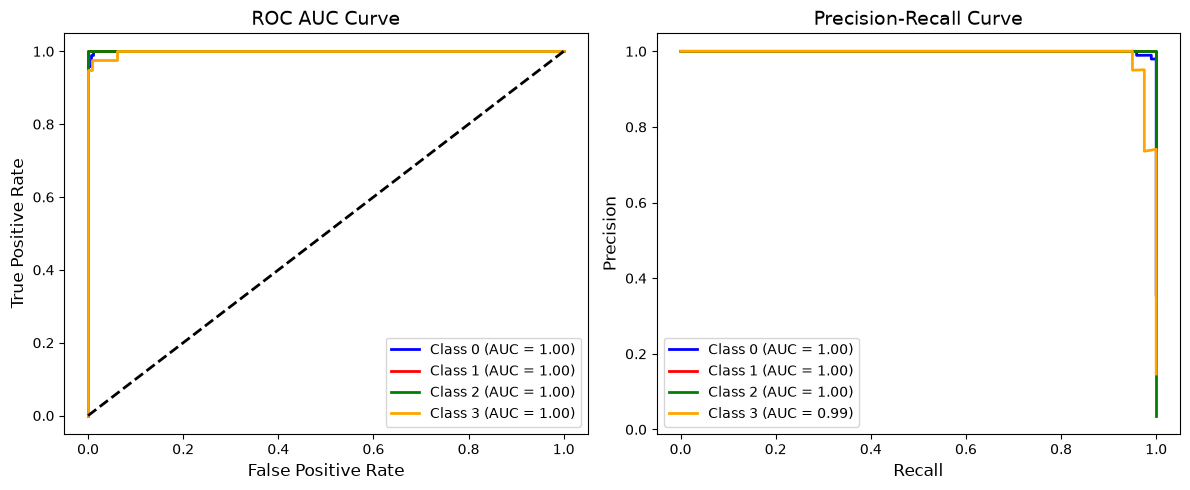

In [29]:
evaluate_model(model, test_loader, label_mapping)


Epoch 1/30
------------------------------


Validation Loss: 1.4295, Validation Accuracy: 0.4808
Training Loss: 1.6950, Training Accuracy: 0.3630

Epoch 2/30
------------------------------


Validation Loss: 1.0079, Validation Accuracy: 0.6238
Training Loss: 1.3093, Training Accuracy: 0.5128

Epoch 3/30
------------------------------


Validation Loss: 0.6908, Validation Accuracy: 0.7503
Training Loss: 0.9562, Training Accuracy: 0.6473

Epoch 4/30
------------------------------


Validation Loss: 0.5732, Validation Accuracy: 0.7927
Training Loss: 0.7411, Training Accuracy: 0.7339

Epoch 5/30
------------------------------


...

Validation Loss: 0.0870, Validation Accuracy: 0.9699
Training Loss: 0.0301, Training Accuracy: 0.9905
Patience Counter: 2/5

Epoch 27/30
------------------------------


Validation Loss: 0.0856, Validation Accuracy: 0.9741
Training Loss: 0.0274, Training Accuracy: 0.9896
Patience Counter: 3/5

Epoch 28/30
------------------------------


Validation Loss: 0.0828, Validation Accuracy: 0.9762
Training Loss: 0.0340, Training Accuracy: 0.9886

Epoch 29/30
------------------------------


Validation Loss: 0.0854, Validation Accuracy: 0.9751
Training Loss: 0.0279, Training Accuracy: 0.9913
Patience Counter: 1/5

Epoch 30/30
------------------------------


Validation Loss: 0.0855, Validation Accuracy: 0.9762
Training Loss: 0.0240, Training Accuracy: 0.9911
Patience Counter: 2/5


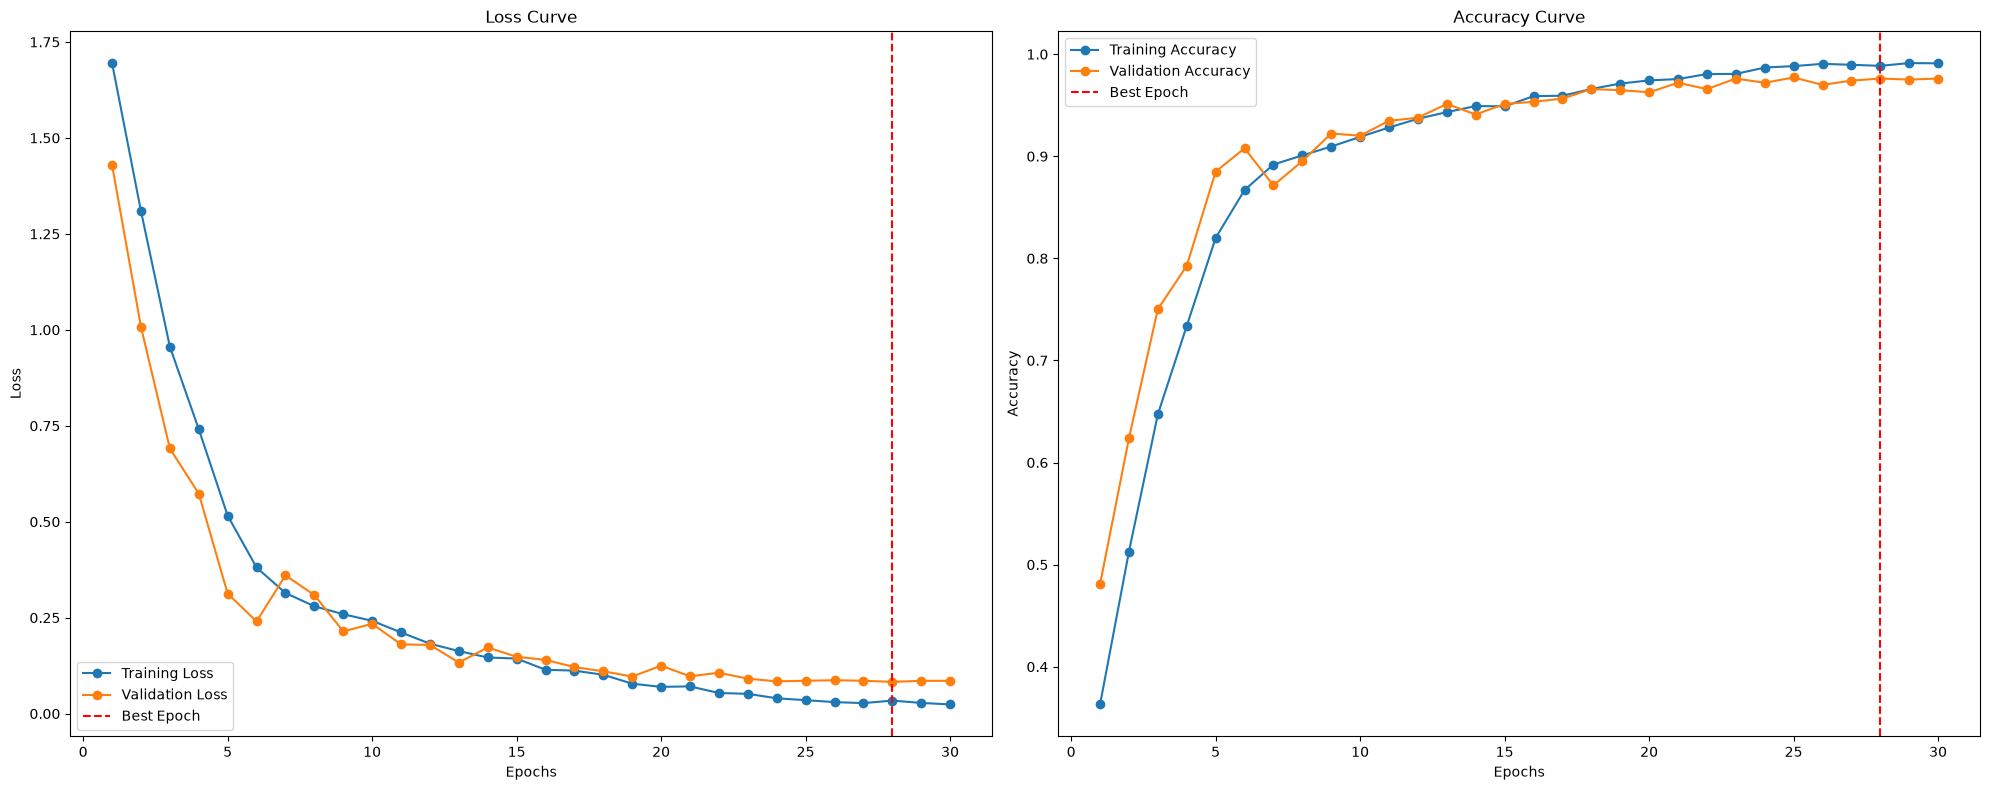


Training Report:
Total training time: 00:24:37
Total epochs run: 30
Best Training Loss: 0.0340 at epoch 28
Best Training Accuracy: 0.9886

Validation Report:
Best Validation Loss: 0.0828 at epoch 28
Best Validation Accuracy: 0.9762
Final Validation Loss: 0.0855
Final Validation Accuracy: 0.9762

Inference Report:
Total Inference Time (Validation only): 00:05:48


In [17]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=10, patience=5, min_delta=0.001)

In [18]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97720
Recall:      0.97435
Precision:   0.97663
F1 Score:    0.97542
MCC:         0.97347
PR AUC:      0.99600
Kappa:       0.97345
Specificity: 0.99667


Accuracy: 0.9772
                        precision    recall  f1-score   support

           target_spot       1.00      0.96      0.98       108
  potassium_deficiency       1.00      1.00      1.00       104
         downey_mildew       0.94      0.95      0.95        65
          soybean_rust       0.98      0.98      0.98       162
      bacterial_blight       0.98      0.96      0.97        49
               healthy       0.96      0.97      0.96       163
               frogeye       0.97      0.98      0.97       154
cercospora_leaf_blight       0.99      0.99      0.99       160

              accuracy                           0.98       965
             macro avg       0.98      0.97      0.98       965
          weighted avg       0.98      0.98      0.98       965



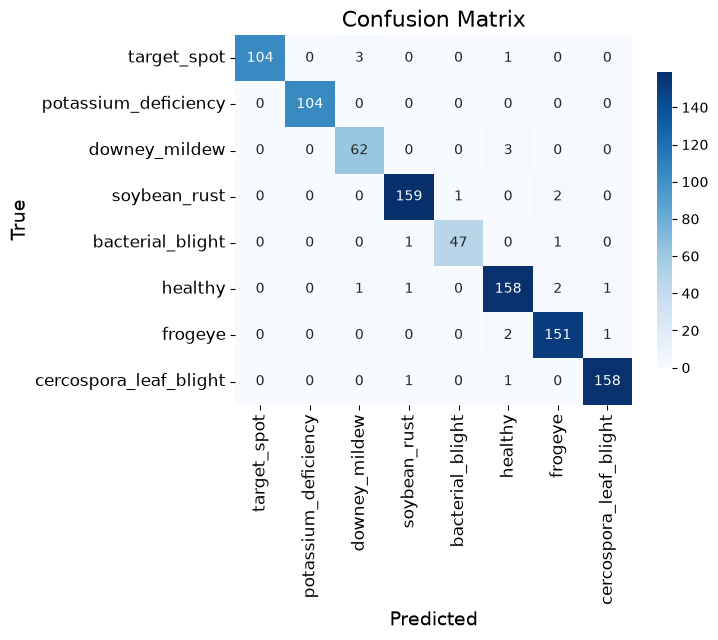

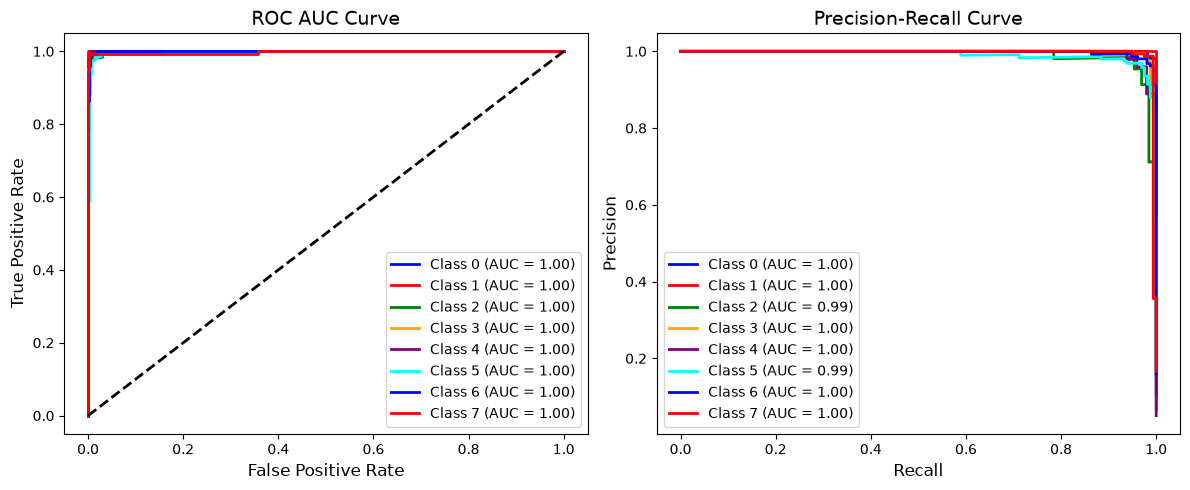

In [19]:
evaluate_model(model, test_loader, label_mapping)